In [ ]:
#Montando o Drive com os dados, utilizo o google drive para armazenar o arquivo csv, mas pode ser usado a pasta dados dentro do colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#parâmetros
CARGO = "Deputado Federal"   # ex.: "GOVERNADOR", "SENADOR", "DEPUTADO FEDERAL"
UF = "SP", "RJ", "MG", "ES"               # None = Brasil inteiro; ou a sigla da UF, ex.: "SP", "BA", "MG"
ANO_ELEICAO = 2026

In [ ]:
#Preparação do ambiente
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('dados', exist_ok=True)

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:,.2f}".format)

nome_uf = UF if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')

arquivo = f"/content/dados/despesas_contratadas_candidatos_2026_BRASIL.csv"
df_dc = pd.read_csv(arquivo, sep=';', encoding='latin1', decimal=',')
print(f"Carregado: {arquivo}  ->  {df_dc.shape[0]} registros, {df_dc.shape[1]} colunas")
# Força a exibição do primeiro DataFrame
display(df_dc.head())

# arquivo de despesas pagas não foi utilizado pela dificuldade em relacionar com o despesas contratadas, e por não ser o alvo nesse momento
nome_uf = UF if UF is not None else 'BRASIL'
arquivo_2 = f"/content/dados/despesas_pagas_candidatos_2026_BRASIL.csv"
df_dp = pd.read_csv(arquivo_2, sep=';', encoding='latin1', decimal=',')
print(f"Carregado: {arquivo_2}  ->  {df_dp.shape[0]} registros, {df_dp.shape[1]} colunas")
display(df_dp.head())

Carregado: /content/dados/despesas_contratadas_candidatos_2026_BRASIL.csv  ->  742385 registros, 53 colunas


,DT_GERACAO,HH_GERACAO,AA_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,ST_TURNO,TP_PRESTACAO_CONTAS,DT_PRESTACAO_CONTAS,SQ_PRESTADOR_CONTAS,SG_UF,SG_UE,NM_UE,NR_CNPJ_PRESTADOR_CONTA,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NR_CPF_CANDIDATO,NR_CPF_VICE_CANDIDATO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,CD_TIPO_FORNECEDOR,DS_TIPO_FORNECEDOR,CD_CNAE_FORNECEDOR,DS_CNAE_FORNECEDOR,NR_CPF_CNPJ_FORNECEDOR,NM_FORNECEDOR,NM_FORNECEDOR_RFB,CD_ESFERA_PART_FORNECEDOR,DS_ESFERA_PART_FORNECEDOR,SG_UF_FORNECEDOR,CD_MUNICIPIO_FORNECEDOR,NM_MUNICIPIO_FORNECEDOR,SQ_CANDIDATO_FORNECEDOR,NR_CANDIDATO_FORNECEDOR,CD_CARGO_FORNECEDOR,DS_CARGO_FORNECEDOR,NR_PARTIDO_FORNECEDOR,SG_PARTIDO_FORNECEDOR,NM_PARTIDO_FORNECEDOR,DS_TIPO_DOCUMENTO,NR_DOCUMENTO,CD_ORIGEM_DESPESA,DS_ORIGEM_DESPESA,SQ_DESPESA,DT_DESPESA,DS_DESPESA,VR_DESPESA_CONTRATADA
0,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,18/09/2026,6818286908,BA,BA,BAHIA,68319412000122,7,Deputado Estadual,50002535027,44124,HARLEY XAVIER NASCIMENTO,-4,-4,44,UNIÃO,UNIÃO BRASIL,0,PESSOA FÍSICA,-1,#NULO,86902998582,FLÁVIA FERREIRA DE LIMA,FLAVIA FERREIRA DE LIMA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,RPA - Recibo de Pagamento Autônomo,0,20800000,Atividades de militância e mobilização de rua,74888635,19/08/2026,PRESTAÇÃO DE SERVIÇO NA FUNÇÃO DE BANDEIREIRA ...,"3,000.00"
1,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,18/09/2026,6818286908,BA,BA,BAHIA,68319412000122,7,Deputado Estadual,50002535027,44124,HARLEY XAVIER NASCIMENTO,-4,-4,44,UNIÃO,UNIÃO BRASIL,0,PESSOA FÍSICA,-1,#NULO,86931067591,MARIA PEREIRA VAZ,MARIA PEREIRA VAZ,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,RPA - Recibo de Pagamento Autônomo,0,20800000,Atividades de militância e mobilização de rua,74888636,19/08/2026,PRESTAÇÃO DE SERVIÇO NA FUNÇÃO DE BANDEIREIRA ...,"3,000.00"
2,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,18/09/2026,6818286908,BA,BA,BAHIA,68319412000122,7,Deputado Estadual,50002535027,44124,HARLEY XAVIER NASCIMENTO,-4,-4,44,UNIÃO,UNIÃO BRASIL,0,PESSOA FÍSICA,-1,#NULO,4264151597,QUELE SOUZA DE OLIVEIRA,QUELE SOUZA DE OLIVEIRA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,RPA - Recibo de Pagamento Autônomo,0,20800000,Atividades de militância e mobilização de rua,74888662,19/08/2026,PRESTAÇÃO DE SERVIÇO NA FUNÇÃO DE BANDEIREIRA ...,"3,000.00"
3,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,18/09/2026,6818286908,BA,BA,BAHIA,68319412000122,7,Deputado Estadual,50002535027,44124,HARLEY XAVIER NASCIMENTO,-4,-4,44,UNIÃO,UNIÃO BRASIL,0,PESSOA FÍSICA,-1,#NULO,8307098513,GLEICIANA PEREIRA SANTA,GLEICIANA PEREIRA SANTANA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,RPA - Recibo de Pagamento Autônomo,0,20800000,Atividades de militância e mobilização de rua,74888750,19/08/2026,PRESTAÇÃO DE SERVIÇO NA FUNÇÃO DE BANDEIREIRA ...,"3,000.00"
4,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,18/09/2026,6818286908,BA,BA,BAHIA,68319412000122,7,Deputado Estadual,50002535027,44124,HARLEY XAVIER NASCIMENTO,-4,-4,44,UNIÃO,UNIÃO BRASIL,0,PESSOA FÍSICA,-1,#NULO,11802052518,JADSON DOS SANTOS SILVA,JADSON DOS SANTOS SILVA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,RPA - Recibo de Pagamento Autônomo,0,20800000,Atividades de militância e mobilização de rua,74888734,19/08/2026,PRESTAÇÃO DE SERVIÇO NA FUNÇÃO DE BANDEIREIRA ...,"3,000.00"


FileNotFoundError: [Errno 2] No such file or directory: '/content/dados/despesas_pagas_candidatos_2026_BRASIL.csv'

In [ ]:

# Rastreabilidade: o próprio TSE grava quando gerou este extrato — assim dá pra saber
# exatamente qual snapshot da base está sendo usado, mesmo que o arquivo mude no futuro.
print(f"Extrato gerado pelo TSE em: {df_dc['DT_GERACAO'].iloc[0]} {df_dc['HH_GERACAO'].iloc[0]}")

# Filtrando Candidado por UF e CARGO
df_dc = df_dc[df_dc['SG_UF'].isin(UF)]
df_dc = df_dc[df_dc['DS_CARGO'] == CARGO].copy()

# Higienizando a Base
df_dc = df_dc[df_dc['SQ_DESPESA'] != -1].copy()


# resumo após o filtro de UF e Cargo)
print()
print(f"CARGO={CARGO!r}  UF={UF!r}  ->  {df_dc.shape[0]} registros")
df_dc.head()

Extrato gerado pelo TSE em: 21/09/2026 04:29:13

CARGO='Deputado Federal'  UF=('SP', 'RJ', 'MG', 'ES')  ->  156977 registros


,DT_GERACAO,HH_GERACAO,AA_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,ST_TURNO,TP_PRESTACAO_CONTAS,DT_PRESTACAO_CONTAS,SQ_PRESTADOR_CONTAS,SG_UF,SG_UE,NM_UE,NR_CNPJ_PRESTADOR_CONTA,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NR_CPF_CANDIDATO,NR_CPF_VICE_CANDIDATO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,CD_TIPO_FORNECEDOR,DS_TIPO_FORNECEDOR,CD_CNAE_FORNECEDOR,DS_CNAE_FORNECEDOR,NR_CPF_CNPJ_FORNECEDOR,NM_FORNECEDOR,NM_FORNECEDOR_RFB,CD_ESFERA_PART_FORNECEDOR,DS_ESFERA_PART_FORNECEDOR,SG_UF_FORNECEDOR,CD_MUNICIPIO_FORNECEDOR,NM_MUNICIPIO_FORNECEDOR,SQ_CANDIDATO_FORNECEDOR,NR_CANDIDATO_FORNECEDOR,CD_CARGO_FORNECEDOR,DS_CARGO_FORNECEDOR,NR_PARTIDO_FORNECEDOR,SG_PARTIDO_FORNECEDOR,NM_PARTIDO_FORNECEDOR,DS_TIPO_DOCUMENTO,NR_DOCUMENTO,CD_ORIGEM_DESPESA,DS_ORIGEM_DESPESA,SQ_DESPESA,DT_DESPESA,DS_DESPESA,VR_DESPESA_CONTRATADA
13,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,17/09/2026,6821810932,SP,SP,SÃO PAULO,68353172000182,6,Deputado Federal,250002535933,2201,JOSE FRANCIMARIO VIEIRA DE MACEDO,-4,-4,22,PL,PARTIDO LIBERAL,0,PESSOA FÍSICA,-1,#NULO,27400209884,Janaina Benjamim Ribeiro,JANAINA BENJAMIM RIBEIRO,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,Outro,110,20800000,Atividades de militância e mobilização de rua,74823529,23/08/2026,"Serviços de campanha, distriuição de material,...","3,016.44"
14,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,17/09/2026,6821810932,SP,SP,SÃO PAULO,68353172000182,6,Deputado Federal,250002535933,2201,JOSE FRANCIMARIO VIEIRA DE MACEDO,-4,-4,22,PL,PARTIDO LIBERAL,0,PESSOA FÍSICA,-1,#NULO,43627733800,Davi Vieira Cassiano,DAVI VIEIRA CASSIANO,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,Outro,225,20800000,Atividades de militância e mobilização de rua,74823338,29/08/2026,"Serviços de campanha, distriuição de material ...","1,600.56"
15,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,17/09/2026,6821810932,SP,SP,SÃO PAULO,68353172000182,6,Deputado Federal,250002535933,2201,JOSE FRANCIMARIO VIEIRA DE MACEDO,-4,-4,22,PL,PARTIDO LIBERAL,0,PESSOA FÍSICA,-1,#NULO,33129009809,Priscila Aguilar de Araujo,PRISCILA AGUIAR DE ARAUJO,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,Outro,234,20800000,Atividades de militância e mobilização de rua,74823576,29/08/2026,"Serviços de campanha, distriuição de material ...","1,600.56"
16,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,17/09/2026,6821810932,SP,SP,SÃO PAULO,68353172000182,6,Deputado Federal,250002535933,2201,JOSE FRANCIMARIO VIEIRA DE MACEDO,-4,-4,22,PL,PARTIDO LIBERAL,0,PESSOA FÍSICA,-1,#NULO,34088523830,Tatiane dos Santos Rosa,TATIANE DOS SANTOS ROSA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,Outro,206,20800000,Atividades de militância e mobilização de rua,74823342,20/08/2026,"Serviços de campanha, distriuição de material ...","2,000.70"
17,21/09/2026,04:29:13,2026,2,Ordinária,6259,Eleições Gerais Estaduais 2026,04/10/2026,1,Relatório Financeiro,17/09/2026,6821810932,SP,SP,SÃO PAULO,68353172000182,6,Deputado Federal,250002535933,2201,JOSE FRANCIMARIO VIEIRA DE MACEDO,-4,-4,22,PL,PARTIDO LIBERAL,0,PESSOA FÍSICA,-1,#NULO,52358159808,Heloisa Cristina da Silva,HELOISA CRISTINA DA SILVA,-1,#NULO,#NULO#,-1,#NULO,-1,-1,-1,#NULO,-1,#NULO,#NULO,Outro,249,20800000,Atividades de militância e mobilização de rua,74823577,22/08/2026,"Serviços de campanha, distriuição de material ...","2,549.04"


In [ ]:
# exibindo todas as colunas
display(pd.DataFrame({"Coluna": df_dc.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,AA_ELEICAO
3,CD_TIPO_ELEICAO
4,NM_TIPO_ELEICAO
5,CD_ELEICAO
6,DS_ELEICAO
7,DT_ELEICAO
8,ST_TURNO
9,TP_PRESTACAO_CONTAS


156977 registros despesas x 53 colunas



,nº de colunas
object,29
int64,23
float64,1


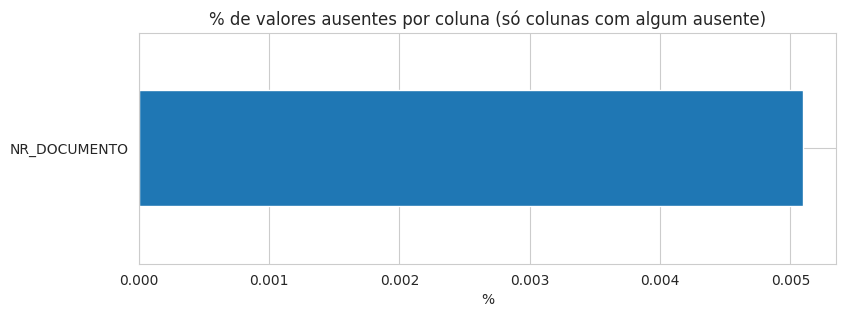

In [ ]:
#exibindo informações das colunas
print(f"{df_dc.shape[0]} registros despesas x {df_dc.shape[1]} colunas\n")
display(df_dc.dtypes.value_counts().rename('nº de colunas'))

faltantes = (df_dc.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

if len(faltantes) > 0:
    plt.figure(figsize=(9, max(3, len(faltantes) * 0.3)))
    faltantes.plot(kind='barh')
    plt.title('% de valores ausentes por coluna (só colunas com algum ausente)')
    plt.xlabel('%')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Nenhuma coluna com valores ausentes.")

In [ ]:
# Removendo Colunas que não serão usadas
df_dc = df_dc.drop(columns=['AA_ELEICAO', 'CD_TIPO_ELEICAO', 'NM_TIPO_ELEICAO', 'CD_ELEICAO', 'DS_ELEICAO','SG_UE','NM_UE','CD_CARGO','DS_CARGO','NR_CPF_VICE_CANDIDATO','NR_PARTIDO','SG_PARTIDO','NM_PARTIDO','NM_FORNECEDOR','CD_ESFERA_PART_FORNECEDOR','DS_ESFERA_PART_FORNECEDOR','CD_MUNICIPIO_FORNECEDOR','NM_MUNICIPIO_FORNECEDOR','NR_CANDIDATO_FORNECEDOR', 'CD_CARGO_FORNECEDOR', 'DS_CARGO_FORNECEDOR', 'NR_PARTIDO_FORNECEDOR', 'SG_PARTIDO_FORNECEDOR', 'NM_PARTIDO_FORNECEDOR'])



In [ ]:
# exibindo todas as colunas após remoção
display(pd.DataFrame({"Coluna": df_dc.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,DT_ELEICAO
3,ST_TURNO
4,TP_PRESTACAO_CONTAS
5,DT_PRESTACAO_CONTAS
6,SQ_PRESTADOR_CONTAS
7,SG_UF
8,NR_CNPJ_PRESTADOR_CONTA
9,SQ_CANDIDATO


In [ ]:
#definindo as colunas categóricas e numéricas
colunas_numericas = [
    'VR_DESPESA_CONTRATADA',
]
colunas_numericas = [c for c in colunas_numericas if c in df_dc.columns]

colunas_categoricas = [
    'DS_TIPO_FORNECEDOR',
    'DS_ORIGEM_DESPESA',
]
colunas_categoricas = [c for c in colunas_categoricas if c in  df_dc.columns]

print("Numéricas:")
display(pd.DataFrame({"Coluna": colunas_numericas}))
print("Categóricas:")
display(pd.DataFrame({"Coluna": colunas_categoricas}))

Numéricas:


,Coluna
0,VR_DESPESA_CONTRATADA


Categóricas:


,Coluna
0,DS_TIPO_FORNECEDOR
1,DS_ORIGEM_DESPESA


Variáveis numéricas: distribuição e outliers


In [ ]:
display(df_dc[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
VR_DESPESA_CONTRATADA,"156,977.00","3,879.15","12,922.23",0.00,800.00,"1,621.00","3,000.00","1,352,000.00"


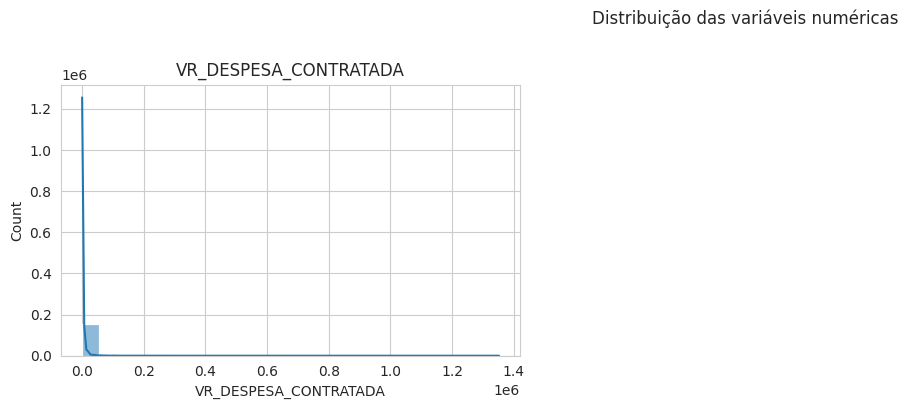

In [ ]:
n = len(colunas_numericas)
ncols = 3
nrows = -(-n // ncols)  # arredonda pra cima

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.histplot(df_dc[col], bins=25, ax=axes[i], kde='true')
    axes[i].set_title(col)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribuição das variáveis numéricas', y=1.01)
plt.tight_layout()
plt.show()

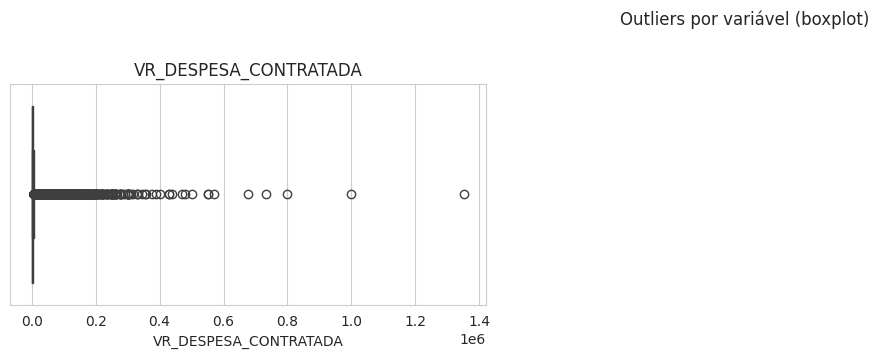

In [ ]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.boxplot(x=df_dc[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Outliers por variável (boxplot)', y=1.01)
plt.tight_layout()
plt.show()

### Quantificando os outliers (regra do IQR)

O boxplot mostra visualmente; esta tabela quantifica: quantos registros  (despesas) ficam fora do intervalo `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` na variável Despesa.

In [ ]:
linhas = []
for col in colunas_numericas:
    Q1, Q3 = df_dc[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df_dc[col] < lim_inf) | (df_dc[col] > lim_sup)).sum()
    linhas.append({
        'variavel': col, 'limite_inferior': lim_inf, 'limite_superior': lim_sup,
        'qtd_outliers': n_outliers, 'pct_outliers': round(100 * n_outliers / len(df_dc), 1),
    })

pd.DataFrame(linhas).sort_values('pct_outliers', ascending=False)

,variavel,limite_inferior,limite_superior,qtd_outliers,pct_outliers
0,VR_DESPESA_CONTRATADA,"-2,500.00","6,300.00",16643,10.60


## Variáveis categóricas: contagens e proporções

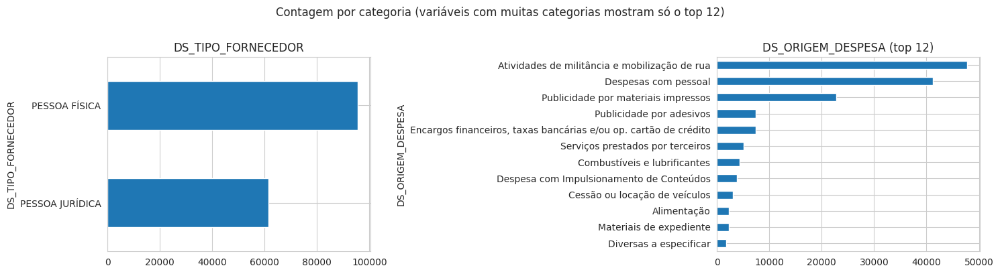

In [ ]:
def plot_categorica(ax, coluna, top_n=12):
    contagem = df_dc[coluna].value_counts().head(top_n)
    contagem.plot(kind='barh', ax=ax)
    ax.set_title(coluna + (f' (top {top_n})' if df_dc[coluna].nunique() > top_n else ''))
    ax.invert_yaxis()

n = len(colunas_categoricas)
ncols = 2
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas):
    plot_categorica(axes[i], col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Contagem por categoria (variáveis com muitas categorias mostram só o top 12)', y=1.01)
plt.tight_layout()
plt.show()

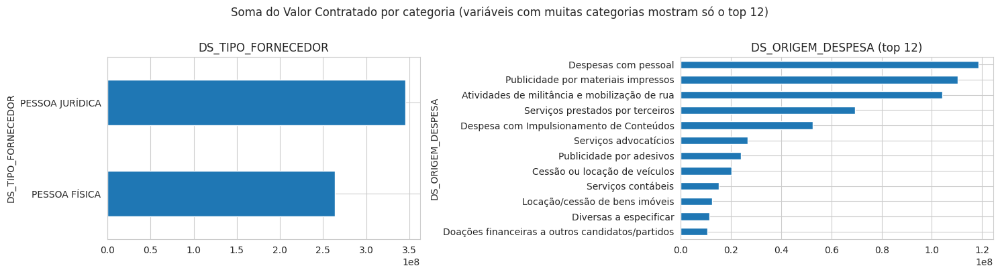

In [ ]:
def plot_soma_categorica(ax, coluna, top_n=12):
    # Agrupa pela categoria, soma os valores e pega os 12 maiores já ordenados
    soma = df_dc.groupby(coluna)['VR_DESPESA_CONTRATADA'].sum().nlargest(top_n)

    # Plota o gráfico de barras horizontais
    soma.plot(kind='barh', ax=ax)

    # Configura o título e inverte o eixo Y para a maior barra ficar no topo
    ax.set_title(coluna + (f' (top {top_n})' if df_dc[coluna].nunique() > top_n else ''))
    ax.invert_yaxis()

n = len(colunas_categoricas)
ncols = 2
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas):
    plot_soma_categorica(axes[i], col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Soma do Valor Contratado por categoria (variáveis com muitas categorias mostram só o top 12)', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# exibindo todas as colunas
display(pd.DataFrame({"Coluna": df_dc.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,DT_ELEICAO
3,ST_TURNO
4,TP_PRESTACAO_CONTAS
5,DT_PRESTACAO_CONTAS
6,SQ_PRESTADOR_CONTAS
7,SG_UF
8,NR_CNPJ_PRESTADOR_CONTA
9,SQ_CANDIDATO


## Criando o DataFrame  e Exportando o CSV



In [ ]:
#Criando o DataFrame
df_dc_final = df_dc[['DT_GERACAO', 'HH_GERACAO', 'SQ_CANDIDATO',	'NR_CANDIDATO', 'DS_ORIGEM_DESPESA',	'SQ_DESPESA', 'DT_DESPESA', 'DS_DESPESA', 'VR_DESPESA_CONTRATADA']]

#caso queira fazer algum filtro final
#df_dc_final = df_dc_final[df_dc_final['VR_DESPESA_CONTRATADA'].between(0, 100000)].copy()

print(df_dc_final.shape)
df_dc_final[['DT_GERACAO', 'HH_GERACAO', 'SQ_CANDIDATO',	'NR_CANDIDATO', 'DS_ORIGEM_DESPESA',	'SQ_DESPESA', 'DT_DESPESA', 'DS_DESPESA', 'VR_DESPESA_CONTRATADA']].sample(min(5, len(df_dc_final )))

(156977, 9)


,DT_GERACAO,HH_GERACAO,SQ_CANDIDATO,NR_CANDIDATO,DS_ORIGEM_DESPESA,SQ_DESPESA,DT_DESPESA,DS_DESPESA,VR_DESPESA_CONTRATADA
12304,21/09/2026,04:29:13,250002537968,1045,Despesas com pessoal,74589917,06/09/2026,PRESTAÇÃO DE SERVIÇOS DE MOBILIZAÇÃO DE RUA NA...,"1,600.00"
719107,21/09/2026,04:29:13,130002534429,3000,"Encargos financeiros, taxas bancárias e/ou op....",74999539,08/09/2026,Tarifa Pix Enviado,0.50
713524,21/09/2026,04:29:13,130002543720,4000,Atividades de militância e mobilização de rua,74564474,09/09/2026,AGENTE DE MOBILIZAÇÃO E APOIO DE CAMPANHA,"2,000.00"
102321,21/09/2026,04:29:13,130002537202,1077,Atividades de militância e mobilização de rua,75056156,04/09/2026,CONTRATO DE PRESTACaO DE SERVICO CABO ELEITORAL,800.00
160827,21/09/2026,04:29:13,250002548513,1201,Diversas a especificar,74233307,02/09/2026,"BANDEIRA EM OXFORD 1,40 X 1,00",150.00


In [ ]:
#nome_uf = UF if UF is not None else 'BRASIL'
#nome_cargo = CARGO.replace(' ', '_')
#arquivo_saida = f"dados/despesas_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

#df_dc_final.to_csv(arquivo_saida, index=False)
#print(f"Dataset salvo em: {arquivo_saida}  ({df_dc_final.shape[0]} registros, {df_dc_final.shape[1]} colunas)")

Criando o DataFrame Final - Agrupado e Exportando o CSV

In [ ]:
df_dc_agrupado = df_dc.groupby(['SQ_CANDIDATO', 'DS_ORIGEM_DESPESA'])['VR_DESPESA_CONTRATADA'].sum().reset_index()
print(df_dc_agrupado.shape)
df_dc_agrupado[['SQ_CANDIDATO',	'DS_ORIGEM_DESPESA',	'VR_DESPESA_CONTRATADA']].sample(min(5, len(df_dc_final )))


(13163, 3)


,SQ_CANDIDATO,DS_ORIGEM_DESPESA,VR_DESPESA_CONTRATADA
2696,130002542018,Serviços próprios prestados por terceiros,"3,500.00"
570,80002549398,Serviços prestados por terceiros,"99,794.00"
5881,190002539358,Despesa com Impulsionamento de Conteúdos,"12,000.00"
12636,250002548499,Publicidade por materiais impressos,"3,850.00"
7726,250002530127,Publicidade por materiais impressos,"17,065.95"


In [ ]:
nome_uf = UF if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo_saida = f"dados/despesas_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

df_dc_agrupado.to_csv(arquivo_saida, index=False)
print(f"Dataset salvo em: {arquivo_saida}  ({df_dc_agrupado.shape[0]} registros, {df_dc_agrupado.shape[1]} colunas)")

Dataset salvo em: dados/despesas_Deputado_Federal_('SP', 'RJ', 'MG', 'ES')_2026.csv  (13163 registros, 3 colunas)


# Fase 0 — Preparação de Dados: Candidatos 2026 (TSE)

Este notebook baixa e prepara os dados de candidatos das Eleições 2026, e salva um **dataset limpo** que todas as fases seguintes (1 a 4) vão reutilizar — assim ninguém precisa baixar e limpar os dados de novo em cada notebook.

## Configuração

Ajuste as três variáveis abaixo antes de rodar. É a **única coisa que muda** entre a análise do professor (Brasil, Governador) e o trabalho de vocês (um cargo, uma UF).

In [ ]:
CARGO = "DEPUTADO FEDERAL"   # ex.: "GOVERNADOR", "SENADOR", "DEPUTADO FEDERAL"
UF = "SP", "RJ", "MG", "ES"               # None = Brasil inteiro; ou a sigla da UF, ex.: "SP", "BA", "MG"
ANO_ELEICAO = 2026

> **Para os alunos:** troquem `CARGO` para `"SENADOR"` ou `"DEPUTADO FEDERAL"` e `UF` para a sigla do estado do seu trabalho (ex.: `UF = "PE"`). O resto do notebook não muda.

> **Sobre "congelar" a versão dos dados:** o arquivo do TSE pode ser atualizado por eles a qualquer momento (novas candidaturas, correções, impugnações). Para não ficar refém disso, os zips baixados manualmente ficam parados em `dados/` e só mudam quando você baixar uma versão nova de propósito. O que fica **versionado no git** é o resultado desta fase (`dados/*.csv`) — depois de rodar e conferir, faça `git commit` desse CSV: esse commit *é* a versão congelada que a turma toda vai usar.

## 1) Preparação do ambiente

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

os.makedirs('dados', exist_ok=True)

## 2) Obter os dados

O download automático pelo CDN do TSE é bloqueado por um firewall (Akamai) que rejeita requisições que não vêm de um navegador de verdade — isso acontece tanto no Colab quanto localmente, então não vale a pena automatizar. **O fluxo é manual:**

1. Baixe os dois arquivos pelo navegador:
   - Candidatos: `https://cdn.tse.jus.br/estatistica/sead/odsele/consulta_cand/consulta_cand_2026.zip`
   - Bens: `https://cdn.tse.jus.br/estatistica/sead/odsele/bem_candidato/bem_candidato_2026.zip`
2. Salve os dois **dentro da pasta `dados/`**, com esses nomes exatos:
   - `dados/consulta_cand_2026.zip`
   - `dados/bem_candidato_2026.zip`
3. Rode as células abaixo — elas conferem se os arquivos estão no lugar certo e descompactam.

In [ ]:
ZIP_CAND = f"dados/consulta_cand_{2026}.zip"
ZIP_BEM = f"dados/bem_candidato_{2026}.zip"
#ZIP_CONTAS = f"dados/prestacao_de_contas_eleitorais_candidatos_{2026}.zip"

def conferir_zip(caminho):
    if not os.path.exists(caminho):
        raise FileNotFoundError(
            f"Não encontrei {caminho}. Baixe o arquivo pelo navegador e salve exatamente nesse caminho "
            "(veja os links na célula de markdown acima)."
        )
    if not zipfile.is_zipfile(caminho):
        raise ValueError(f"{caminho} existe, mas não é um .zip válido — baixe de novo pelo navegador.")
    tamanho_mb = os.path.getsize(caminho) / (1024 * 1024)
    print(f"OK: {caminho} ({tamanho_mb:.1f} MB)")

def descompactar(nome_arquivo_zip, destino):
    with zipfile.ZipFile(nome_arquivo_zip, 'r') as zip_ref:
        zip_ref.extractall(destino)
    print(f"Descompactado em {destino}")

conferir_zip(ZIP_CAND)
conferir_zip(ZIP_BEM)
#conferir_zip(ZIP_CONTAS)

OK: dados/consulta_cand_2026.zip (3.0 MB)
OK: dados/bem_candidato_2026.zip (3.6 MB)


In [ ]:
descompactar(ZIP_CAND, './files_cand')
descompactar(ZIP_BEM, './files_bem')
#descompactar(ZIP_CONTAS, './files_contas')

Descompactado em ./files_cand
Descompactado em ./files_bem


## 3) Filtrar candidatos (CARGO + UF)

In [ ]:
df = pd.read_csv(f'./files_cand/consulta_cand_{ANO_ELEICAO}_BRASIL.csv', sep=';', encoding='latin-1')

print(f"Extrato gerado pelo TSE em: {df['DT_GERACAO'].iloc[0]} {df['HH_GERACAO'].iloc[0]}")

# [ALTERAÇÃO] filtro por UF com .isin (funciona com None, string ou lista/tupla)
if UF is not None:
    ufs = list(UF) if isinstance(UF, (list, tuple)) else [UF]
    df_filtrado = df[df['SG_UF'].isin(ufs)]
else:
    df_filtrado = df.copy()

print("\nCargos disponíveis:")
print(df_filtrado.DS_CARGO.value_counts())

dfCargo = df_filtrado[df_filtrado['DS_CARGO'] == CARGO].copy()  # [ALTERAÇÃO] filtrar em df_filtrado, não em df

dfCargoFinal = dfCargo.loc[dfCargo.groupby('SQ_CANDIDATO')['NR_TURNO'].idxmax()]

print()
print(f"CARGO={CARGO!r}  UF={UF!r}  ->  {dfCargoFinal.shape[0]} candidatos")
dfCargoFinal[['SQ_CANDIDATO', 'NM_CANDIDATO', 'SG_UF', 'SG_PARTIDO', 'DT_NASCIMENTO']].head()

Extrato gerado pelo TSE em: 23/08/2026 19:30:42

Cargos disponíveis:
DS_CARGO
DEPUTADO ESTADUAL    3994
DEPUTADO FEDERAL     2793
1º SUPLENTE            63
2º SUPLENTE            60
SENADOR                60
VICE-GOVERNADOR        33
GOVERNADOR             32
Name: count, dtype: int64

CARGO='DEPUTADO FEDERAL'  UF=('SP', 'RJ', 'MG', 'ES')  ->  2793 candidatos


,SQ_CANDIDATO,NM_CANDIDATO,SG_UF,SG_PARTIDO,DT_NASCIMENTO
7137,80002531643,JOÃO BATISTA DE ASSIS,ES,NOVO,23/03/1974
1986,80002531644,FABÍOLA SAQUETTO DI TOMMASO,ES,NOVO,06/08/1977
17538,80002531645,AILANA REGINA PELISSARI SIMONELLI MOREIRA,ES,NOVO,28/11/1978
9686,80002531646,JÚLIO CÉSAR COSTA CAIADO,ES,NOVO,17/04/1959
17539,80002531647,LEONARDO RODRIGO NASCIMENTO,ES,NOVO,14/11/1979


## 4) Patrimônio declarado (bens)

In [ ]:
dfBem = pd.read_csv('./files_bem/bem_candidato_%d_BRASIL.csv' % ANO_ELEICAO, sep=';', encoding='latin-1')
dfBem['VR_BEM_CANDIDATO'] = dfBem['VR_BEM_CANDIDATO'].str.replace(',', '.').astype(float)

def categorize_assets(asset):
    a = asset.lower()
    if 'veículo' in a or 'moto' in a or 'aeronave' in a or 'embarcação' in a:
        return 'BENS MÓVEIS'
    elif 'casa' in a or 'terreno' in a or 'apartamento' in a or 'prédio' in a or 'loja' in a or 'terra nua' in a:
        return 'BENS IMÓVEIS'
    elif 'poupança' in a or 'renda fixa' in a or 'cdb' in a or 'rdb' in a:
        return 'INVESTIMENTOS RENDA FIXA'
    elif 'ações' in a or 'fundo' in a or 'investimento' in a or 'mercado' in a:
        return 'INVESTIMENTOS RENDA VARIÁVEL'
    elif 'dinheiro' in a or 'depósito bancário' in a or 'numerário' in a:
        return 'DINHEIRO'
    else:
        return 'OUTROS BENS'

dfBem['Categoria_BEM'] = dfBem['DS_TIPO_BEM_CANDIDATO'].apply(categorize_assets)

dfBem_pivot = dfBem.pivot_table(
    index='SQ_CANDIDATO', columns='Categoria_BEM', values='VR_BEM_CANDIDATO', aggfunc='sum'
)
dfBem_pivot.fillna(0, inplace=True)
dfBem_pivot['Total_Bens'] = dfBem_pivot.sum(axis=1)
dfBem_pivot['Total_Bens_Log'] = np.log1p(dfBem_pivot['Total_Bens'])

dfBem_pivot[['Total_Bens', 'Total_Bens_Log']].describe()

Categoria_BEM,Total_Bens,Total_Bens_Log
count,1.373000e+04,13730.000000
mean,2.496684e+06,12.693722
std,2.771848e+07,2.044055
min,0.000000e+00,0.000000
25%,1.165086e+05,11.665729
50%,4.014611e+05,12.902868
75%,1.130000e+06,13.937729
max,2.075000e+09,21.453227


In [ ]:
# ============================================================
# [ALTERAÇÃO] DESPESAS DE CAMPANHA (contratadas, já filtradas)
# Arquivo gerado no notebook 05 / preparação de despesas
# ============================================================

# Caminho do CSV que você exportou (ajuste se o nome/pasta for outro)
ARQUIVO_GASTOS = "dados/despesas_Deputado_Federal_('SP', 'RJ', 'MG', 'ES')_2026.csv"
# Alternativa, se estiver na pasta do Colab:
# ARQUIVO_GASTOS = "despesas_Deputado_Federal_('SP', 'RJ', 'MG', 'ES')_2026.csv"

df_desp = pd.read_csv(ARQUIVO_GASTOS)

# Garante número
df_desp["VR_DESPESA_CONTRATADA"] = pd.to_numeric(
    df_desp["VR_DESPESA_CONTRATADA"], errors="coerce"
).fillna(0)

# Total por candidato (várias linhas de origem → uma linha)
gastos = (
    df_desp
    .groupby("SQ_CANDIDATO", as_index=False)["VR_DESPESA_CONTRATADA"]
    .sum()
    .rename(columns={"VR_DESPESA_CONTRATADA": "Total_Gasto_Campanha"})
)
gastos["Total_Gasto_Campanha_Log"] = np.log1p(gastos["Total_Gasto_Campanha"])

print(f"Candidatos com despesa: {len(gastos)}")
print(
    "Interseção com candidatos filtrados:",
    len(set(gastos["SQ_CANDIDATO"]) & set(dfCargoFinal["SQ_CANDIDATO"]))
)
print(gastos.head())

Candidatos com despesa: 2033
Interseção com candidatos filtrados: 2028
   SQ_CANDIDATO  Total_Gasto_Campanha  Total_Gasto_Campanha_Log
0   80002531644               3750.00                  8.229778
1   80002531645               5000.00                  8.517393
2   80002531646                  9.95                  2.393339
3   80002531647               5275.19                  8.570960
4   80002531648               8985.00                  9.103423


In [ ]:
print(
    "Interseção com candidatos filtrados:",
    len(set(gastos["SQ_CANDIDATO"]) & set(dfCargoFinal["SQ_CANDIDATO"]))
)

Interseção com candidatos filtrados: 2028


## 5) Juntar tudo, calcular idade e limpar

A idade mínima elegível **depende do cargo** (regra constitucional) — por isso o filtro de idade é montado a partir de `CARGO`, não fixo.

In [ ]:
# Bloco 8: Unificação dos dados, cálculo de idade e inclusão dos gastos (com alterações)
IDADE_MINIMA_POR_CARGO = {
    'PRESIDENTE': 35, 'VICE-PRESIDENTE': 35,
    'GOVERNADOR': 30, 'VICE-GOVERNADOR': 30,
    'SENADOR': 35,
    'DEPUTADO FEDERAL': 21, 'DEPUTADO ESTADUAL': 21, 'DEPUTADO DISTRITAL': 21,
    'PREFEITO': 21, 'VICE-PREFEITO': 21,
    'VEREADOR': 18,
}
idade_minima = IDADE_MINIMA_POR_CARGO.get(CARGO, 18)
print(f"Idade mínima elegível para {CARGO}: {idade_minima} anos")

dfCandBem = dfCargoFinal.merge(dfBem_pivot, on='SQ_CANDIDATO', how='left')

# [ALTERAÇÃO]: Realização do merge do DataFrame de gastos de campanha com dfCandBem
dfCandBem = dfCandBem.merge(gastos, on='SQ_CANDIDATO', how='left')

# [ALTERAÇÃO]: Tratamento dos valores nulos resultantes do merge dos gastos de campanha
dfCandBem['Total_Gasto_Campanha'] = dfCandBem['Total_Gasto_Campanha'].fillna(0)
dfCandBem['Total_Gasto_Campanha_Log'] = dfCandBem['Total_Gasto_Campanha_Log'].fillna(0)

dfCandBem['Total_Bens'] = dfCandBem['Total_Bens'].fillna(0)
dfCandBem['Total_Bens_Log'] = dfCandBem['Total_Bens_Log'].fillna(0)

dfCandBem['DT_ELEICAO'] = pd.to_datetime(dfCandBem['DT_ELEICAO'], format='%d/%m/%Y')
dfCandBem['DT_NASCIMENTO'] = pd.to_datetime(dfCandBem['DT_NASCIMENTO'], format='%d/%m/%Y')
dfCandBem['IDADE'] = (dfCandBem['DT_ELEICAO'] - dfCandBem['DT_NASCIMENTO']).dt.days // 365

antes = dfCandBem.shape[0]
dfCandBem = dfCandBem[dfCandBem['IDADE'].between(idade_minima, 100)].copy()
print(f"Candidatos removidos por idade inválida: {antes - dfCandBem.shape[0]}")

print(dfCandBem.shape)

# [ALTERAÇÃO]: Exibição de amostragem contendo as colunas de gastos de campanha adicionadas
dfCandBem[['NM_CANDIDATO', 'SG_UF', 'IDADE', 'Total_Bens', 'Total_Gasto_Campanha', 'Total_Gasto_Campanha_Log']].sample(min(5, len(dfCandBem)))

# ============================================================
# UNIFICAÇÃO DOS DADOS (MERGE FINAL DA FASE 0)
# ============================================================

df_final = dfCargoFinal.merge(
    dfBem_pivot,
    left_on="SQ_CANDIDATO",
    right_index=True,
    how="left"
)

df_final = df_final.merge(
    gastos,
    on="SQ_CANDIDATO",
    how="left"
)

colunas_bens = list(dfBem_pivot.columns)
for col in colunas_bens:
    if col in df_final.columns:
        df_final[col] = df_final[col].fillna(0)

df_final["Total_Gasto_Campanha"] = df_final["Total_Gasto_Campanha"].fillna(0)
df_final["Total_Gasto_Campanha_Log"] = df_final["Total_Gasto_Campanha_Log"].fillna(0)

print(f"Merge concluído com sucesso! Total de candidatos processados: {len(df_final)}")

Idade mínima elegível para DEPUTADO FEDERAL: 21 anos
Candidatos removidos por idade inválida: 2
(2791, 61)
Merge concluído com sucesso! Total de candidatos processados: 2793


In [ ]:
IDADE_MINIMA_POR_CARGO = {
    'PRESIDENTE': 35, 'VICE-PRESIDENTE': 35,
    'GOVERNADOR': 30, 'VICE-GOVERNADOR': 30,
    'SENADOR': 35,
    'DEPUTADO FEDERAL': 21, 'DEPUTADO ESTADUAL': 21, 'DEPUTADO DISTRITAL': 21,
    'PREFEITO': 21, 'VICE-PREFEITO': 21,
    'VEREADOR': 18,
}
idade_minima = IDADE_MINIMA_POR_CARGO.get(CARGO, 18)
print(f"Idade mínima elegível para {CARGO}: {idade_minima} anos")

dfCandBem = dfCargoFinal.merge(dfBem_pivot, on="SQ_CANDIDATO", how="left")

# left join: quem não tem despesa fica NaN → vira 0
dfCandBem = dfCandBem.merge(gastos, on="SQ_CANDIDATO", how="left")

dfCandBem["Total_Gasto_Campanha"] = dfCandBem["Total_Gasto_Campanha"].fillna(0)
dfCandBem["Total_Gasto_Campanha_Log"] = np.log1p(dfCandBem["Total_Gasto_Campanha"])

dfCandBem["Total_Bens"] = dfCandBem["Total_Bens"].fillna(0)
dfCandBem["Total_Bens_Log"] = dfCandBem["Total_Bens_Log"].fillna(0)

dfCandBem["DT_ELEICAO"] = pd.to_datetime(dfCandBem["DT_ELEICAO"], format="%d/%m/%Y")
dfCandBem["DT_NASCIMENTO"] = pd.to_datetime(dfCandBem["DT_NASCIMENTO"], format="%d/%m/%Y")
dfCandBem["IDADE"] = (dfCandBem["DT_ELEICAO"] - dfCandBem["DT_NASCIMENTO"]).dt.days // 365

antes = dfCandBem.shape[0]
dfCandBem = dfCandBem[dfCandBem["IDADE"].between(idade_minima, 100)].copy()
print(f"Candidatos removidos por idade inválida: {antes - dfCandBem.shape[0]}")
print(dfCandBem.shape)

print((dfCandBem["Total_Gasto_Campanha"] > 0).sum(), "candidatos com gasto > 0")
print(dfCandBem["Total_Gasto_Campanha"].describe())

dfCandBem[
    ["NM_CANDIDATO", "SG_UF", "IDADE", "Total_Bens",
     "Total_Gasto_Campanha", "Total_Gasto_Campanha_Log"]
].sample(min(5, len(dfCandBem)))

Idade mínima elegível para DEPUTADO FEDERAL: 21 anos
Candidatos removidos por idade inválida: 2
(2791, 61)
2024 candidatos com gasto > 0
count    2.791000e+03
mean     2.179525e+05
std      4.610702e+05
min      0.000000e+00
25%      0.000000e+00
50%      2.078000e+04
75%      1.623370e+05
max      3.127763e+06
Name: Total_Gasto_Campanha, dtype: float64


,NM_CANDIDATO,SG_UF,IDADE,Total_Bens,Total_Gasto_Campanha,Total_Gasto_Campanha_Log
428,PAULO ABI-ACKEL,MG,63,20093322.56,1073568.88,13.886500
1248,ROBERTA RODRIGUES DOS REIS MENDES,RJ,45,77396.00,123891.59,11.727170
130,JANE APARECIDA ZANETTI,ES,56,600000.00,0.00,0.000000
1150,GUTEMBERG REIS DE OLIVEIRA,RJ,47,581300.00,2589483.50,14.766969
1251,FELIPE MACEDO BRASILEIRO,RJ,47,227641.27,12800.00,9.457279


> **Nota:** propositalmente **não removemos outliers de patrimônio aqui** — a Fase 1 (análise descritiva) precisa vê-los para serem discutidos, e o tratamento de outliers é específico de cada técnica (vamos fazer isso dentro da Fase 2, clusterização).

## 6) Salvar o dataset limpo

In [ ]:
# Bloco 9: Exportação do dataset consolidado para CSV (com alterações)
nome_uf = UF if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo_saida = f"dados/candidatos_{nome_cargo}_{nome_uf}_{ANO_ELEICAO}.csv"

# [ALTERAÇÃO]: Garantia de exportação do DataFrame dfCandBem atualizado com as colunas Total_Gasto_Campanha e Total_Gasto_Campanha_Log
dfCandBem.to_csv(arquivo_saida, index=False)
print(f"Dataset salvo em: {arquivo_saida}  ({dfCandBem.shape[0]} candidatos, {dfCandBem.shape[1]} colunas)")

Dataset salvo em: dados/candidatos_DEPUTADO_FEDERAL_('SP', 'RJ', 'MG', 'ES')_2026.csv  (2791 candidatos, 61 colunas)


---
## Congelando esta versão

Depois de conferir o resultado acima, faça o commit desse arquivo:

```bash
git add dados/*.csv
git commit -m "Dados: candidatos <CARGO> <UF> <ANO> (snapshot TSE de <DT_GERACAO>)"
```

A partir daí, **esse commit é a versão oficial** que a Fase 1 em diante (e o resto da turma, via `git pull`) vai usar — mesmo que o TSE atualize o arquivo-fonte depois. Só repita a Fase 0 e recommite quando quiser atualizar de propósito.

## Próximo passo

Vá para **`01_analise_descritiva.ipynb`** e use exatamente os mesmos valores de `CARGO`, `UF` e `ANO_ELEICAO` na célula de configuração, para carregar este mesmo arquivo.

# Fase 1 — Análise Descritiva: Candidatos 2026 (TSE)

Esta fase é **exploração pura**: olhar para os dados de candidatos e de bens declarados sem nenhum compromisso com o que vem depois (clusterização, regras de associação, anomalias). A ideia é conhecer o dataset por conta própria — distribuições, proporções, outliers, relações entre variáveis — **antes** de qualquer modelo apontar o que "importa". As fases seguintes vão te pedir pra escolher variáveis; essa escolha deve nascer do que você observar aqui, não o contrário.

Este notebook parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0, para carregar o arquivo certo.

In [ ]:
CARGO = "DEPUTADO FEDERAL"
UF = ["SP", "RJ", "MG", "ES"]
ANO_ELEICAO = 2026

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:,.2f}".format)

nome_uf = UF if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
# The original line created a filename with square brackets for the UF list.
# The actual file on disk uses parentheses.
# We convert the UF list to a tuple and then to its string representation to match.
arquivo = f"/content/dados/candidatos_completo_DEPUTADO_FEDERAL_{str(tuple(UF))}_{2026}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: /content/dados/candidatos_completo_DEPUTADO_FEDERAL_('SP', 'RJ', 'MG', 'ES')_2026.csv  ->  2791 candidatos, 61 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,Total_Gasto_Campanha,Total_Gasto_Campanha_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531643,3090,JOÃO BATISTA DE ASSIS,SARGENTO ASSIS,#NULO,3152826737,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1974-03-23,14740511465,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,278,VEREADOR,-1,#NULO,"400,000.00","92,500.00",0.00,0.00,0.00,0.00,"492,500.00",13.11,0.00,0.00,52
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531644,3010,FABÍOLA SAQUETTO DI TOMMASO,FABÍOLA SAQUETTO,#NULO,7106495760,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1977-08-06,17880711481,4,FEMININO,8,SUPERIOR COMPLETO,5,VIÚVO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,"3,750.00",8.23,49
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531645,3060,AILANA REGINA PELISSARI SIMONELLI MOREIRA,AILANA PELISSARI,#NULO,9365295718,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1978-11-28,19854371449,4,FEMININO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,999,OUTROS,-1,#NULO,0.00,0.00,0.00,0.00,0.00,"60,000.00","60,000.00",11.00,"5,000.00",8.52,47
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531646,3040,JÚLIO CÉSAR COSTA CAIADO,DR. JÚLIO CAIADO,#NULO,33301018653,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1959-04-17,11524561414,2,MASCULINO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,112,VETERINÁRIO,-1,#NULO,"900,000.00","115,000.00",0.00,0.00,0.00,0.00,"1,015,000.00",13.83,9.95,2.39,67
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531647,3033,LEONARDO RODRIGO NASCIMENTO,LÉO SINDICO,#NULO,7877752741,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1979-11-14,19497891406,2,MASCULINO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,257,EMPRESÁRIO,-1,#NULO,"300,000.00","52,000.00",0.00,0.00,0.00,0.00,"352,000.00",12.77,"5,275.19",8.57,46


In [ ]:
# 1. Lista todas as colunas presentes no dataframe carregado
print("Colunas encontradas no CSV:")
print(df.columns.tolist())

# 2. Verifica especificamente se as novas colunas existem
print("\n'Total_Gasto_Campanha' está no df?", 'Total_Gasto_Campanha' in df.columns)
print("'Total_Gasto_Campanha_Log' está no df?", 'Total_Gasto_Campanha_Log' in df.columns)

Colunas encontradas no CSV:
['DT_GERACAO', 'HH_GERACAO', 'ANO_ELEICAO', 'CD_TIPO_ELEICAO', 'NM_TIPO_ELEICAO', 'NR_TURNO', 'CD_ELEICAO', 'DS_ELEICAO', 'DT_ELEICAO', 'TP_ABRANGENCIA', 'SG_UF', 'SG_UE', 'NM_UE', 'CD_CARGO', 'DS_CARGO', 'SQ_CANDIDATO', 'NR_CANDIDATO', 'NM_CANDIDATO', 'NM_URNA_CANDIDATO', 'NM_SOCIAL_CANDIDATO', 'NR_CPF_CANDIDATO', 'DS_EMAIL', 'CD_SITUACAO_CANDIDATURA', 'DS_SITUACAO_CANDIDATURA', 'TP_AGREMIACAO', 'NR_PARTIDO', 'SG_PARTIDO', 'NM_PARTIDO', 'NR_FEDERACAO', 'NM_FEDERACAO', 'SG_FEDERACAO', 'DS_COMPOSICAO_FEDERACAO', 'SQ_COLIGACAO', 'NM_COLIGACAO', 'DS_COMPOSICAO_COLIGACAO', 'SG_UF_NASCIMENTO', 'DT_NASCIMENTO', 'NR_TITULO_ELEITORAL_CANDIDATO', 'CD_GENERO', 'DS_GENERO', 'CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO', 'CD_ESTADO_CIVIL', 'DS_ESTADO_CIVIL', 'CD_COR_RACA', 'DS_COR_RACA', 'CD_OCUPACAO', 'DS_OCUPACAO', 'CD_SIT_TOT_TURNO', 'DS_SIT_TOT_TURNO', 'BENS IMÓVEIS', 'BENS MÓVEIS', 'DINHEIRO', 'INVESTIMENTOS RENDA FIXA', 'INVESTIMENTOS RENDA VARIÁVEL', 'OUTROS BENS', 'T

## 1) Visão geral: tamanho, tipos e dados ausentes

Antes de olhar variável por variável, um raio-x da tabela inteira.

2791 candidatos x 61 colunas



,nº de colunas
object,31
int64,20
float64,10


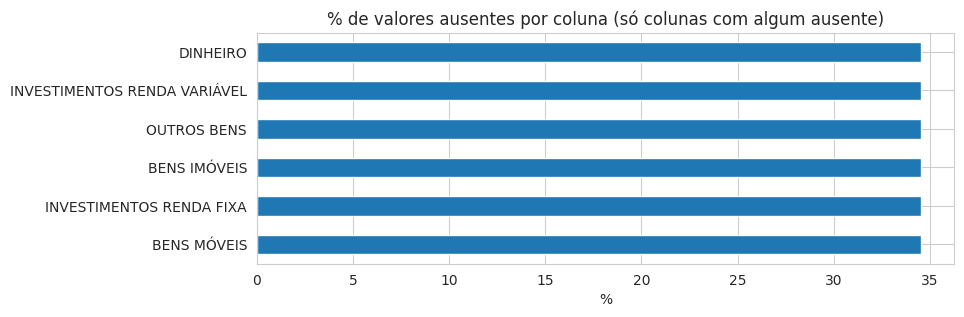

In [ ]:
print(f"{df.shape[0]} candidatos x {df.shape[1]} colunas\n")
display(df.dtypes.value_counts().rename('nº de colunas'))

faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

if len(faltantes) > 0:
    plt.figure(figsize=(9, max(3, len(faltantes) * 0.3)))
    faltantes.plot(kind='barh')
    plt.title('% de valores ausentes por coluna (só colunas com algum ausente)')
    plt.xlabel('%')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Nenhuma coluna com valores ausentes.")

## 2) Escolhendo o que explorar

O dataset tem dezenas de colunas — muitas são identificadores administrativos (`SQ_CANDIDATO`, `NR_CPF_CANDIDATO`, `DS_EMAIL`, hashes de geração...) sem valor analítico. As duas listas abaixo reúnem as colunas com conteúdo substantivo — **sintam-se livres para adicionar outras que despertarem curiosidade** (`df.columns` mostra tudo o que está disponível).

In [ ]:
display(pd.DataFrame({"Coluna": df.columns}))

,Coluna
0,DT_GERACAO
1,HH_GERACAO
2,ANO_ELEICAO
3,CD_TIPO_ELEICAO
4,NM_TIPO_ELEICAO
...,...
56,Total_Bens
57,Total_Bens_Log
58,Total_Gasto_Campanha
59,Total_Gasto_Campanha_Log


In [ ]:
colunas_numericas = [
    'IDADE',
    'Total_Bens',
    'Total_Bens_Log',
    'Total_Gasto_Campanha',
    'Total_Gasto_Campanha_Log',
    'BENS MÓVEIS',
    'BENS IMÓVEIS',
    'DINHEIRO',
    'INVESTIMENTOS RENDA FIXA',
    'INVESTIMENTOS RENDA VARIÁVEL',
    'OUTROS BENS',
]
colunas_numericas = [c for c in colunas_numericas if c in df.columns]

colunas_categoricas = [
    'DS_GENERO',
    'DS_ESTADO_CIVIL',
    'DS_COR_RACA',
    'DS_GRAU_INSTRUCAO',
    'DS_SITUACAO_CANDIDATURA',
    'DS_SIT_TOT_TURNO',
    'TP_AGREMIACAO',
    'SG_PARTIDO',
    'DS_OCUPACAO',
    'NR_TURNO',
    'SG_UE',
]
colunas_categoricas = [c for c in colunas_categoricas if c in df.columns]

print("Numéricas:")
display(pd.DataFrame({"Coluna": colunas_numericas}))
print("Categóricas:")
display(pd.DataFrame({"Coluna": colunas_categoricas}))

Numéricas:


,Coluna
0,IDADE
1,Total_Bens
2,Total_Bens_Log
3,Total_Gasto_Campanha
4,Total_Gasto_Campanha_Log
5,BENS MÓVEIS
6,BENS IMÓVEIS
7,DINHEIRO
8,INVESTIMENTOS RENDA FIXA
9,INVESTIMENTOS RENDA VARIÁVEL


Categóricas:


,Coluna
0,DS_GENERO
1,DS_ESTADO_CIVIL
2,DS_COR_RACA
3,DS_GRAU_INSTRUCAO
4,DS_SITUACAO_CANDIDATURA
5,DS_SIT_TOT_TURNO
6,TP_AGREMIACAO
7,SG_PARTIDO
8,DS_OCUPACAO
9,NR_TURNO


In [ ]:
print(f"{df.shape[0]} candidatos x {df.shape[1]} colunas")

2791 candidatos x 61 colunas


## 3) Variáveis numéricas: distribuição e outliers

In [ ]:
display(df[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
IDADE,"2,791.00",49.86,11.59,21.00,42.00,49.00,58.00,89.00
Total_Bens,"2,791.00","1,002,719.38","4,614,209.44",0.00,0.00,"104,239.32","656,804.00","154,802,877.92"
Total_Bens_Log,"2,791.00",8.30,6.26,0.00,0.00,11.55,13.40,18.86
Total_Gasto_Campanha,"2,791.00","217,952.51","461,070.15",0.00,0.00,"20,780.00","162,337.00","3,127,762.74"
Total_Gasto_Campanha_Log,"2,791.00",7.94,5.25,0.00,0.00,9.94,12.00,14.96
BENS MÓVEIS,"1,827.00","77,091.71","220,083.89",0.00,0.00,"24,000.00","99,100.50","6,009,693.00"
BENS IMÓVEIS,"1,827.00","585,250.23","1,411,902.48",0.00,0.00,"188,050.00","600,000.00","31,691,760.79"
DINHEIRO,"1,827.00","66,068.27","708,630.15",0.00,0.00,0.00,"9,637.85","24,000,000.00"
INVESTIMENTOS RENDA FIXA,"1,827.00","79,875.74","576,961.73",0.00,0.00,0.00,"1,689.64","17,826,083.08"
INVESTIMENTOS RENDA VARIÁVEL,"1,827.00","199,491.59","1,610,730.41",0.00,0.00,0.00,0.00,"37,770,000.00"


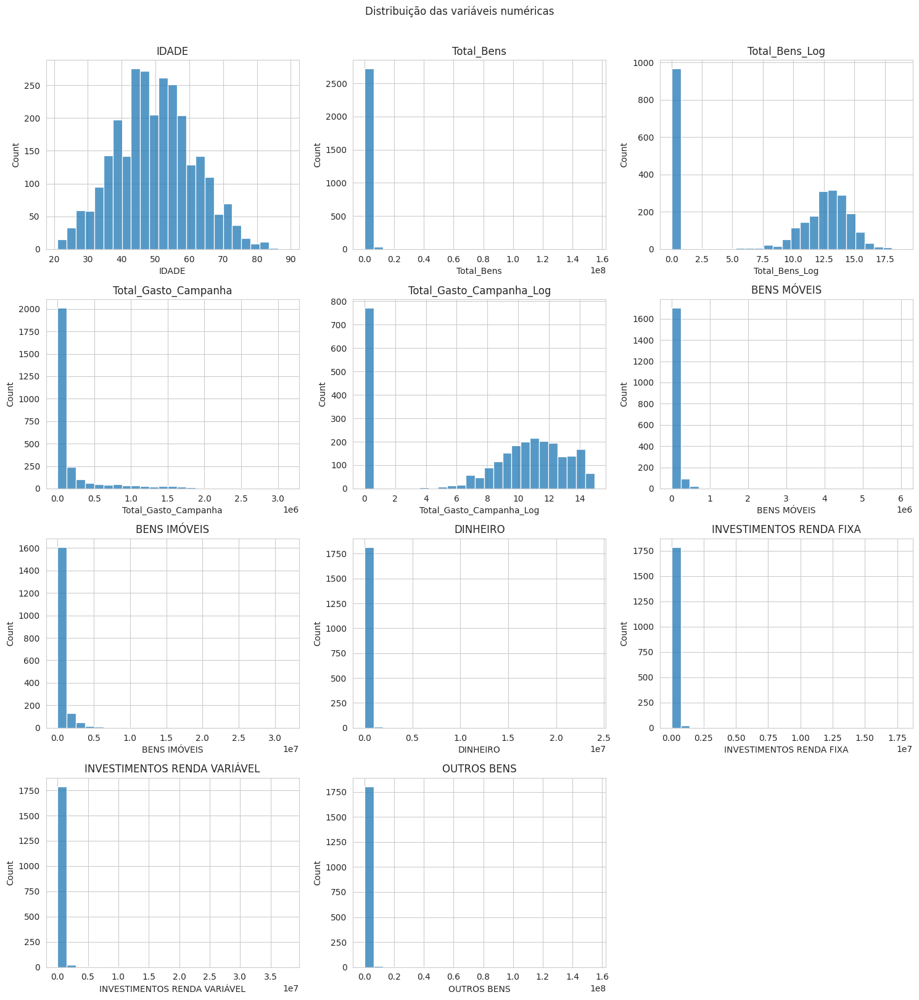

In [ ]:
n = len(colunas_numericas)
ncols = 3
nrows = -(-n // ncols)  # arredonda pra cima

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.histplot(df[col], bins=25, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribuição das variáveis numéricas', y=1.01)
plt.tight_layout()
plt.show()

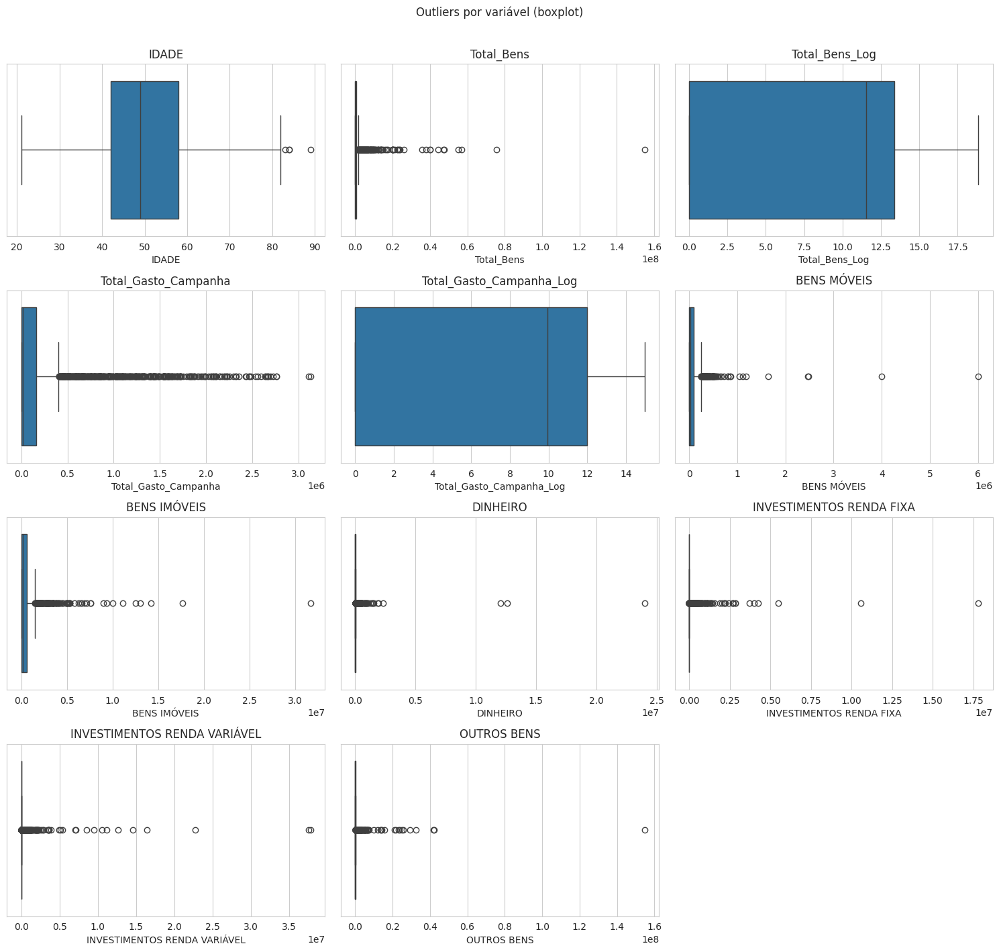

In [ ]:
n = len(colunas_numericas)
ncols = 3
nrows = -(-n // ncols)  # arredonda pra cima

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Outliers por variável (boxplot)', y=1.01)
plt.tight_layout()
plt.show()

### 3.1) Quantificando os outliers (regra do IQR)

O boxplot mostra visualmente; esta tabela quantifica: quantos candidatos ficam fora do intervalo `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` em cada variável.

In [ ]:
linhas = []
for col in colunas_numericas:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    linhas.append({
        'variavel': col, 'limite_inferior': lim_inf, 'limite_superior': lim_sup,
        'qtd_outliers': n_outliers, 'pct_outliers': round(100 * n_outliers / len(df), 1),
    })

pd.DataFrame(linhas).sort_values('pct_outliers', ascending=False)

,variavel,limite_inferior,limite_superior,qtd_outliers,pct_outliers
3,Total_Gasto_Campanha,"-243,505.50","405,842.50",426,15.30
9,INVESTIMENTOS RENDA VARIÁVEL,0.00,0.00,418,15.00
8,INVESTIMENTOS RENDA FIXA,"-2,534.46","4,224.10",416,14.90
1,Total_Bens,"-985,206.00","1,642,010.00",344,12.30
7,DINHEIRO,"-14,456.78","24,094.64",342,12.30
10,OUTROS BENS,"-157,710.31","262,850.51",325,11.60
6,BENS IMÓVEIS,"-900,000.00","1,500,000.00",168,6.00
5,BENS MÓVEIS,"-148,650.75","247,751.25",120,4.30
0,IDADE,18.00,82.00,4,0.10
2,Total_Bens_Log,-20.09,33.49,0,0.00


## 4) Variáveis categóricas: contagens e proporções

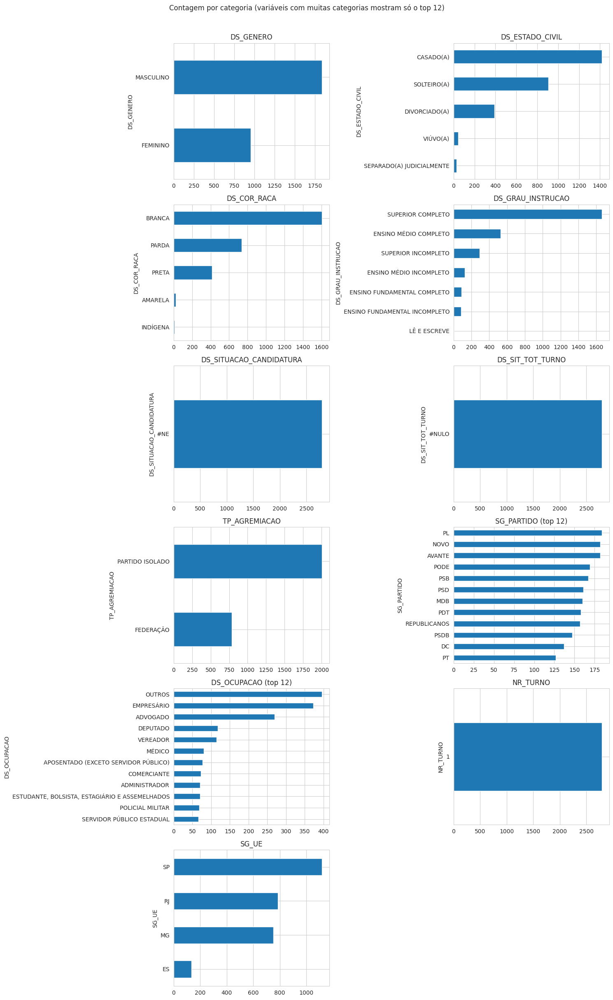

In [ ]:
def plot_categorica(ax, coluna, top_n=12):
    contagem = df[coluna].value_counts().head(top_n)
    contagem.plot(kind='barh', ax=ax)
    ax.set_title(coluna + (f' (top {top_n})' if df[coluna].nunique() > top_n else ''))
    ax.invert_yaxis()

n = len(colunas_categoricas)
ncols = 2
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas):
    plot_categorica(axes[i], col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Contagem por categoria (variáveis com muitas categorias mostram só o top 12)', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
for col in colunas_categoricas:
    print(f"--- {col} ({df[col].nunique()} categorias) ---")
    print((df[col].value_counts(normalize=True).head(8) * 100).round(1).astype(str) + '%')
    print()

--- DS_GENERO (2 categorias) ---
DS_GENERO
MASCULINO    65.7%
FEMININO     34.3%
Name: proportion, dtype: object

--- DS_ESTADO_CIVIL (5 categorias) ---
DS_ESTADO_CIVIL
CASADO(A)                    50.8%
SOLTEIRO(A)                  32.5%
DIVORCIADO(A)                14.0%
VIÚVO(A)                      1.6%
SEPARADO(A) JUDICIALMENTE     1.0%
Name: proportion, dtype: object

--- DS_COR_RACA (5 categorias) ---
DS_COR_RACA
BRANCA      57.5%
PARDA       26.4%
PRETA       14.9%
AMARELA      0.8%
INDÍGENA     0.4%
Name: proportion, dtype: object

--- DS_GRAU_INSTRUCAO (7 categorias) ---
DS_GRAU_INSTRUCAO
SUPERIOR COMPLETO                59.6%
ENSINO MÉDIO COMPLETO            18.9%
SUPERIOR INCOMPLETO              10.5%
ENSINO MÉDIO INCOMPLETO           4.5%
ENSINO FUNDAMENTAL COMPLETO       3.2%
ENSINO FUNDAMENTAL INCOMPLETO     3.0%
LÊ E ESCREVE                      0.3%
Name: proportion, dtype: object

--- DS_SITUACAO_CANDIDATURA (1 categorias) ---
DS_SITUACAO_CANDIDATURA
#NE    100.0%
Nam

## 5) Dispersão entre variáveis numéricas

Correlação e gráficos de dispersão par a par — sem nenhuma variável de destaque, só pra ver como as variáveis se relacionam (ou não).

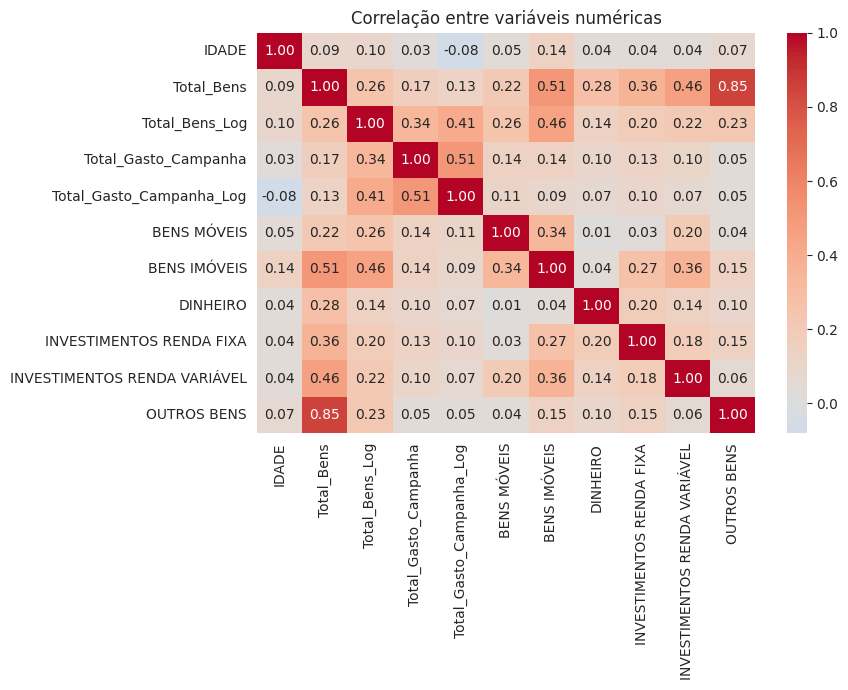

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_numericas].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlação entre variáveis numéricas')
plt.tight_layout()
plt.show()

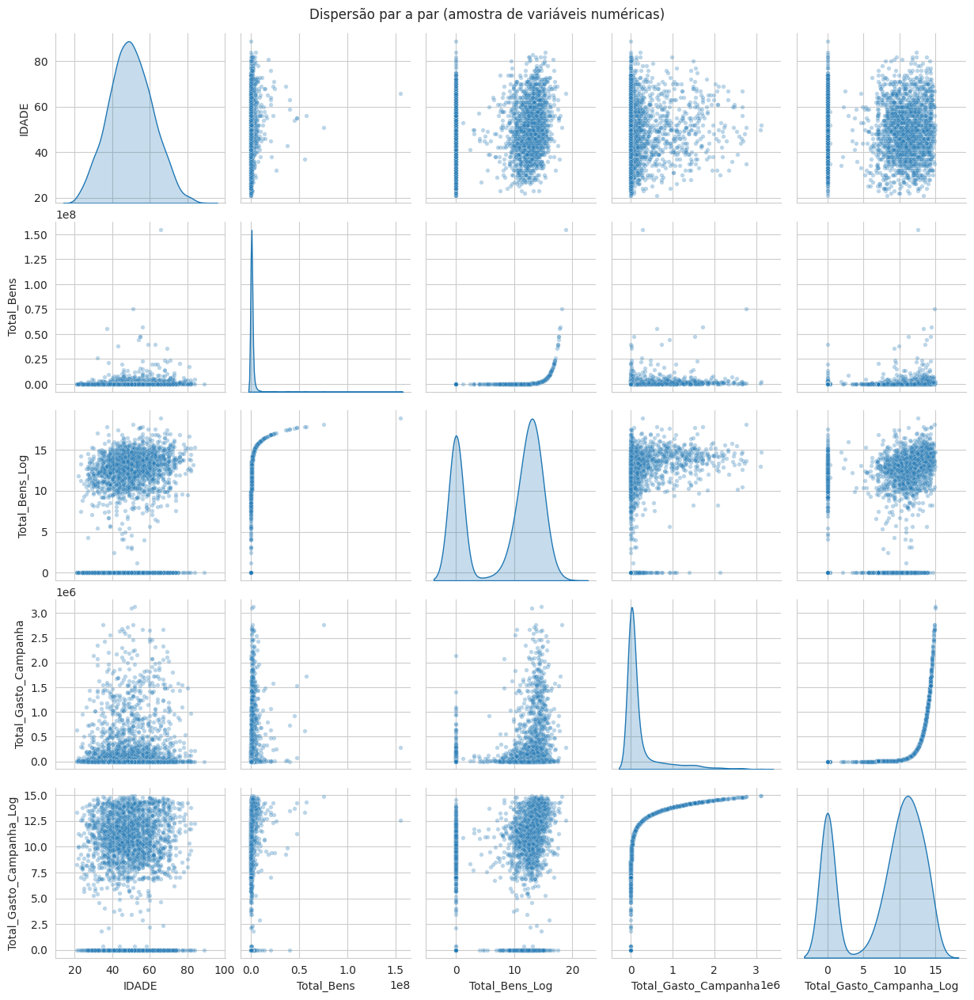

In [ ]:
# Pairplot com um subconjunto (pairplot com muitas variáveis fica pesado/ilegível)
subset = colunas_numericas[:5]
sns.pairplot(df[subset].dropna(), diag_kind='kde', plot_kws={'alpha': 0.3, 's': 15})
plt.suptitle('Dispersão par a par (amostra de variáveis numéricas)', y=1.01)
plt.show()

### 5.1) Um exemplo de dispersão colorida

Só um exemplo de como cruzar uma variável numérica com outra numérica *e* uma categórica ao mesmo tempo — troquem `x`, `y` e `hue` livremente para explorar outras combinações.

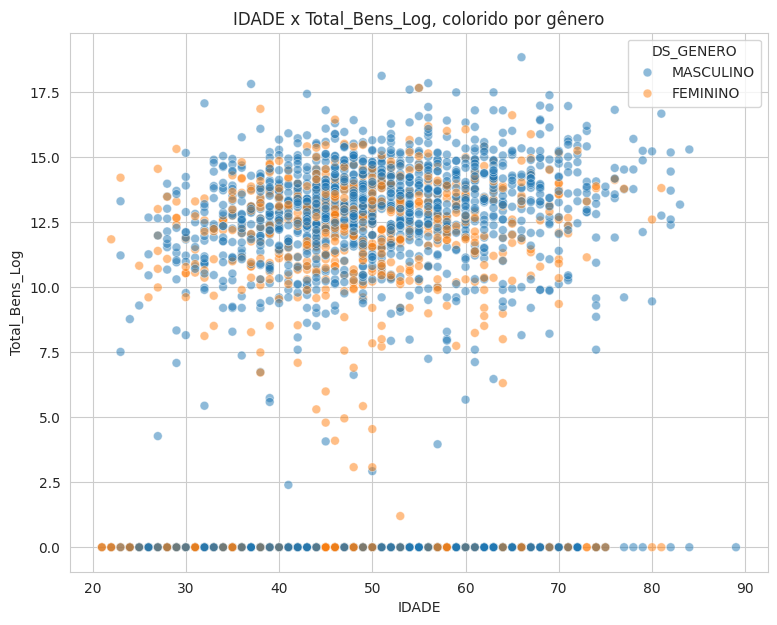

In [ ]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x='IDADE', y='Total_Bens_Log', hue='DS_GENERO', alpha=0.5, s=40)
plt.title('IDADE x Total_Bens_Log, colorido por gênero')
plt.show()

## 6) Proporções entre grupos

Alguns exemplos de cruzamentos categóricos — não são os únicos possíveis, só uma amostra do tipo de pergunta que dá pra fazer.

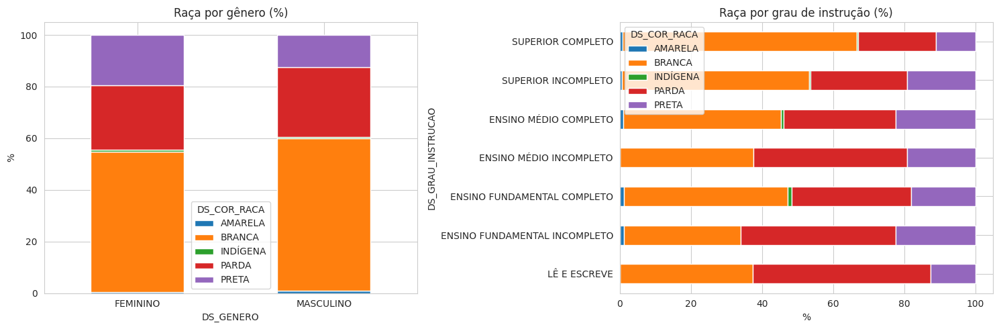

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pd.crosstab(df['DS_GENERO'], df['DS_COR_RACA'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=axes[0]
)
axes[0].set_title('Raça por gênero (%)')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)

ordem_instrucao = df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']].drop_duplicates().sort_values('CD_GRAU_INSTRUCAO')['DS_GRAU_INSTRUCAO']
pd.crosstab(df['DS_GRAU_INSTRUCAO'], df['DS_COR_RACA'], normalize='index').loc[ordem_instrucao].mul(100).plot(
    kind='barh', stacked=True, ax=axes[1]
)
axes[1].set_title('Raça por grau de instrução (%)')
axes[1].set_xlabel('%')

plt.tight_layout()
plt.show()

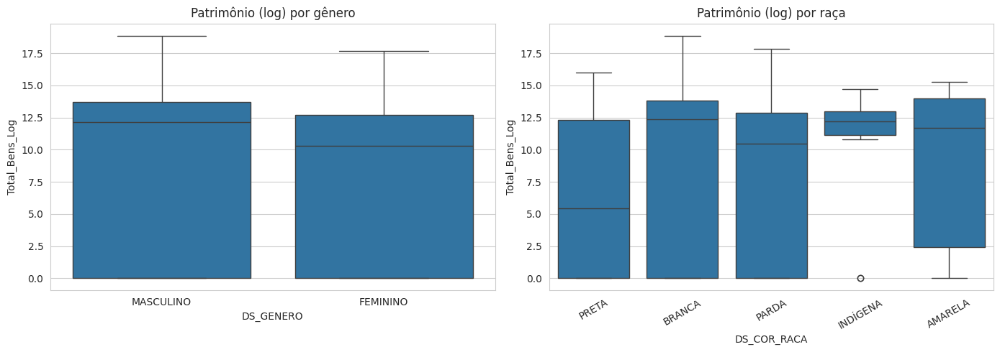

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GENERO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por gênero')

sns.boxplot(data=df, x='DS_COR_RACA', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por raça')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

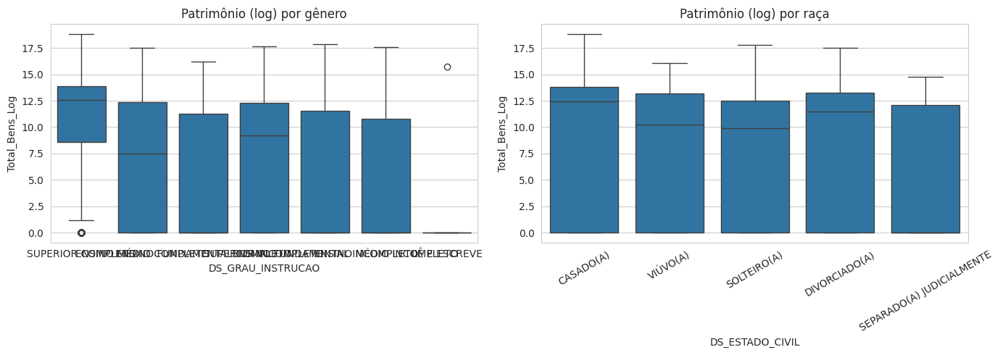

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='DS_GRAU_INSTRUCAO', y='Total_Bens_Log', ax=axes[0])
axes[0].set_title('Patrimônio (log) por gênero')

sns.boxplot(data=df, x='DS_ESTADO_CIVIL', y='Total_Bens_Log', ax=axes[1])
axes[1].set_title('Patrimônio (log) por raça')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

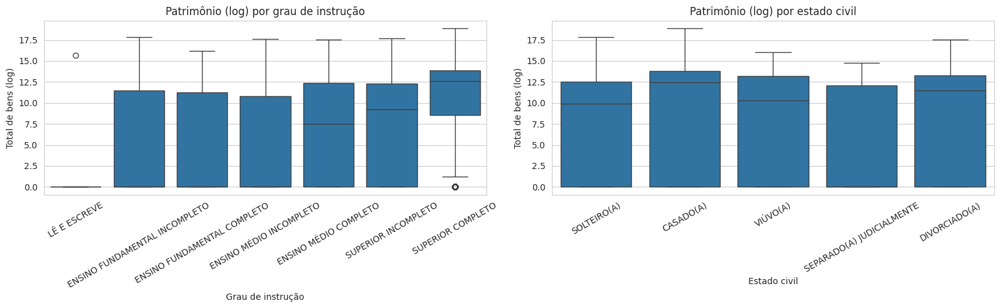

In [ ]:
# Ordem do grau de instrução pelo respectivo código
ordem_instrucao = (
    df[['CD_GRAU_INSTRUCAO', 'DS_GRAU_INSTRUCAO']]
    .drop_duplicates()
    .sort_values('CD_GRAU_INSTRUCAO')
    ['DS_GRAU_INSTRUCAO']
    .tolist()
)

# Ordem do estado civil pelo respectivo código
ordem_estado_civil = (
    df[['CD_ESTADO_CIVIL', 'DS_ESTADO_CIVIL']]
    .drop_duplicates()
    .sort_values('CD_ESTADO_CIVIL')
    ['DS_ESTADO_CIVIL']
    .tolist()
)


# Cria os dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 5))


# Grau de instrução
sns.boxplot(
    data=df,
    x='DS_GRAU_INSTRUCAO',
    y='Total_Bens_Log',
    order=ordem_instrucao,
    ax=axes[0]
)

axes[0].set_title('Patrimônio (log) por grau de instrução')
axes[0].set_xlabel('Grau de instrução')
axes[0].set_ylabel('Total de bens (log)')
axes[0].tick_params(axis='x', rotation=30)


# Estado civil
sns.boxplot(
    data=df,
    x='DS_ESTADO_CIVIL',
    y='Total_Bens_Log',
    order=ordem_estado_civil,
    ax=axes[1]
)

axes[1].set_title('Patrimônio (log) por estado civil')
axes[1].set_xlabel('Estado civil')
axes[1].set_ylabel('Total de bens (log)')
axes[1].tick_params(axis='x', rotation=30)


plt.tight_layout()
plt.show()

## 7) Comparação entre UFs

Esta seção só roda na visão **Brasil** (quando `UF = None`) — não se aplica ao recorte por estado.

In [ ]:
if UF is None:
    resumo_uf = df.groupby('SG_UF').agg(
        qtd_candidatos=('SQ_CANDIDATO', 'count'),
        idade_media=('IDADE', 'mean'),
        patrimonio_mediano=('Total_Bens', 'median'),
        pct_feminino=('DS_GENERO', lambda x: (x == 'FEMININO').mean() * 100),
    ).round(1).sort_values('qtd_candidatos', ascending=False)

    display(resumo_uf)

    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    resumo_uf['qtd_candidatos'].sort_values().plot(kind='barh', ax=axes[0])
    axes[0].set_title(f'Nº de candidatos a {CARGO} por UF')

    resumo_uf['patrimonio_mediano'].sort_values().plot(kind='barh', ax=axes[1], color='tab:orange')
    axes[1].set_title('Patrimônio mediano por UF (R$)')

    plt.tight_layout()
    plt.show()
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")

UF = ['SP', 'RJ', 'MG', 'ES'] — seção não se aplica (dados já filtrados para uma única UF).


---
## Fechamento

Este notebook não teve o objetivo de "preparar terreno" para nenhuma técnica específica — foi só olhar para os dados. Antes de seguir, escrevam algumas observações próprias: quais variáveis têm mais outliers? Alguma proporção chamou atenção? Alguma dispersão sugere relação entre variáveis (ou ausência dela)? Essas observações são o ponto de partida — não a conclusão — das próximas fases.

## Próximo passo

**Fase 2 — Clusterização** (K-Means, DBSCAN, hierárquico e Bisecting K-Means) — liberada em breve. A escolha de variáveis para essa fase parte do que vocês observaram aqui.

# Fase 2 — Clusterização: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem perfis demográfico-sociais distintos entre os candidatos, nas Eleições 2026? Combinando idade, escolaridade e patrimônio declarado, os candidatos se agrupam em segmentos claramente diferentes — e, se sim, como esses segmentos se distribuem em termos de gênero, cor/raça e estado civil?**

Para responder isso com K-Means, separamos as variáveis em dois papéis:

- **Variáveis-driver** (entram na conta de distância, definem os clusters): idade, escolaridade e patrimônio declarado.
- **Variáveis de perfil** (não entram no modelo — descrevem os clusters depois de prontos): `DS_GENERO`, `DS_COR_RACA`, `DS_ESTADO_CIVIL`.

> `DS_SIT_TOT_TURNO` (situação eleitoral — eleito ou não) fica de fora por enquanto: a eleição de 2026 ainda não aconteceu, então essa coluna vem toda nula nesta base. Assim que o resultado sair, vale voltar aqui e cruzar os clusters com quem foi eleito.

Essa separação importa: jogar categóricas como gênero/raça direto numa distância Euclidiana exigiria codificação cuidadosa (fora do escopo desta primeira versão). Em vez disso, os grupos nascem de 3 variáveis contínuas/ordinais bem comportadas, e o "perfil demográfico-social" completo — que é o que a pergunta pede — aparece na leitura dos clusters, não na formação deles.

**Este notebook cobre a Parte 1 (K-Means)**, em **duas rodadas de propósito**, pra mostrar por que escolha de variável e escolha de métrica importam:

1. **Versão 1**: exatamente como fizemos na primeira tentativa — escolaridade entra como o código bruto do TSE, seleção de `k` só com cotovelo + silhouette.
2. **Versão 2**: escolaridade recodificada como variável intervalar, e mais duas métricas (Davies-Bouldin, Calinski-Harabasz) apoiando a escolha de `k`.

DBSCAN, hierárquico e Bisecting K-Means serão adicionados nas próximas atualizações, reaproveitando a mesma base e a mesma pergunta.

Parte do arquivo salvo pela **Fase 0** (`00_preparacao_dados.ipynb`).

## Configuração

Use os **mesmos valores** que você usou na Fase 0/1, para carregar o arquivo certo.

In [ ]:
CARGO = "DEPUTADO FEDERAL"
UF = ["SP", "RJ", "MG", "ES"]               # mesmo valor usado na Fase 0/1
ANO_ELEICAO = 2026

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

SEMENTE = 42
np.random.seed(SEMENTE)  # reprodutibilidade defensiva — o KMeans já usa random_state próprio,
                          # mas fixar a semente global evita surpresa se alguém adicionar
                          # outro trecho aleatório (amostragem, shuffle, etc.) mais adiante.

nome_uf = UF if UF is not None else 'BRASIL'
nome_cargo = CARGO.replace(' ', '_')
arquivo = f"dados/candidatos_completo_DEPUTADO_FEDERAL_{str(tuple(UF))}_{2026}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: dados/candidatos_completo_DEPUTADO_FEDERAL_('SP', 'RJ', 'MG', 'ES')_2026.csv  ->  2791 candidatos, 61 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,Total_Gasto_Campanha,Total_Gasto_Campanha_Log,IDADE
0,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531643,3090,JOÃO BATISTA DE ASSIS,SARGENTO ASSIS,#NULO,3152826737,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1974-03-23,14740511465,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,278,VEREADOR,-1,#NULO,400000.0,92500.0,0.0,0.0,0.0,0.0,492500.0,13.107252,0.00,0.000000,52
1,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531644,3010,FABÍOLA SAQUETTO DI TOMMASO,FABÍOLA SAQUETTO,#NULO,7106495760,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1977-08-06,17880711481,4,FEMININO,8,SUPERIOR COMPLETO,5,VIÚVO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.000000,3750.00,8.229778,49
2,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531645,3060,AILANA REGINA PELISSARI SIMONELLI MOREIRA,AILANA PELISSARI,#NULO,9365295718,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1978-11-28,19854371449,4,FEMININO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,999,OUTROS,-1,#NULO,0.0,0.0,0.0,0.0,0.0,60000.0,60000.0,11.002117,5000.00,8.517393,47
3,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531646,3040,JÚLIO CÉSAR COSTA CAIADO,DR. JÚLIO CAIADO,#NULO,33301018653,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1959-04-17,11524561414,2,MASCULINO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,112,VETERINÁRIO,-1,#NULO,900000.0,115000.0,0.0,0.0,0.0,0.0,1015000.0,13.830400,9.95,2.393339,67
4,23/08/2026,19:30:42,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531647,3033,LEONARDO RODRIGO NASCIMENTO,LÉO SINDICO,#NULO,7877752741,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1979-11-14,19497891406,2,MASCULINO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,257,EMPRESÁRIO,-1,#NULO,300000.0,52000.0,0.0,0.0,0.0,0.0,352000.0,12.771389,5275.19,8.570960,46


---
# Versão 1 — a primeira tentativa

Variáveis-driver: `IDADE`, `CD_GRAU_INSTRUCAO` (código bruto do TSE, 2 a 8), `Total_Bens_Log`. Escolha de `k` só com cotovelo (WCSS) + silhouette.

### V1.1) Outliers e padronização

In [ ]:
colunas_driver_v1 = ['IDADE', 'CD_GRAU_INSTRUCAO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

antes = df.shape[0]
Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster_v1 = df[df['Total_Bens_Log'] <= limite_superior].copy()
print(f"Removidos {antes - df_cluster_v1.shape[0]} candidatos com patrimônio extremo "
      f"(Total_Bens_Log > {limite_superior:.2f}, ~R$ {np.expm1(limite_superior):,.0f})")
print(f"Base para clusterização: {df_cluster_v1.shape[0]} candidatos")

scaler_v1 = MinMaxScaler()
X_v1 = scaler_v1.fit_transform(df_cluster_v1[colunas_driver_v1])

df_cluster_v1[colunas_driver_v1].describe()

Removidos 0 candidatos com patrimônio extremo (Total_Bens_Log > 33.49, ~R$ 349,615,205,006,764)
Base para clusterização: 2791 candidatos


,IDADE,CD_GRAU_INSTRUCAO,Total_Bens_Log,Total_Gasto_Campanha_Log
count,2791.000000,2791.000000,2791.000000,2791.000000
mean,49.862415,7.085274,8.302056,7.936400
std,11.590770,1.342936,6.255827,5.245478
min,21.000000,2.000000,0.000000,0.000000
25%,42.000000,6.000000,0.000000,0.000000
50%,49.000000,8.000000,11.554454,9.941794
75%,58.000000,8.000000,13.395142,11.997434
max,89.000000,8.000000,18.857663,14.955829


### V1.2) Escolhendo k (cotovelo + silhouette)

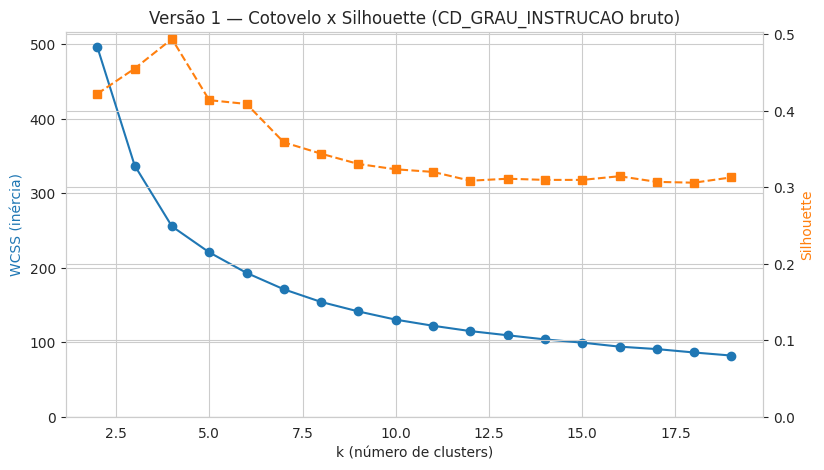

k=2  WCSS=496.064  silhouette=0.422
k=3  WCSS=337.199  silhouette=0.455
k=4  WCSS=255.457  silhouette=0.494
k=5  WCSS=220.610  silhouette=0.414
k=6  WCSS=193.057  silhouette=0.409
k=7  WCSS=171.023  silhouette=0.358
k=8  WCSS=154.026  silhouette=0.344
k=9  WCSS=141.289  silhouette=0.330
k=10  WCSS=130.293  silhouette=0.323
k=11  WCSS=122.087  silhouette=0.320
k=12  WCSS=114.921  silhouette=0.308
k=13  WCSS=109.330  silhouette=0.311
k=14  WCSS=103.771  silhouette=0.309
k=15  WCSS=99.445  silhouette=0.309
k=16  WCSS=94.057  silhouette=0.314
k=17  WCSS=90.767  silhouette=0.307
k=18  WCSS=86.207  silhouette=0.306
k=19  WCSS=82.078  silhouette=0.313


In [ ]:
wcss_v1, sil_v1 = [], []
faixa_k = range(2, 20)

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X_v1)
    wcss_v1.append(km.inertia_)
    sil_v1.append(silhouette_score(X_v1, labels))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(list(faixa_k), wcss_v1, marker='o', color='tab:blue')
ax1.set_xlabel('k (número de clusters)')
ax1.set_ylabel('WCSS (inércia)', color='tab:blue')
ax1.set_ylim(bottom=0)  # eixo começa em zero: um eixo cortado pode fazer o cotovelo parecer mais dramático do que é
ax1.set_title('Versão 1 — Cotovelo x Silhouette (CD_GRAU_INSTRUCAO bruto)')

ax2 = ax1.twinx()
ax2.plot(list(faixa_k), sil_v1, marker='s', linestyle='--', color='tab:orange')
ax2.set_ylabel('Silhouette', color='tab:orange')
ax2.set_ylim(bottom=min(0, min(sil_v1)))
plt.show()

for k, w, s in zip(faixa_k, wcss_v1, sil_v1):
    print(f"k={k}  WCSS={w:.3f}  silhouette={s:.3f}")

> Repare que o cotovelo não mostra uma quebra nítida — a curva desce suavemente, sem um "V" claro. Isso pode ser dado real (candidatos formando mais um contínuo do que grupos separados) ou pode ser efeito de tratar uma variável ordinal como se fosse intervalar. Seguimos mesmo assim com um `k` razoável, só pra completar a Versão 1 e comparar depois.

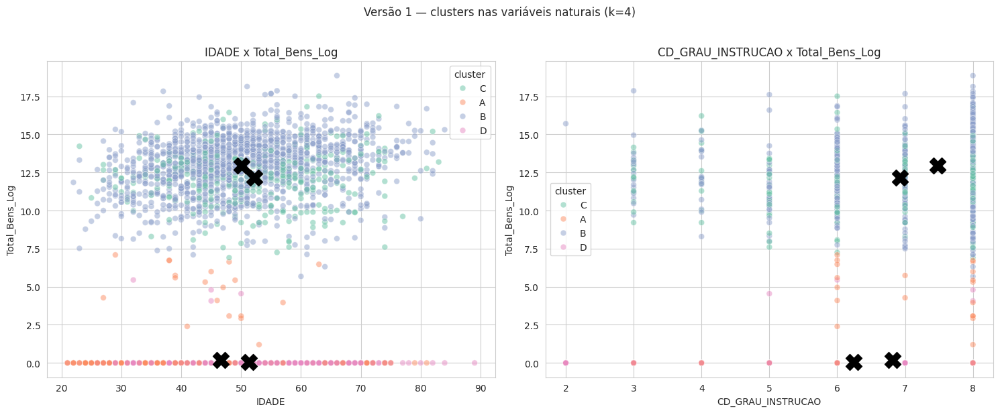

,qtd_candidatos,idade_media,instrucao_media,patrimonio_mediano
cluster,,,,
A,530,46.6,6.8,0.0
B,1463,50.0,7.5,495882.0
C,339,52.2,6.9,207108.4
D,459,51.3,6.2,0.0


In [ ]:
k_v1 = 4  # ajuste conforme a célula anterior, se quiser

kmeans_v1 = KMeans(n_clusters=k_v1, random_state=SEMENTE, n_init=10)
df_cluster_v1['cluster'] = kmeans_v1.fit_predict(X_v1)
df_cluster_v1['cluster'] = df_cluster_v1['cluster'].map(lambda x: chr(65 + x))

centroides_v1 = scaler_v1.inverse_transform(kmeans_v1.cluster_centers_)
df_centroides_v1 = pd.DataFrame(centroides_v1, columns=colunas_driver_v1)
df_centroides_v1.index = [chr(65 + i) for i in range(k_v1)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_cluster_v1, x='IDADE', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides_v1['IDADE'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster_v1, x='CD_GRAU_INSTRUCAO', y='Total_Bens_Log', hue='cluster', palette='Set2', alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides_v1['CD_GRAU_INSTRUCAO'], df_centroides_v1['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('CD_GRAU_INSTRUCAO x Total_Bens_Log')

plt.suptitle(f'Versão 1 — clusters nas variáveis naturais (k={k_v1})', y=1.02)
plt.tight_layout()
plt.show()

resumo_v1 = df_cluster_v1.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    instrucao_media=('CD_GRAU_INSTRUCAO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_v1)

---
# Versão 2 — ajustando a variável e a métrica

Dois ajustes em relação à Versão 1:

1. **Escolaridade como variável intervalar.** `CD_GRAU_INSTRUCAO` é um código **ordinal**, não intervalar: nada garante que o "salto" entre dois códigos consecutivos valha o mesmo em todos os pontos da escala (a diferença entre "lê e escreve" e "fundamental incompleto" não é comparável à diferença entre "superior incompleto" e "superior completo"). Como o K-Means calcula médias e distância Euclidiana, ele *assume* espaçamento igual — então usar o código bruto distorce essa variável. Trocamos pelo proxy padrão em pesquisa social: **anos de escolaridade equivalentes** (mesma lógica usada em censos/pesquisas domiciliares).
2. **Mais métricas para escolher `k`.** Além de WCSS e silhouette, adicionamos Davies-Bouldin e Calinski-Harabasz — quando o cotovelo é ambíguo (como foi o caso), várias métricas concordando é um sinal mais forte do que uma métrica só.

In [ ]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — não dá pra estimar anos de estudo sem essa informação
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)

print("Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar):", df['ANOS_ESTUDO'].isna().sum())
df[['DS_GRAU_INSTRUCAO', 'ANOS_ESTUDO']].drop_duplicates().sort_values('ANOS_ESTUDO')

Candidatos sem correspondência (NÃO DIVULGÁVEL ou similar): 0


,DS_GRAU_INSTRUCAO,ANOS_ESTUDO
391,LÊ E ESCREVE,1
89,ENSINO FUNDAMENTAL INCOMPLETO,4
9,ENSINO FUNDAMENTAL COMPLETO,8
110,ENSINO MÉDIO INCOMPLETO,9
7,ENSINO MÉDIO COMPLETO,11
14,SUPERIOR INCOMPLETO,13
0,SUPERIOR COMPLETO,16


> **Alternativa mais rigorosa (fora do escopo desta primeira versão):** distância de **Gower** — que trata variáveis ordinais, nominais e contínuas de forma nativa, sem forçar nenhuma delas a um espaçamento artificial — combinada com **K-Medoids/PAM** em vez de K-Means (Gower não permite calcular "média", só distância entre pontos reais). Fica como comparação futura, ao lado de DBSCAN/hierárquico/Bisecting K-Means.

### V2.1) Outliers e padronização

In [ ]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Gasto_Campanha_Log']

antes = df.shape[0]
df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Removidos {antes - df_cluster.shape[0]} candidatos "
      f"(patrimônio extremo acima de ~R$ {np.expm1(limite_superior):,.0f}, ou escolaridade não divulgada)")
print(f"Base para clusterização: {df_cluster.shape[0]} candidatos")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])

df_cluster[colunas_driver].describe()

Removidos 0 candidatos (patrimônio extremo acima de ~R$ 349,615,205,006,764, ou escolaridade não divulgada)
Base para clusterização: 2791 candidatos


,IDADE,ANOS_ESTUDO,Total_Bens_Log,Total_Gasto_Campanha_Log
count,2791.000000,2791.000000,2791.000000,2791.000000
mean,49.862415,13.762092,8.302056,7.936400
std,11.590770,3.152062,6.255827,5.245478
min,21.000000,1.000000,0.000000,0.000000
25%,42.000000,11.000000,0.000000,0.000000
50%,49.000000,16.000000,11.554454,9.941794
75%,58.000000,16.000000,13.395142,11.997434
max,89.000000,16.000000,18.857663,14.955829


### V2.2) Escolhendo k (cotovelo + silhouette + Davies-Bouldin + Calinski-Harabasz)

- **Silhouette** (quanto maior, melhor).
- **Davies-Bouldin** (quanto **menor**, melhor): quão parecidos/sobrepostos os clusters são entre si.
- **Calinski-Harabasz** (quanto maior, melhor): razão entre dispersão entre clusters e dispersão dentro dos clusters.

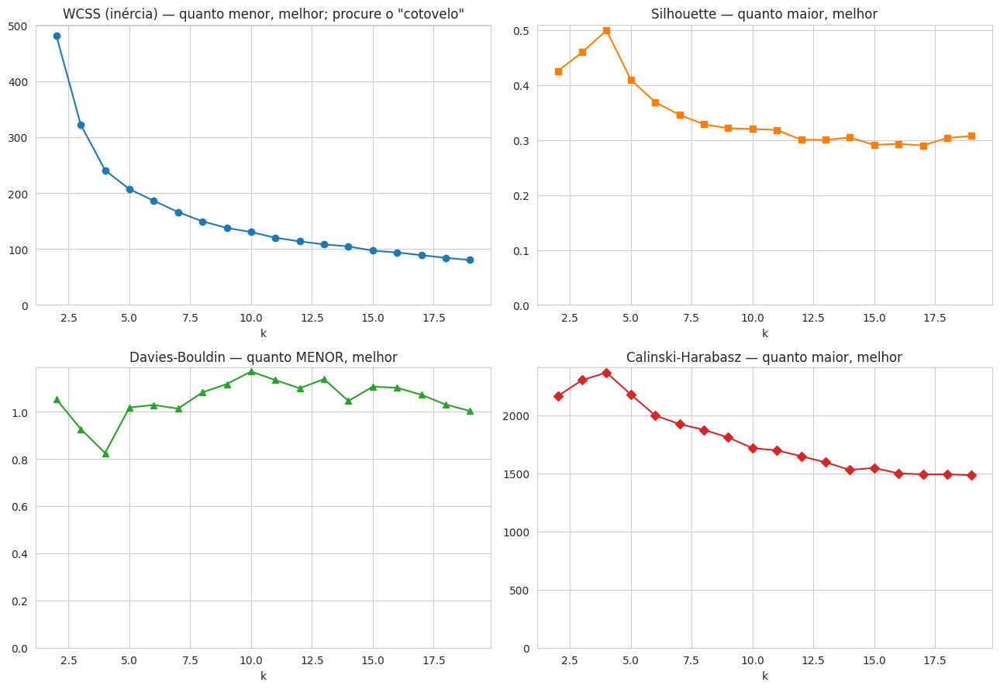

,k,wcss,silhouette,davies_bouldin,calinski_harabasz
0,2,480.916,0.425,1.052,2166.593
1,3,322.167,0.460,0.927,2303.410
2,4,240.769,0.499,0.825,2368.093
3,5,206.973,0.409,1.018,2179.073
4,6,186.212,0.369,1.028,1999.017
5,7,165.987,0.346,1.013,1924.734
6,8,149.477,0.328,1.081,1875.267
7,9,137.726,0.321,1.117,1809.833
8,10,130.284,0.320,1.170,1717.680
9,11,120.161,0.318,1.133,1698.951


In [ ]:
wcss, sil, db, ch = [], [], [], []

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, labels))
    db.append(davies_bouldin_score(X, labels))
    ch.append(calinski_harabasz_score(X, labels))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(list(faixa_k), wcss, marker='o', color='tab:blue')
axes[0, 0].set_title('WCSS (inércia) — quanto menor, melhor; procure o "cotovelo"')
axes[0, 0].set_ylim(bottom=0)

axes[0, 1].plot(list(faixa_k), sil, marker='s', color='tab:orange')
axes[0, 1].set_title('Silhouette — quanto maior, melhor')
axes[0, 1].set_ylim(bottom=min(0, min(sil)))

axes[1, 0].plot(list(faixa_k), db, marker='^', color='tab:green')
axes[1, 0].set_title('Davies-Bouldin — quanto MENOR, melhor')
axes[1, 0].set_ylim(bottom=0)

axes[1, 1].plot(list(faixa_k), ch, marker='D', color='tab:red')
axes[1, 1].set_title('Calinski-Harabasz — quanto maior, melhor')
axes[1, 1].set_ylim(bottom=0)

# eixo em zero: evita que um eixo cortado exagere visualmente uma quebra que não é tão forte assim
for ax in axes.flatten():
    ax.set_xlabel('k')
    ax.grid(True)

plt.tight_layout()
plt.show()

pd.DataFrame({'k': list(faixa_k), 'wcss': wcss, 'silhouette': sil, 'davies_bouldin': db, 'calinski_harabasz': ch}).round(3)

### V2.3) Ajustando o K-Means

Escolha o `k` cruzando as quatro métricas acima — se elas discordarem muito, prefira o `k` mais fácil de interpretar/explicar dentro da pergunta de negócio.

In [ ]:
k_final = 4  # ajuste conforme a célula anterior

kmeans = KMeans(n_clusters=k_final, random_state=SEMENTE, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(X)
df_cluster['cluster'] = df_cluster['cluster'].map(lambda x: chr(65 + x))

# Paleta única e fixa por cluster — reaproveitada em TODOS os gráficos daqui pra frente,
# pra cluster A ter sempre a mesma cor, em qualquer tipo de gráfico (scatter, barra, radar...).
clusters_ordenados = sorted(df_cluster['cluster'].unique())
cores_cluster = dict(zip(clusters_ordenados, sns.color_palette('Set2', n_colors=len(clusters_ordenados))))

df_cluster['cluster'].value_counts().sort_index()

,count
cluster,
A,339
B,459
C,531
D,1462


In [ ]:
resumo_driver = df_cluster.groupby('cluster').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_driver)

centroides_norm = kmeans.cluster_centers_
centroides_naturais = scaler.inverse_transform(centroides_norm)
df_centroides = pd.DataFrame(centroides_naturais, columns=colunas_driver)
df_centroides.index = [chr(65 + i) for i in range(k_final)]
df_centroides.index.name = 'cluster'
df_centroides.round(1)

,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
cluster,,,,
A,339,52.2,13.4,207108.4
B,459,51.3,11.8,0.0
C,531,46.7,13.1,0.0
D,1462,50.0,14.7,496441.0


,IDADE,ANOS_ESTUDO,Total_Bens_Log,Total_Gasto_Campanha_Log
cluster,,,,
A,52.2,13.4,12.1,0.3
B,51.3,11.8,0.0,0.1
C,46.7,13.1,0.2,9.9
D,50.0,14.7,13.0,11.5


### Radar: todos os clusters juntos, e depois um a um

Primeiro, todos os clusters sobrepostos no mesmo radar — bom pra comparar formatos de relance. Logo abaixo, o mesmo radar **separado por cluster** — mais fácil de ler o formato de cada um sem o excesso de linhas sobrepostas. As duas versões usam os centróides **na escala padronizada (0 a 1)**, que é o que torna os 3 eixos comparáveis entre si.

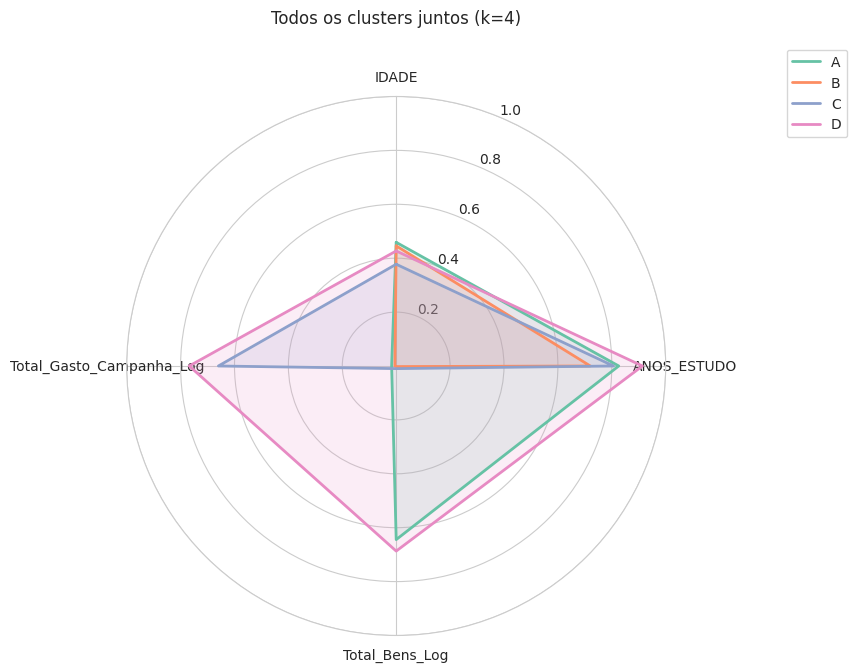

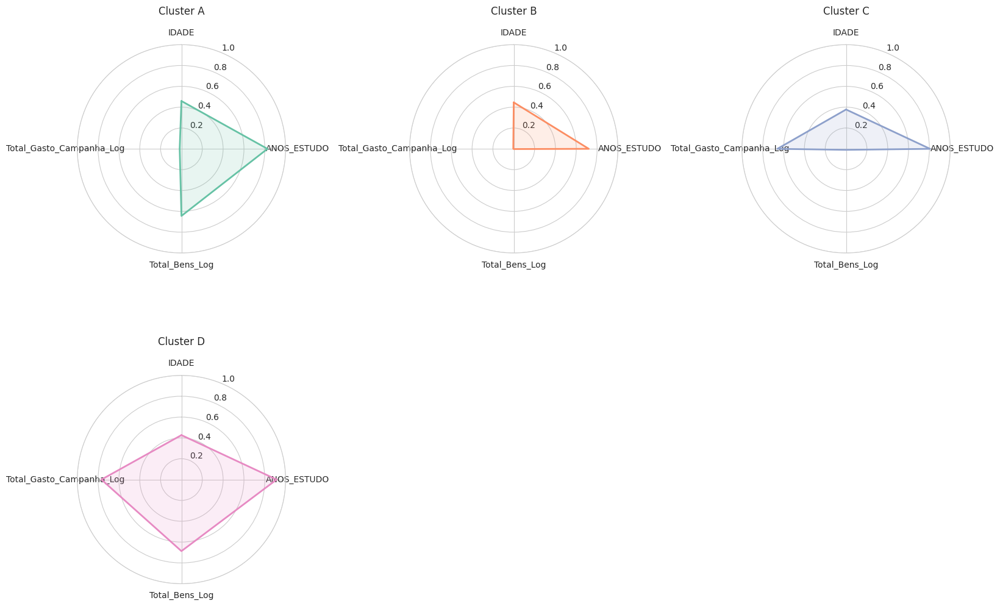

In [ ]:
from math import pi

def plot_radar(ax, centros, labels_eixos, labels_series, cores, titulo):
    n_eixos = len(labels_eixos)
    angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
    angulos += angulos[:1]

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(labels_eixos)
    ax.set_ylim(0, 1)

    for i, linha in enumerate(centros):
        valores = list(linha) + [linha[0]]
        cor = cores[labels_series[i]]
        ax.plot(angulos, valores, linewidth=2, label=labels_series[i], color=cor)
        ax.fill(angulos, valores, alpha=0.15, color=cor)

    ax.set_title(titulo, y=1.12)

# --- todos juntos ---
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plot_radar(ax, centroides_norm, colunas_driver, clusters_ordenados, cores_cluster,
           f'Todos os clusters juntos (k={k_final})')
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.show()

# --- um radar por cluster ---
ncols = min(k_final, 3)
nrows = -(-k_final // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows), subplot_kw=dict(polar=True))
axes = axes.flatten() if k_final > 1 else [axes]

for i, cl in enumerate(clusters_ordenados):
    plot_radar(axes[i], [centroides_norm[i]], colunas_driver, [cl], cores_cluster, f'Cluster {cl}')

for j in range(len(clusters_ordenados), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

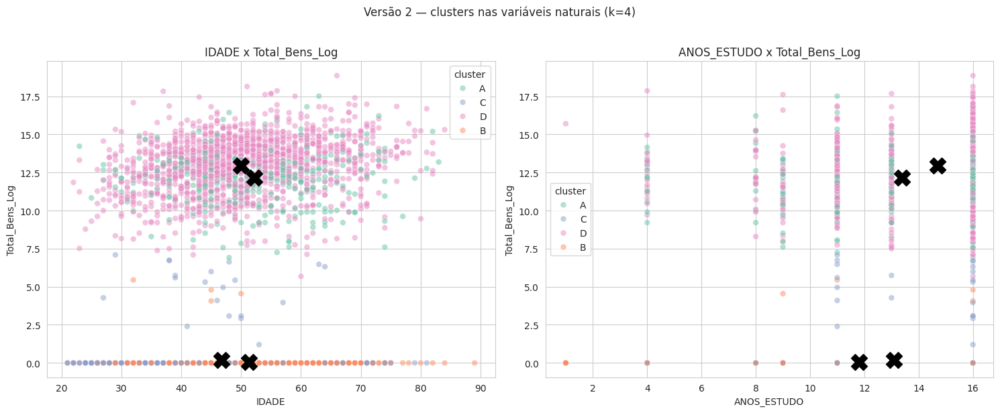

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[0])
axes[0].scatter(df_centroides['IDADE'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[0].set_title('IDADE x Total_Bens_Log')

sns.scatterplot(data=df_cluster, x='ANOS_ESTUDO', y='Total_Bens_Log', hue='cluster', palette=cores_cluster, alpha=0.5, s=40, ax=axes[1])
axes[1].scatter(df_centroides['ANOS_ESTUDO'], df_centroides['Total_Bens_Log'], marker='X', s=300, c='black')
axes[1].set_title('ANOS_ESTUDO x Total_Bens_Log')

plt.suptitle(f'Versão 2 — clusters nas variáveis naturais (k={k_final})', y=1.02)
plt.tight_layout()
plt.show()

---
## Comparando Versão 1 x Versão 2

Duas coisas pra olhar lado a lado: a **métrica de qualidade** (silhouette) e o **tamanho dos grupos** — se a distribuição de candidatos por cluster mudou bastante, é sinal de que a troca de variável/métrica realmente importou.

Versão 1 (CD_GRAU_INSTRUCAO bruto), k=4: silhouette = 0.494
Versão 2 (ANOS_ESTUDO),           k=4: silhouette = 0.499


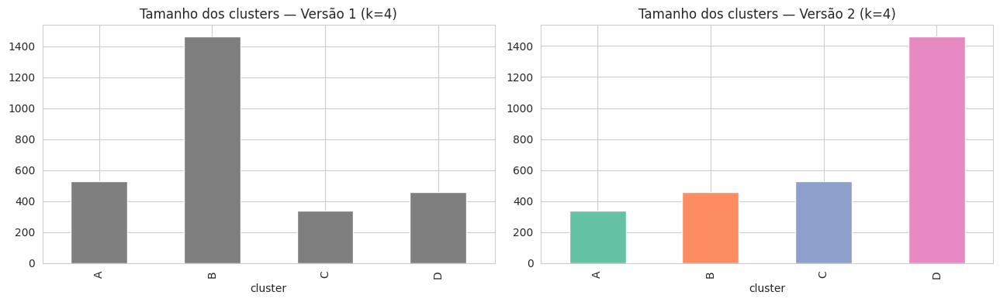

In [ ]:
print(f"Versão 1 (CD_GRAU_INSTRUCAO bruto), k={k_v1}: silhouette = {sil_v1[list(faixa_k).index(k_v1)]:.3f}")
print(f"Versão 2 (ANOS_ESTUDO),           k={k_final}: silhouette = {sil[list(faixa_k).index(k_final)]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_cluster_v1['cluster'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='tab:gray')
axes[0].set_title(f'Tamanho dos clusters — Versão 1 (k={k_v1})')

contagem_v2 = df_cluster['cluster'].value_counts().sort_index()
contagem_v2.plot(kind='bar', ax=axes[1], color=[cores_cluster[c] for c in contagem_v2.index])
axes[1].set_title(f'Tamanho dos clusters — Versão 2 (k={k_final})')

plt.tight_layout()
plt.show()

---
## Perfil demográfico-social de cada cluster

A partir daqui usamos a **Versão 2** (ajustada) como resultado oficial. Primeiro pelas variáveis-driver (já visto acima), agora pelas variáveis de perfil — o que responde de fato a pergunta de negócio.

### Composição demográfica de cada cluster (variáveis de perfil)

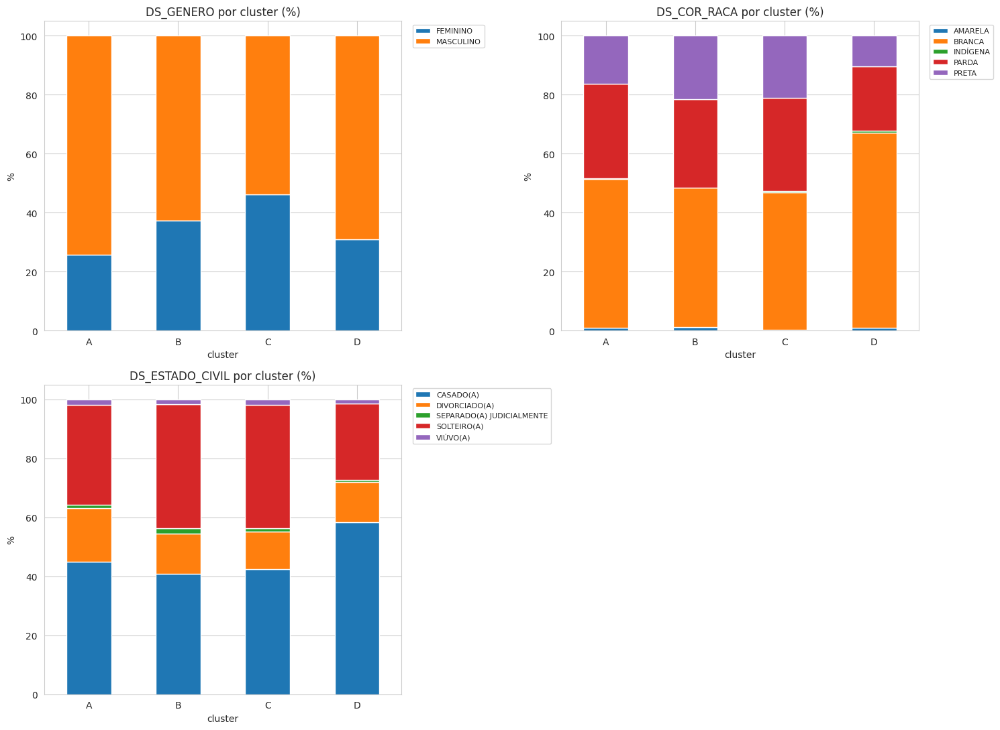

In [ ]:
# DS_SIT_TOT_TURNO fica de fora por enquanto — a eleição de 2026 ainda não ocorreu,
# então essa coluna vem toda nula na base atual.
colunas_perfil = ['DS_GENERO', 'DS_COR_RACA', 'DS_ESTADO_CIVIL']
colunas_perfil = [c for c in colunas_perfil if c in df_cluster.columns]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    pd.crosstab(df_cluster['cluster'], df_cluster[col], normalize='index').mul(100).plot(
        kind='bar', stacked=True, ax=axes[i]
    )
    axes[i].set_title(f'{col} por cluster (%)')
    axes[i].set_ylabel('%')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Pizza: a composição de cada cluster, isoladamente

As barras acima comparam os clusters entre si — é a leitura mais rigorosa quando o que importa é comparar. As pizzas abaixo mostram a mesma informação de um jeito mais familiar pra quem só quer ver "como é o cluster A por dentro", uma variável e um cluster de cada vez.

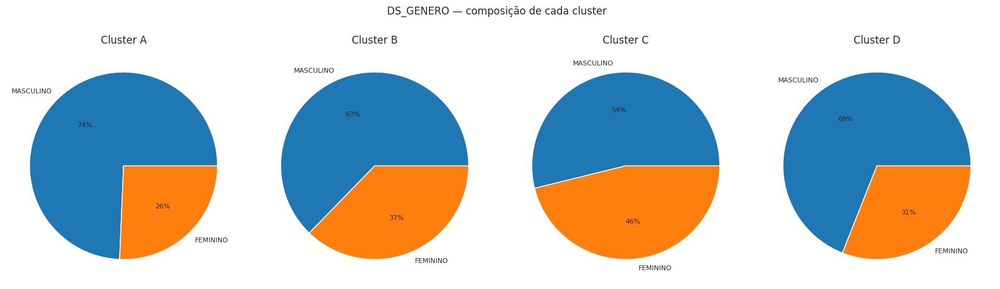

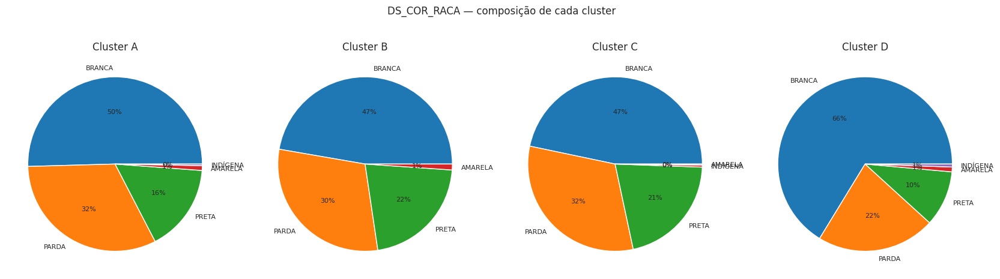

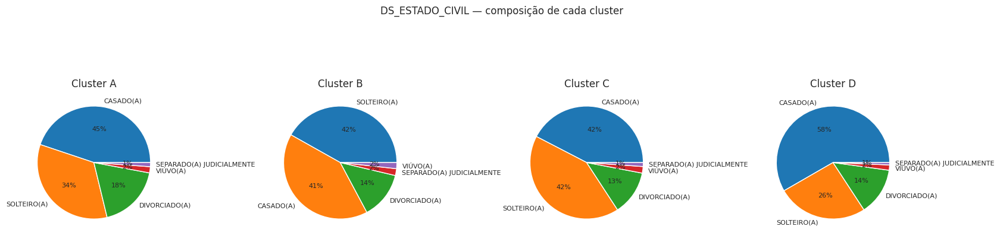

In [ ]:
for col in colunas_perfil:
    fig, axes = plt.subplots(1, k_final, figsize=(4.2 * k_final, 4.5))
    if k_final == 1:
        axes = [axes]

    clusters_ordenados = sorted(df_cluster['cluster'].unique())
    for ax, cl in zip(axes, clusters_ordenados):
        contagem = df_cluster.loc[df_cluster['cluster'] == cl, col].value_counts()
        ax.pie(contagem, labels=contagem.index, autopct='%1.0f%%', textprops={'fontsize': 8})
        ax.set_title(f'Cluster {cl}')

    plt.suptitle(f'{col} — composição de cada cluster', y=1.05)
    plt.tight_layout()
    plt.show()

### Direção inversa: onde cada grupo demográfico está distribuído entre os clusters

Até aqui perguntamos "dentro do cluster X, qual a composição por gênero/cor-raça/estado civil?". Agora invertemos: **de todos os candidatos de um determinado grupo (ex.: todos os do gênero masculino), em quais clusters eles estão?** É a mesma tabela de contingência, só trocando o que normaliza — por categoria demográfica em vez de por cluster.

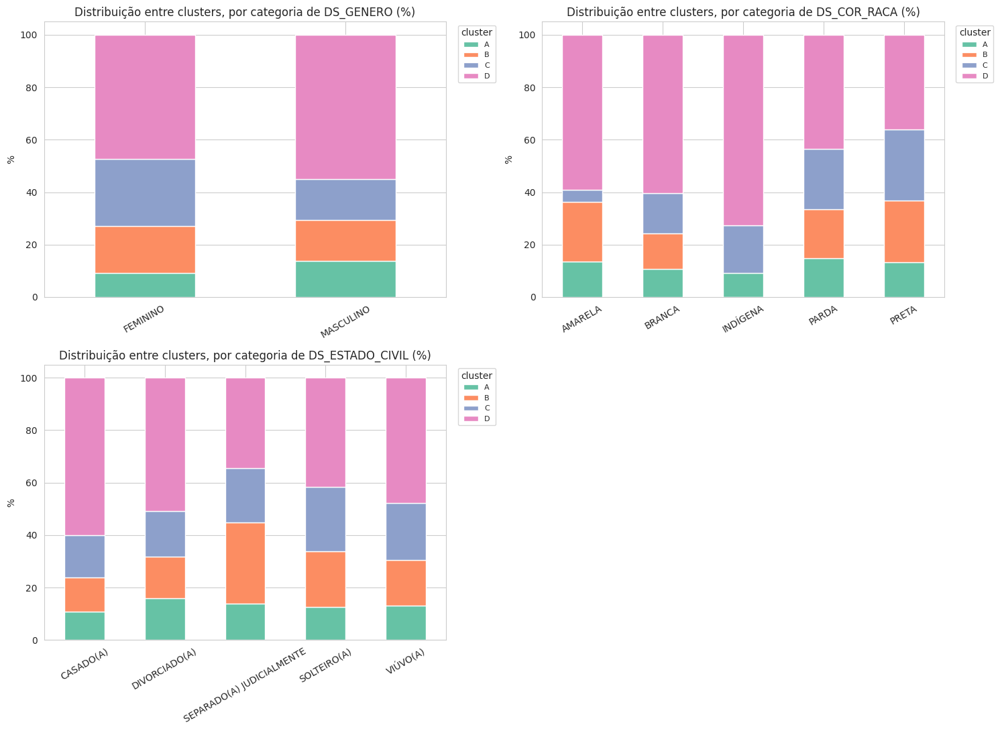

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(colunas_perfil):
    tabela = pd.crosstab(df_cluster[col], df_cluster['cluster'], normalize='index').mul(100)
    tabela = tabela[clusters_ordenados]  # garante a mesma ordem de colunas de cores_cluster
    tabela.plot(kind='bar', stacked=True, ax=axes[i], color=[cores_cluster[c] for c in tabela.columns])
    axes[i].set_title(f'Distribuição entre clusters, por categoria de {col} (%)')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='cluster', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Comparação por UF

Esta seção só roda na visão **Brasil** (quando `UF = None`).

In [ ]:
if UF is None:
    composicao_uf = pd.crosstab(df_cluster['SG_UF'], df_cluster['cluster'], normalize='index').mul(100).round(1)
    display(composicao_uf)
else:
    print(f"UF = {UF!r} — seção não se aplica (dados já filtrados para uma única UF).")

UF = ['SP', 'RJ', 'MG', 'ES'] — seção não se aplica (dados já filtrados para uma única UF).


---
## Respondendo à pergunta de negócio: nomeando os clusters

Esta é a etapa mais importante de toda a análise — é aqui que o K-Means (que só enxerga números) vira uma resposta que faz sentido pra gente. Três ferramentas de apoio, dos números pro nome:

1. **Ficha técnica**: uma tabela única por cluster, juntando drivers e perfil.
2. **O que destaca cada cluster**: um heatmap mostrando só o que foge da média geral — o "diferencial" de cada grupo.
3. **Rascunho automático**: um parágrafo gerado a partir da ficha técnica, pra vocês editarem em vez de escreverem do zero.

### 1) Ficha técnica por cluster

In [ ]:
ficha = df_cluster.groupby('cluster').agg(
    qtd=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
ficha['pct_do_total'] = (ficha['qtd'] / ficha['qtd'].sum() * 100).round(1)

for col in colunas_perfil:
    ficha[f'{col}_predominante'] = df_cluster.groupby('cluster')[col].agg(lambda s: s.mode().iat[0])
    ficha[f'{col}_pct'] = df_cluster.groupby('cluster')[col].apply(
        lambda s: (s == s.mode().iat[0]).mean() * 100
    ).round(1)

ficha

,qtd,idade_media,anos_estudo_medio,patrimonio_mediano,pct_do_total,DS_GENERO_predominante,DS_GENERO_pct,DS_COR_RACA_predominante,DS_COR_RACA_pct,DS_ESTADO_CIVIL_predominante,DS_ESTADO_CIVIL_pct
cluster,,,,,,,,,,,
A,339,52.2,13.4,207108.4,12.1,MASCULINO,74.3,BRANCA,50.4,CASADO(A),44.8
B,459,51.3,11.8,0.0,16.4,MASCULINO,62.7,BRANCA,47.3,SOLTEIRO(A),41.8
C,531,46.7,13.1,0.0,19.0,MASCULINO,53.9,BRANCA,46.7,CASADO(A),42.4
D,1462,50.0,14.7,496441.0,52.4,MASCULINO,69.0,BRANCA,66.3,CASADO(A),58.3


### 2) O que destaca cada cluster (desvio em relação à média geral)

Quanto mais forte a cor (positiva ou negativa), mais aquele cluster se afasta da média geral de candidatos naquela variável — é isso que normalmente vira o "nome" do cluster.

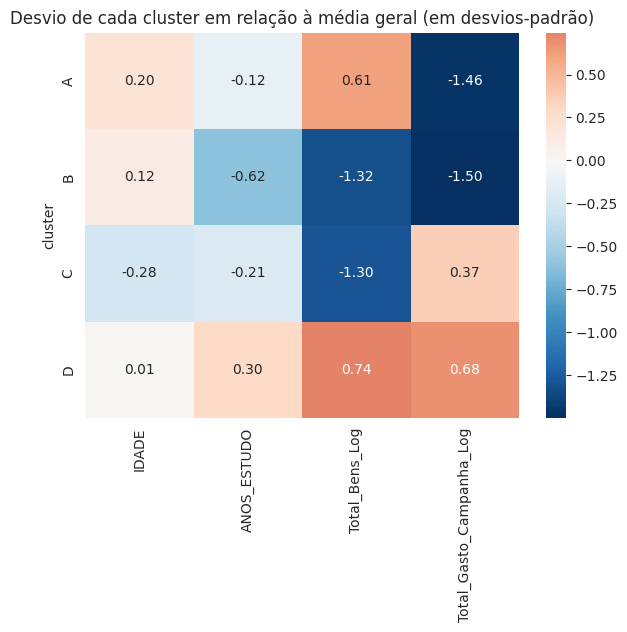

In [ ]:
medias_gerais = df_cluster[colunas_driver].mean()
desvios_gerais = df_cluster[colunas_driver].std()
medias_cluster = df_cluster.groupby('cluster')[colunas_driver].mean()

zscore_cluster = (medias_cluster - medias_gerais) / desvios_gerais

plt.figure(figsize=(7, 1 + k_final))
sns.heatmap(zscore_cluster, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Desvio de cada cluster em relação à média geral (em desvios-padrão)')
plt.xlabel('')
plt.ylabel('cluster')
plt.show()

### 3) Rascunho automático — editem à vontade

In [ ]:
for cl in clusters_ordenados:
    linha = ficha.loc[cl]
    print(f"Cluster {cl}  ({linha['qtd']:.0f} candidatos, {linha['pct_do_total']:.0f}% do total)")
    print(f"  Idade média: {linha['idade_media']:.0f} anos | Escolaridade média: {linha['anos_estudo_medio']:.0f} anos de estudo "
          f"| Patrimônio mediano: R$ {linha['patrimonio_mediano']:,.0f}")
    for col in colunas_perfil:
        print(f"  Predominância em {col}: {linha[f'{col}_predominante']} ({linha[f'{col}_pct']:.0f}%)")
    print(f"  >> Nome sugerido: _______________________")
    print()

Cluster A  (339 candidatos, 12% do total)
  Idade média: 52 anos | Escolaridade média: 13 anos de estudo | Patrimônio mediano: R$ 207,108
  Predominância em DS_GENERO: MASCULINO (74%)
  Predominância em DS_COR_RACA: BRANCA (50%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (45%)
  >> Nome sugerido: _______________________

Cluster B  (459 candidatos, 16% do total)
  Idade média: 51 anos | Escolaridade média: 12 anos de estudo | Patrimônio mediano: R$ 0
  Predominância em DS_GENERO: MASCULINO (63%)
  Predominância em DS_COR_RACA: BRANCA (47%)
  Predominância em DS_ESTADO_CIVIL: SOLTEIRO(A) (42%)
  >> Nome sugerido: _______________________

Cluster C  (531 candidatos, 19% do total)
  Idade média: 47 anos | Escolaridade média: 13 anos de estudo | Patrimônio mediano: R$ 0
  Predominância em DS_GENERO: MASCULINO (54%)
  Predominância em DS_COR_RACA: BRANCA (47%)
  Predominância em DS_ESTADO_CIVIL: CASADO(A) (42%)
  >> Nome sugerido: _______________________

Cluster D  (1462 candidatos, 52%

### Nomes finais dos clusters (K-Means)

Preencham com base nas três ferramentas acima:

- **Cluster A:**
- **Cluster B:**
- **Cluster C:**
- **Cluster D:**


---
# Parte 2 — Bisecting K-Means

**A ideia:** em vez de escolher um `k` e rodar o K-Means uma vez, o Bisecting K-Means começa com **1 cluster (todo mundo)** e vai dividindo em 2 repetidamente — a cada passo, escolhe **um** cluster já existente e o quebra em 2, aumentando `k` em 1 de cada vez (1→2→3→4→...).

O scikit-learn tem `BisectingKMeans`, mas ele só devolve o resultado final — não expõe **qual cluster foi escolhido em cada divisão**, que é exatamente o que você quer enxergar. Por isso implementamos o algoritmo manualmente aqui: a cada passo, guardamos qual cluster foi dividido, o tamanho dele e sua inércia, o que nos dá:

1. **A árvore de divisões** — literalmente o que você pediu para enxergar.
2. **Um critério de parada visual**: enquanto o algoritmo estiver dividindo clusters **grandes**, cada divisão ainda separa bastante gente diferente — informação nova. Quando ele passa a dividir clusters **pequenos**, é sinal de que os grupos grandes e relevantes já foram encontrados, e o que resta é só "aparar as bordas". O gráfico de tamanho por nível, abaixo, mostra exatamente esse ponto de virada.

Usamos a mesma base da Versão 2 (`X`, já padronizada e sem outliers) para ficar diretamente comparável ao K-Means.

### 1) Implementação manual, guardando o histórico de divisões

In [ ]:
def bisecting_kmeans_com_historico(X, k_max, criterio='tamanho', random_state=SEMENTE):
    """
    Roda o Bisecting K-Means manualmente até k_max clusters, guardando o histórico
    de cada divisão (qual cluster foi escolhido, tamanho, inércia).

    criterio:
      'tamanho'  -> a cada passo, divide o cluster com MAIS pontos
      'inercia'  -> a cada passo, divide o cluster com MAIOR inércia (WCSS) interna
                    (é o padrão do sklearn.cluster.BisectingKMeans)
    """
    def inercia(indices):
        if len(indices) < 2:
            return 0.0
        pontos = X[indices]
        centro = pontos.mean(axis=0)
        return float(((pontos - centro) ** 2).sum())

    clusters = {0: np.arange(X.shape[0])}   # cluster raiz = todos os pontos
    historico = []
    proximo_id = 1

    for nivel in range(1, k_max):
        if criterio == 'tamanho':
            id_escolhido = max(clusters, key=lambda cid: len(clusters[cid]))
        else:
            id_escolhido = max(clusters, key=lambda cid: inercia(clusters[cid]))

        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break

        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        filho_a = indices_pai[labels2 == 0]
        filho_b = indices_pai[labels2 == 1]

        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2

        historico.append({
            'k_resultante': nivel + 1,
            'pai_id': id_escolhido, 'pai_tamanho': len(indices_pai), 'pai_inercia': inercia(indices_pai),
            'filho_a_id': id_a, 'filho_a_tamanho': len(filho_a),
            'filho_b_id': id_b, 'filho_b_tamanho': len(filho_b),
        })

        del clusters[id_escolhido]
        clusters[id_a] = filho_a
        clusters[id_b] = filho_b

    return clusters, historico

k_max_bisecting = max(faixa_k) + 1  # mesma faixa usada no K-Means (até 20)
clusters_finais, historico_bisecting = bisecting_kmeans_com_historico(X, k_max_bisecting, criterio='tamanho')

print(f"Divisões realizadas: {len(historico_bisecting)}  (de k=1 até k={k_max_bisecting})")

Divisões realizadas: 19  (de k=1 até k=20)


### 1.1) `'tamanho'` x `'inercia'`: o critério muda a ordem das divisões?

Com `criterio='tamanho'`, o algoritmo **sempre** escolhe o cluster com mais pontos — é a definição do critério, não um efeito colateral. Isso ignora se aquele cluster já está "compacto" (baixa inércia — pouco a ganhar em dividir) ou muito espalhado (alta inércia — muito a ganhar). O padrão do `sklearn.cluster.BisectingKMeans` é `'inercia'`, não `'tamanho'`. Vamos rodar os dois e comparar diretamente se isso muda a ordem das divisões neste dataset.

In [ ]:
_, historico_inercia = bisecting_kmeans_com_historico(X, k_max_bisecting, criterio='inercia')

comparacao_criterios = pd.DataFrame({
    'k': [h['k_resultante'] for h in historico_bisecting],
    'pai_escolhido_por_tamanho': [h['pai_id'] for h in historico_bisecting],
    'pai_escolhido_por_inercia': [h['pai_id'] for h in historico_inercia],
})
comparacao_criterios['mesma_escolha'] = comparacao_criterios['pai_escolhido_por_tamanho'] == comparacao_criterios['pai_escolhido_por_inercia']

qtd_iguais = comparacao_criterios['mesma_escolha'].sum()
print(f"Nos {len(comparacao_criterios)} níveis, os dois critérios escolheram o mesmo cluster para dividir em {qtd_iguais} deles "
      f"({qtd_iguais / len(comparacao_criterios):.0%}).")
display(comparacao_criterios)

Nos 19 níveis, os dois critérios escolheram o mesmo cluster para dividir em 4 deles (21%).


,k,pai_escolhido_por_tamanho,pai_escolhido_por_inercia,mesma_escolha
0,2,0,0,True
1,3,1,2,False
2,4,2,3,False
3,5,4,1,False
4,6,5,8,False
5,7,8,4,False
6,8,6,6,True
7,9,10,5,False
8,10,7,7,True
9,11,3,10,False


Se a coluna `mesma_escolha` for `True` na maior parte das linhas, os dois critérios levam praticamente à mesma árvore neste dataset (tamanho e inércia estão correlacionados aqui). Se divergir bastante, vale a pena trocar `criterio='tamanho'` para `criterio='inercia'` na célula anterior e rodar o restante do notebook de novo — a árvore, a animação e os gráficos abaixo vão refletir a nova ordem de divisões.

### 2) Quando parar? Tamanho e inércia do cluster escolhido, a cada nível

Procure o ponto em que a curva despenca — é onde o algoritmo para de dividir clusters relevantes e passa a dividir sobras.

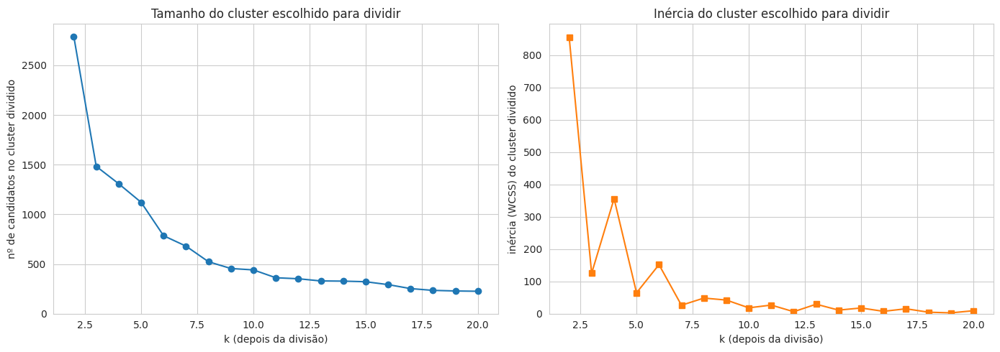

In [ ]:
k_resultante = [h['k_resultante'] for h in historico_bisecting]
tamanho_escolhido = [h['pai_tamanho'] for h in historico_bisecting]
inercia_escolhida = [h['pai_inercia'] for h in historico_bisecting]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_resultante, tamanho_escolhido, marker='o')
axes[0].set_title('Tamanho do cluster escolhido para dividir')
axes[0].set_xlabel('k (depois da divisão)')
axes[0].set_ylabel('nº de candidatos no cluster dividido')
axes[0].set_ylim(bottom=0)
axes[0].grid(True)

axes[1].plot(k_resultante, inercia_escolhida, marker='s', color='tab:orange')
axes[1].set_title('Inércia do cluster escolhido para dividir')
axes[1].set_xlabel('k (depois da divisão)')
axes[1].set_ylabel('inércia (WCSS) do cluster dividido')
axes[1].set_ylim(bottom=0)
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 3) A árvore de divisões

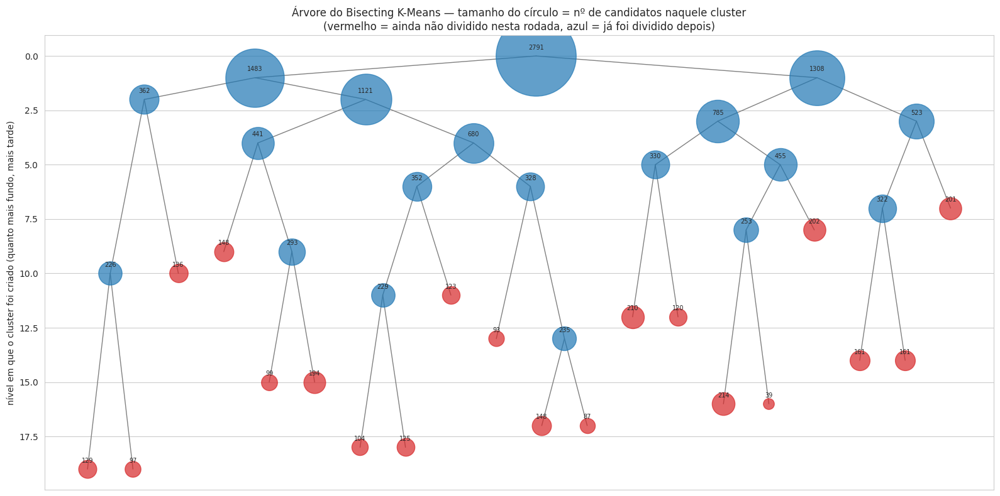

In [ ]:
nos = {0: {'pai': None, 'nivel': 0, 'tamanho': X.shape[0], 'filhos': None}}
for h in historico_bisecting:
    nos[h['pai_id']]['filhos'] = [h['filho_a_id'], h['filho_b_id']]
    nos[h['filho_a_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_a_tamanho'], 'filhos': None}
    nos[h['filho_b_id']] = {'pai': h['pai_id'], 'nivel': h['k_resultante'] - 1, 'tamanho': h['filho_b_tamanho'], 'filhos': None}

# posição horizontal: folhas em ordem, nós internos = média dos filhos (layout clássico de árvore)
posicoes = {}
_x = [0]

def atribuir_x(no_id):
    filhos = nos[no_id]['filhos']
    if filhos is None:
        posicoes[no_id] = _x[0]
        _x[0] += 1
    else:
        for f in filhos:
            atribuir_x(f)
        posicoes[no_id] = sum(posicoes[f] for f in filhos) / len(filhos)

atribuir_x(0)

plt.figure(figsize=(16, 8))
for no_id, info in nos.items():
    if info['filhos']:
        for f in info['filhos']:
            plt.plot([posicoes[no_id], posicoes[f]], [info['nivel'], nos[f]['nivel']],
                      color='gray', linewidth=1, zorder=1)

for no_id, info in nos.items():
    e_folha = info['filhos'] is None
    plt.scatter(posicoes[no_id], info['nivel'], s=40 + info['tamanho'] * 3,
                color='tab:red' if e_folha else 'tab:blue', alpha=0.7, zorder=2)
    plt.text(posicoes[no_id], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

plt.gca().invert_yaxis()
plt.ylabel('nível em que o cluster foi criado (quanto mais fundo, mais tarde)')
plt.xticks([])
plt.title('Árvore do Bisecting K-Means — tamanho do círculo = nº de candidatos naquele cluster\n(vermelho = ainda não dividido nesta rodada, azul = já foi dividido depois)')
plt.tight_layout()
plt.show()

### 3.1) Animação: a árvore crescendo, nível a nível

A árvore estática fica poluída com muitos níveis de uma vez. Esta animação mostra **a mesma árvore**, mas revelando um nível por vez — a cada frame, um nó vermelho (folha ainda não dividida) "explode" em dois, e vira azul. As posições dos nós são as mesmas da árvore estática (calculadas uma vez só), então nada pula de lugar entre frames — só aparece o que é novo.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

historico_por_k = {h['k_resultante']: h for h in historico_bisecting}
ks_disponiveis = list(range(1, max(historico_por_k) + 1))

def estado_arvore_no_k(k):
    """Quais nós já existem, e quais deles ainda são folha (não foram divididos), no frame k."""
    existentes = [nid for nid, info in nos.items() if info['nivel'] <= k - 1]
    set_existentes = set(existentes)
    folhas = []
    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos is None or filhos[0] not in set_existentes:
            folhas.append(nid)
    return existentes, set(folhas)

max_nivel = max(info['nivel'] for info in nos.values())
x_min, x_max = min(posicoes.values()), max(posicoes.values())

fig, ax = plt.subplots(figsize=(16, 8))

def desenhar_frame_arvore(k):
    ax.clear()
    existentes, folhas = estado_arvore_no_k(k)
    set_existentes = set(existentes)

    for nid in existentes:
        filhos = nos[nid]['filhos']
        if filhos:
            for f in filhos:
                if f in set_existentes:
                    ax.plot([posicoes[nid], posicoes[f]], [nos[nid]['nivel'], nos[f]['nivel']],
                            color='gray', linewidth=1, zorder=1)

    for nid in existentes:
        info = nos[nid]
        cor = 'tab:red' if nid in folhas else 'tab:blue'
        ax.scatter(posicoes[nid], info['nivel'], s=40 + info['tamanho'] * 3, color=cor, alpha=0.7, zorder=2)
        ax.text(posicoes[nid], info['nivel'] - 0.3, str(info['tamanho']), ha='center', fontsize=7)

    ax.set_xlim(x_min - 1, x_max + 1)
    ax.set_ylim(max_nivel + 1, -1)  # eixo fixo e invertido (raiz no topo), sem "pulos" entre frames
    ax.set_xticks([])
    ax.set_ylabel('nível em que o cluster foi criado')
    if k in historico_por_k:
        h = historico_por_k[k]
        ax.set_title(f'Árvore do Bisecting K-Means — k={k}  (dividiu um cluster de {h["pai_tamanho"]} candidatos)')
    else:
        ax.set_title(f'Árvore do Bisecting K-Means — k={k} (estado inicial, 1 cluster só)')

anim = FuncAnimation(fig, desenhar_frame_arvore, frames=ks_disponiveis, interval=800, repeat=True)
plt.close(fig)  # evita mostrar também uma figura estática duplicada, além da animação
HTML(anim.to_jshtml())

> Se a animação demorar pra renderizar (muitos frames), aumente `interval` (ela roda mais devagar) ou reduza `k_max_bisecting` mais acima. Pra usar fora do notebook (ex.: num slide): `anim.save('arvore_bisecting.gif', writer='pillow')`.

### 4) Escolhendo k e extraindo o resultado final

Com base nos dois gráficos acima (tamanho/inércia por nível + a árvore), escolha um `k` — é o ponto em que dividir deixou de parecer valer a pena.

In [ ]:
k_bisecting = 4  # ajuste conforme as duas seções anteriores

# Reconstrói a partição em k_bisecting clusters, refazendo as divisões do histórico até esse ponto.
# Refazer o KMeans(n_clusters=2) é determinístico (mesma SEMENTE, mesmos dados de entrada),
# então dá exatamente a mesma divisão já registrada — sem precisar guardar todos os índices no histórico.
clusters_no_k = {0: np.arange(X.shape[0])}
for h in historico_bisecting:
    if h['k_resultante'] > k_bisecting:
        break
    indices_pai = clusters_no_k.pop(h['pai_id'])
    km2 = KMeans(n_clusters=2, random_state=SEMENTE, n_init=10)
    labels2 = km2.fit_predict(X[indices_pai])
    clusters_no_k[h['filho_a_id']] = indices_pai[labels2 == 0]
    clusters_no_k[h['filho_b_id']] = indices_pai[labels2 == 1]

# transformar em uma coluna de cluster no df_cluster (rótulos A, B, C... por ordem de tamanho)
ids_por_tamanho = sorted(clusters_no_k, key=lambda cid: len(clusters_no_k[cid]), reverse=True)
df_cluster['cluster_bisecting'] = ''
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    df_cluster.iloc[clusters_no_k[cid], df_cluster.columns.get_loc('cluster_bisecting')] = letra

df_cluster['cluster_bisecting'].value_counts().sort_index()

,count
cluster_bisecting,
A,1121
B,785
C,523
D,362


Ordem por tamanho: ['A', 'B', 'C', 'D']
                       IDADE  ANOS_ESTUDO  Total_Bens_Log
cluster_bisecting                                        
A                  50.671722    15.941124       13.138445
B                  51.670064    12.447134        5.101892
C                  46.772467    13.059273        0.109685
D                  47.900552    10.881215       12.100802


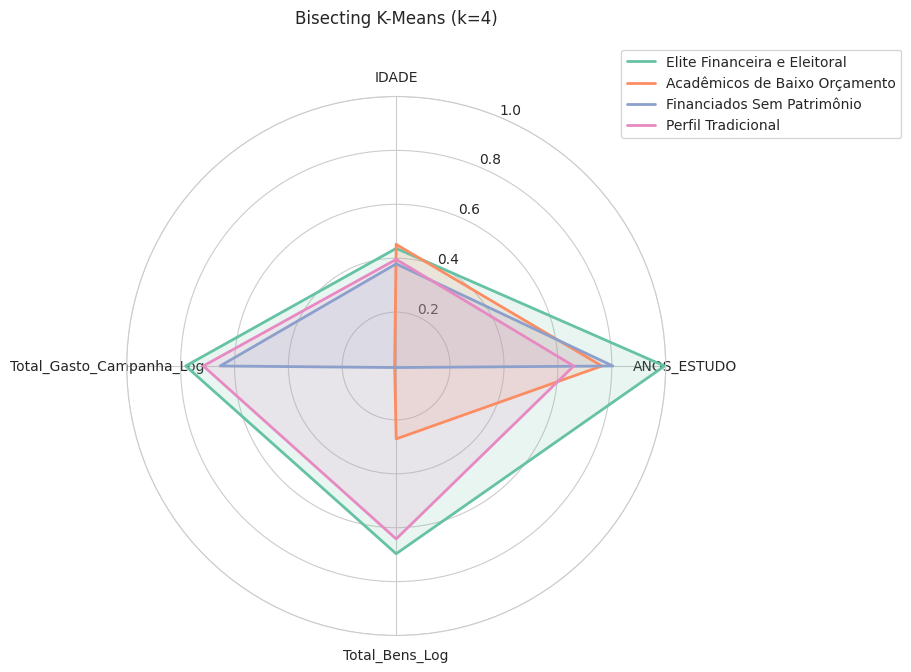

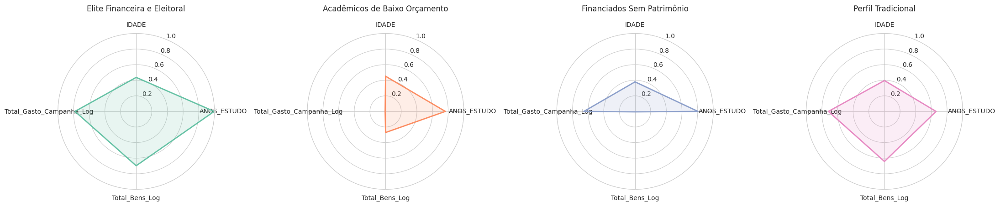

In [ ]:
COL = "cluster_bisecting"  # no Bisecting

# --- nomes (o código que você já tem) ---
ordem_por_tamanho = (
    df_cluster[COL].value_counts().sort_values(ascending=False).index.tolist()
)
ficha = (
    df_cluster.groupby(COL)[["IDADE", "ANOS_ESTUDO", "Total_Bens_Log"]]
    .mean()
    .loc[ordem_por_tamanho]
)
print("Ordem por tamanho:", ordem_por_tamanho)
print(ficha)

NOMES_POR_TAMANHO = [
    "Elite Financeira e Eleitoral",   # edite conforme a ficha
    "Acadêmicos de Baixo Orçamento",
    "Financiados Sem Patrimônio",
    "Perfil Tradicional",
]
mapa = dict(zip(ordem_por_tamanho, NOMES_POR_TAMANHO[: len(ordem_por_tamanho)]))
df_cluster["cluster_nome"] = df_cluster[COL].map(mapa)

# --- centróides e cores na mesma ordem dos nomes ---
nomes_ordenados = [mapa[c] for c in ordem_por_tamanho]
cores_nome = dict(
    zip(nomes_ordenados, sns.color_palette("Set2", n_colors=len(nomes_ordenados)))
)

centroides_norm = np.vstack(
    [
        X[df_cluster[COL].values == letra].mean(axis=0)
        for letra in ordem_por_tamanho
    ]
)

# todos juntos
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plot_radar(
    ax,
    centroides_norm,
    colunas_driver,
    nomes_ordenados,      # <- nomes, não letras
    cores_nome,
    f"Bisecting K-Means (k={len(nomes_ordenados)})",
)
ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1))
plt.show()

# um por cluster
k_b = len(nomes_ordenados)
ncols = min(k_b, 4)
nrows = -(-k_b // ncols)
fig, axes = plt.subplots(
    nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows), subplot_kw=dict(polar=True)
)
axes = np.array(axes).flatten()

for i, nome in enumerate(nomes_ordenados):
    plot_radar(
        axes[i],
        [centroides_norm[i]],
        colunas_driver,
        [nome],
        cores_nome,
        nome,               # título = nome
    )
for j in range(k_b, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [ ]:
# rótulo “oficial” daqui pra frente
df_cluster["cluster_bisecting"] = df_cluster["cluster_nome"]

### 5) Comparando com o K-Means (Versão 2)

Silhouette — K-Means (V2, k=4):        0.499
Silhouette — Bisecting K-Means (k=4): 0.346


,qtd_candidatos,idade_media,anos_estudo_medio,patrimonio_mediano
cluster_bisecting,,,,
Acadêmicos de Baixo Orçamento,785,51.7,12.4,0.0
Elite Financeira e Eleitoral,1121,50.7,15.9,635382.0
Financiados Sem Patrimônio,523,46.8,13.1,0.0
Perfil Tradicional,362,47.9,10.9,214154.9


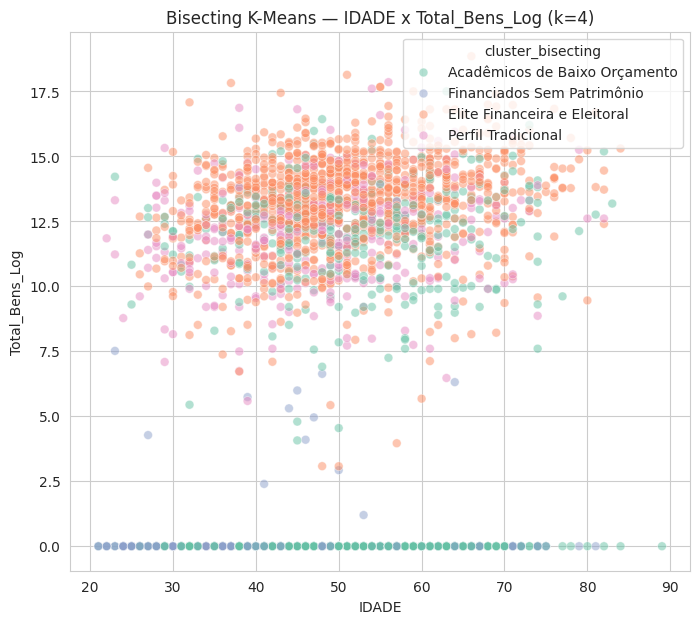

In [ ]:
labels_bisecting = df_cluster['cluster_bisecting'].values
print(f"Silhouette — K-Means (V2, k={k_final}):        {silhouette_score(X, df_cluster['cluster']):.3f}")
print(f"Silhouette — Bisecting K-Means (k={k_bisecting}): {silhouette_score(X, labels_bisecting):.3f}")

resumo_bisecting = df_cluster.groupby('cluster_bisecting').agg(
    qtd_candidatos=('SQ_CANDIDATO', 'count'),
    idade_media=('IDADE', 'mean'),
    anos_estudo_medio=('ANOS_ESTUDO', 'mean'),
    patrimonio_mediano=('Total_Bens', 'median'),
).round(1)
display(resumo_bisecting)

clusters_bisecting_ordenados = sorted(df_cluster['cluster_bisecting'].unique())
cores_bisecting = dict(zip(clusters_bisecting_ordenados, sns.color_palette('Set2', n_colors=len(clusters_bisecting_ordenados))))

plt.figure(figsize=(8, 7))
sns.scatterplot(data=df_cluster, x='IDADE', y='Total_Bens_Log', hue='cluster_bisecting', palette=cores_bisecting, alpha=0.5, s=40)
plt.title(f'Bisecting K-Means — IDADE x Total_Bens_Log (k={k_bisecting})')
plt.show()

In [ ]:
df_cluster[["SQ_CANDIDATO", COL, "cluster_nome"]].to_csv(
    "dados/candidatos_cluster_DEPUTADO_FEDERAL_SP_RJ_MG_ES_2026.csv",
    index=False,
)

**Interpretação:** compare o `resumo_bisecting` com o `resumo_driver` do K-Means e a silhouette dos dois. Se os grupos ficarem parecidos, é um bom sinal de que a estrutura é real (dois algoritmos diferentes concordando); se ficarem bem diferentes, vale a pena entender por quê — o K-Means busca uma solução global pra todo o `k` de uma vez, enquanto o Bisecting constrói de forma incremental, e pode ficar "preso" a decisões tomadas em níveis anteriores.

O mesmo kit de nomeação da Parte 1 (ficha técnica, heatmap de desvio, rascunho automático) pode ser reaplicado aqui trocando `cluster` por `cluster_bisecting` nas agregações — fica como exercício.

---
## Fechamento e próximos passos

Duas famílias de algoritmo até aqui:

- **K-Means (Parte 1)**, em duas rodadas — mostrando o efeito de tratar uma variável ordinal como intervalar, e de usar mais de uma métrica pra escolher `k`.
- **Bisecting K-Means (Parte 2)** — construção incremental e visual, com uma árvore mostrando a ordem das divisões e um critério de parada baseado em quando parar de dividir clusters grandes.

Na próxima atualização: **DBSCAN** e **clusterização hierárquica**, reaproveitando a mesma base e a mesma pergunta de negócio.

# Fase 3 — Regras de Associação: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Que combinações de características dos candidatos aparecem juntas com mais frequência do que se fossem independentes? Em particular: quais atributos (partido, gênero, escolaridade, cor/raça, UF de nascimento) estão associados a cada perfil identificado na Fase 2 — e, assim que a eleição ocorrer, a ser eleito?**

Até aqui, a clusterização (Fase 2) agrupou candidatos por **distância** em variáveis numéricas (idade, escolaridade, patrimônio). Regras de associação fazem uma pergunta diferente: em vez de "quem está perto de quem", **quais combinações de atributos categóricos aparecem juntas com mais frequência do que o acaso explicaria**? A técnica clássica pra isso é o **Apriori**, que originalmente resolve o problema da "cesta de compras" (que produtos são comprados juntos) — aqui, cada candidato é uma cesta, e cada valor de cada variável categórica (partido, gênero, escolaridade...) é um item dessa cesta.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2, para carregar o arquivo certo.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
CARGO = "DEPUTADO FEDERAL"
UF = ["SP", "RJ", "MG", "ES"]               # mesmo valor usado na Fase 0/1, 0/1/2
ANO_ELEICAO = 2026


## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Apriori precisa de **itens categóricos**, não de distância — mas queremos incluir o cluster da Fase 2 como mais um item da cesta (pra achar regras do tipo "esse perfil de candidato é dos Abastados"). Na Fase 2 (`02_clusterizacao.ipynb`), o **Bisecting K-Means com k=3** (critério de inércia média) foi o resultado final escolhido, e os três clusters foram batizados a partir da ficha técnica e da composição demográfica/partidária:

- **Abastados** — 78% dos candidatos, os únicos com algum patrimônio declarado.
- **Jovens** — o grupo mais novo (39 anos em média), quase sem patrimônio declarado.
- **Sem bens e alta escolaridade** — 100% sem patrimônio declarado, a maior escolaridade média dos três (e também o grupo mais velho).

Recalculamos aqui, rapidamente, a mesma partição (mesma `SEMENTE`, mesmo critério, mesmos nomes) — mesma lógica de auto-suficiência já usada no `02_clusterizacao_outros.ipynb`.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from mlxtend.frequent_patterns import apriori, association_rules

!pip install pyvis # Install pyvis library
from pyvis.network import Network
from IPython.display import IFrame

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # não truncar antecedents/consequents nas tabelas

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_cargo = CARGO.replace(' ', '_')

# Formatação corrigida para corresponder ao nome real do ficheiro
if UF is not None:
    if isinstance(UF, list):
        # Gera o formato ('SP', 'RJ', 'MG', 'ES')
        nome_uf_formatted = str(tuple(UF))
    else:
        nome_uf_formatted = UF
else:
    nome_uf_formatted = 'BRASIL'

arquivo = f"/content/drive/MyDrive/dados/candidatos_{nome_cargo}_{nome_uf_formatted}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

Carregado: /content/drive/MyDrive/dados/candidatos_DEPUTADO_FEDERAL_('SP', 'RJ', 'MG', 'ES')_2026.csv  ->  2800 candidatos, 59 colunas


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531643,3090,JOÃO BATISTA DE ASSIS,SARGENTO ASSIS,#NULO,3152826737,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1974-03-23,14740511465,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,278,VEREADOR,-1,#NULO,400000.0,92500.0,0.0,0.0,0.0,0.0,492500.0,13.107252,52
1,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531644,3010,FABÍOLA SAQUETTO DI TOMMASO,FABÍOLA SAQUETTO,#NULO,7106495760,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1977-08-06,17880711481,4,FEMININO,8,SUPERIOR COMPLETO,5,VIÚVO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.000000,49
2,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531645,3060,AILANA REGINA PELISSARI SIMONELLI MOREIRA,AILANA PELISSARI,#NULO,9365295718,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1978-11-28,19854371449,4,FEMININO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,999,OUTROS,-1,#NULO,0.0,0.0,0.0,0.0,0.0,60000.0,60000.0,11.002117,47
3,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531646,3040,JÚLIO CÉSAR COSTA CAIADO,DR. JÚLIO CAIADO,#NULO,33301018653,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1959-04-17,11524561414,2,MASCULINO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,112,VETERINÁRIO,-1,#NULO,900000.0,115000.0,0.0,0.0,0.0,0.0,1015000.0,13.830400,67
4,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531647,3033,LEONARDO RODRIGO NASCIMENTO,LÉO SINDICO,#NULO,7877752741,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1979-11-14,19497891406,2,MASCULINO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,257,EMPRESÁRIO,-1,#NULO,300000.0,52000.0,0.0,0.0,0.0,0.0,352000.0,12.771389,46


In [ ]:
# 1. Carregar o dataset de despesas ajustando o encoding e separador
caminho_despesas = "/content/drive/MyDrive/dados/despesas_contratadas_candidatos_2026_BRASIL.csv"
df_dc_final = pd.read_csv(caminho_despesas, encoding='latin1', sep=';')

# 2. Garantir que as chaves de junção (SQ_CANDIDATO) estão no mesmo formato (string)
df['SQ_CANDIDATO'] = df['SQ_CANDIDATO'].astype(str).str.strip()
df_dc_final['SQ_CANDIDATO'] = df_dc_final['SQ_CANDIDATO'].astype(str).str.strip()

# 3. Converter a coluna de valores para float
if df_dc_final['VR_DESPESA_CONTRATADA'].dtype == 'object':
    df_dc_final['VR_DESPESA_CONTRATADA'] = (
        df_dc_final['VR_DESPESA_CONTRATADA']
        .astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
df_dc_final['VR_DESPESA_CONTRATADA'] = pd.to_numeric(df_dc_final['VR_DESPESA_CONTRATADA'], errors='coerce').fillna(0)

# 4. Agrupar por SQ_CANDIDATO e calcular o total
df_despesas_totais = (
    df_dc_final.groupby('SQ_CANDIDATO')['VR_DESPESA_CONTRATADA']
    .sum()
    .reset_index()
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Despesas'})
)

# 5. Remover a coluna se já existia de execuções anteriores para evitar duplicados (ex: Total_Despesas_x)
if 'Total_Despesas' in df.columns:
    df.drop(columns=['Total_Despesas'], inplace=True)

# 6. Fazer a junção (merge)
df = df.merge(df_despesas_totais, on='SQ_CANDIDATO', how='left')

# 7. Tratar nulos e calcular a transformação logarítmica
df['Total_Despesas'] = df['Total_Despesas'].fillna(0)
df['Total_Despesas_Log'] = np.log1p(df['Total_Despesas'])

print("Variável Total_Despesas adicionada com sucesso!\n")
print(df[['SQ_CANDIDATO', 'Total_Despesas', 'Total_Despesas_Log']].head())

Variável Total_Despesas adicionada com sucesso!

  SQ_CANDIDATO  Total_Despesas  Total_Despesas_Log
0  80002531643            0.00            0.000000
1  80002531644         3750.00            8.229778
2  80002531645         5000.00            8.517393
3  80002531646            9.95            2.393339
4  80002531647         5275.19            8.570960


In [ ]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)


In [ ]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Despesas_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
print(f"Base para clusterização/regras: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base para clusterização/regras: 2800 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


In [ ]:

def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — mas só
    devolve a partição final em k_max clusters, sem guardar o histórico de divisões (essa
    exploração já foi feita e documentada lá)."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: len(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = 4  # mesmo k escolhido no 02_clusterizacao.ipynb (Parte 2)

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Elite Financeira e Eleitoral',
    'B': 'Acadêmicos de Baixo Orçamento',
    'C': 'Financiados Sem Patrimônio',
    'D': 'Perfil Tradicional'
    #'E': '...'
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)

df_cluster['cluster'].value_counts()


,count
cluster,
Elite Financeira e Eleitoral,1127
Acadêmicos de Baixo Orçamento,795
Financiados Sem Patrimônio,515
Perfil Tradicional,363


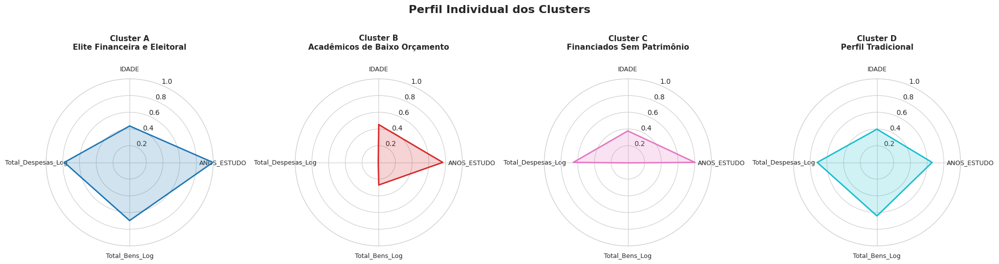

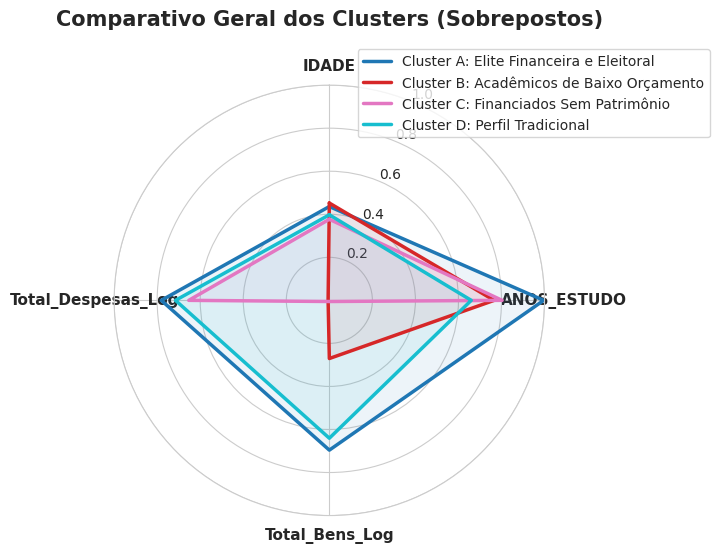

In [ ]:
from math import pi
import matplotlib.pyplot as plt
import numpy as np

# --- 1. CONFIGURAÇÕES GERAIS ---
k_bisecting = 4
letras_ordenadas = [chr(65 + i) for i in range(k_bisecting)]  # Gera ['A', 'B', 'C', 'D', 'E']

cols_radar = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Despesas_Log']

cores_radar = {
    'A': '#1f77b4',  # Azul
    'B': '#d62728',  # Vermelho
    'C': '#e377c2',  # Rosa
    'D': '#17becf',  # Ciano
    'E': '#ff7f0e'   # Laranja
}

# --- 2. CÁLCULO E NORMALIZAÇÃO DOS CENTROIDES ---
df_radar = df_cluster[cols_radar].copy()
df_radar = (df_radar - df_radar.min()) / (df_radar.max() - df_radar.min())
df_radar['cluster_letra'] = df_cluster['cluster_bisecting']

centroides_df = df_radar.groupby('cluster_letra')[cols_radar].mean().loc[letras_ordenadas]

# Preparação dos ângulos
n_eixos = len(cols_radar)
angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
angulos += angulos[:1]  # Fechar o polígono


# ==============================================================================
# PARTE 1: GRÁFICOS SEPARADOS (UM RADAR POR CLUSTER)
# ==============================================================================
ncols = 3 if k_bisecting > 4 else 4
nrows = -(-k_bisecting // ncols)

fig_sep, axes_sep = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 5 * nrows), subplot_kw=dict(polar=True)
)
axes_sep = np.array(axes_sep).flatten() if k_bisecting > 1 else [axes_sep]

for i, letra in enumerate(letras_ordenadas):
    ax = axes_sep[i]
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(cols_radar, fontsize=9)
    ax.set_ylim(0, 1)

    valores = centroides_df.loc[letra, cols_radar].values.tolist()
    valores += valores[:1]

    cor = cores_radar.get(letra, '#333333')
    ax.plot(angulos, valores, linewidth=2, color=cor)
    ax.fill(angulos, valores, alpha=0.2, color=cor)

    nome_descritivo = NOMES_CLUSTER_BISECTING.get(letra, "")
    ax.set_title(
        f"Cluster {letra}\n{nome_descritivo}",
        y=1.15,
        fontsize=11,
        fontweight="bold"
    )

# Deleta eixos extras da grade se houver
for j in range(len(letras_ordenadas), len(axes_sep)):
    fig_sep.delaxes(axes_sep[j])

fig_sep.suptitle("Perfil Individual dos Clusters", fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


# ==============================================================================
# PARTE 2: GRÁFICO COMPARATIVO (TODOS OS CLUSTERS JUNTOS)
# ==============================================================================
fig_junto, ax_junto = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

ax_junto.set_theta_offset(pi / 2)
ax_junto.set_theta_direction(-1)
ax_junto.set_xticks(angulos[:-1])
ax_junto.set_xticklabels(cols_radar, fontsize=11, fontweight='bold')
ax_junto.set_ylim(0, 1)

for letra in letras_ordenadas:
    valores = centroides_df.loc[letra, cols_radar].values.tolist()
    valores += valores[:1]

    cor = cores_radar.get(letra, '#333333')
    label_txt = f"Cluster {letra}: {NOMES_CLUSTER_BISECTING.get(letra, '')}"

    ax_junto.plot(angulos, valores, linewidth=2.5, label=label_txt, color=cor)
    ax_junto.fill(angulos, valores, alpha=0.08, color=cor)

plt.title("Comparativo Geral dos Clusters (Sobrepostos)", y=1.12, fontsize=15, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

## Montando a "cesta" de itens

Apriori não trabalha com números contínuos como o K-Means — ele precisa de **itens binários** (presente/ausente), do mesmo jeito que "pão" e "leite" são itens numa cesta de supermercado. Cada linha vira uma "cesta" (um candidato), e cada valor de cada variável categórica vira um "item" via one-hot encoding (`SG_PARTIDO=PT`, `DS_GENERO=FEMININO`, `cluster=Abastados`, ...).

Variáveis escolhidas:
- `SG_PARTIDO`, `DS_GENERO`, `DS_GRAU_INSTRUCAO`, `DS_ESTADO_CIVIL`, `DS_COR_RACA`, `SG_UF_NASCIMENTO` — perfil do candidato.
- `cluster` — o nome do cluster da Fase 2 (Bisecting K-Means, k=3), recalculado acima. Incluir o cluster como item deixa a pergunta "o que caracteriza cada cluster?" (já respondida via ficha técnica na Fase 2) ser respondida de novo do ponto de vista de regras — e permite achar combinações de 2+ variáveis que sozinhas não bastariam.
- `SG_UF` — só entra na visão Brasil (`UF=None`); com uma UF fixa ela teria um único valor e não discriminaria nada.
- `DS_SIT_TOT_TURNO` (eleito ou não) — só entra depois que a eleição de fato ocorrer (a coluna hoje vem toda com o mesmo valor, `#NULO`). A seção que usa isso fica pronta, mas roda condicionalmente lá na frente.

`DS_OCUPACAO` fica de fora por ora: são 49 categorias diferentes pra só ~200 candidatos — a maioria das ocupações teria 1 ou 2 candidatos, suporte baixo demais pra dizer qualquer coisa. Fica como exercício: agrupem em categorias maiores (ex.: "política", "direito", "saúde", "educação", "empresário"...) e testem.


In [ ]:
# 1. Categorizar a variável contínua em faixas (Baixa, Média, Alta)
df_cluster['FAIXA_DESPESAS'] = pd.qcut(
    df_cluster['Total_Despesas'],
    q=3,
    labels=['Despesa Baixa', 'Despesa Média', 'Despesa Alta'],
    duplicates='drop'
)

# 2. Adicionar 'FAIXA_DESPESAS' na sua lista de colunas para o Apriori
colunas_apriori = [
    'SG_PARTIDO', 'DS_GENERO', 'DS_GRAU_INSTRUCAO', 'DS_ESTADO_CIVIL',
    'DS_COR_RACA', 'SG_UF_NASCIMENTO', 'cluster', 'FAIXA_DESPESAS'  # <-- ADICIONADO AQUI
]

if UF is None:
    colunas_apriori.append('SG_UF')

# a eleição de 2026 ainda não ocorreu -> DS_SIT_TOT_TURNO vem toda com o mesmo valor por enquanto
usar_resultado_eleicao = df_cluster['DS_SIT_TOT_TURNO'].nunique() > 1
if usar_resultado_eleicao:
    colunas_apriori.append('DS_SIT_TOT_TURNO')

cesta_base = df_cluster[['SQ_CANDIDATO'] + colunas_apriori].copy()
cesta = pd.get_dummies(cesta_base, columns=colunas_apriori, prefix_sep='=')
cesta = cesta.set_index('SQ_CANDIDATO')

print(f"{cesta.shape[0]} candidatos (cestas) x {cesta.shape[1]} itens possíveis (um por valor de cada variável)")
cesta_base.head()


2800 candidatos (cestas) x 79 itens possíveis (um por valor de cada variável)


,SQ_CANDIDATO,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,SG_UF_NASCIMENTO,cluster,FAIXA_DESPESAS
0,80002531643,NOVO,MASCULINO,SUPERIOR COMPLETO,CASADO(A),PRETA,ES,Acadêmicos de Baixo Orçamento,Despesa Baixa
1,80002531644,NOVO,FEMININO,SUPERIOR COMPLETO,VIÚVO(A),BRANCA,ES,Financiados Sem Patrimônio,Despesa Média
2,80002531645,NOVO,FEMININO,SUPERIOR COMPLETO,SOLTEIRO(A),PARDA,ES,Elite Financeira e Eleitoral,Despesa Média
3,80002531646,NOVO,MASCULINO,SUPERIOR COMPLETO,DIVORCIADO(A),BRANCA,ES,Elite Financeira e Eleitoral,Despesa Baixa
4,80002531647,NOVO,MASCULINO,SUPERIOR COMPLETO,SOLTEIRO(A),PARDA,ES,Elite Financeira e Eleitoral,Despesa Média


## Itens frequentes: o que aparece sozinho, com que frequência

O Apriori funciona em duas etapas. Primeiro, encontra **itemsets frequentes** — combinações de 1, 2, 3... itens que aparecem juntas em pelo menos `min_suporte` das cestas. Só depois, na segunda etapa, ele vira **regras** (`A → B`). Começamos pelos itemsets de um item só — a frequência "crua" de cada valor, antes de cruzar qualquer coisa.


In [ ]:
min_suporte = 0.02  # ~4 candidatos; ajuste se quiser regras mais raras (menor) ou mais comuns (maior)

itens_frequentes = apriori(cesta, min_support=min_suporte, use_colnames=True)
print(f"{len(itens_frequentes)} itemsets frequentes (min_suporte={min_suporte})")

individuais = itens_frequentes[itens_frequentes['itemsets'].apply(lambda x: len(x) == 1)].copy()
individuais['item'] = individuais['itemsets'].apply(lambda x: next(iter(x)))
individuais['qtd_candidatos'] = (individuais['support'] * len(cesta)).round().astype(int)
individuais.sort_values('support', ascending=False)[['item', 'support', 'qtd_candidatos']].head(15)


1508 itemsets frequentes (min_suporte=0.02)


,item,support,qtd_candidatos
22,DS_GENERO=MASCULINO,0.657857,1842
27,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,0.597857,1674
32,DS_COR_RACA=BRANCA,0.578571,1620
29,DS_ESTADO_CIVIL=CASADO(A),0.508571,1424
41,cluster=Elite Financeira e Eleitoral,0.402500,1127
21,DS_GENERO=FEMININO,0.342143,958
46,FAIXA_DESPESAS=Despesa Alta,0.333571,934
44,FAIXA_DESPESAS=Despesa Baixa,0.333214,933
45,FAIXA_DESPESAS=Despesa Média,0.333214,933
31,DS_ESTADO_CIVIL=SOLTEIRO(A),0.324643,909


### Suporte, confiança e lift — o que cada métrica mede

Regras de associação têm o formato **"se A, então B"** (A = antecedente, B = consequente), e três números resumem o quão forte é essa relação:

- **Suporte** — fração de candidatos em que A e B aparecem juntos: `suporte(A→B) = P(A e B)`. Mede o quão comum é a combinação; suporte baixo (poucos candidatos) é terreno fértil pra coincidência.
- **Confiança** — entre os candidatos que têm A, qual fração também tem B: `confiança(A→B) = P(B | A) = suporte(A e B) / suporte(A)`. É a "taxa de acerto" da regra.
- **Lift** — o quanto a confiança da regra é maior (ou menor) do que se A e B fossem independentes: `lift(A→B) = confiança(A→B) / suporte(B)`. `lift = 1` → A e B são independentes (a regra não diz nada); `lift > 1` → aparecem juntos mais do que o esperado ao acaso; `lift < 1` → aparecem juntos menos do que o esperado.

**Um cuidado importante nesta base:** ela tem só ~200 candidatos espalhados por 27 partidos e 27 estados — em média, uns 7 candidatos por partido ou por UF. Com grupos tão pequenos, bastam 3 ou 4 coincidências pra um lift parecer altíssimo, sem que isso signifique relação real nenhuma. Por isso toda tabela de regras abaixo vem com uma coluna `qtd_candidatos` — sempre olhem ela antes de confiar num lift alto.


In [ ]:
regras = association_rules(itens_frequentes, metric='lift', min_threshold=1)
regras['qtd_candidatos'] = (regras['support'] * len(cesta)).round().astype(int)
regras = regras.sort_values('confidence', ascending=False)


def formatar_regras(df_regras):
    """Troca antecedents/consequents (frozenset) por texto legível, só pra exibição —
    os dados originais (usados pra filtrar/ordenar) continuam intactos."""
    df_fmt = df_regras.copy()
    df_fmt['antecedents'] = df_fmt['antecedents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    df_fmt['consequents'] = df_fmt['consequents'].apply(lambda x: ', '.join(sorted(str(i) for i in x)))
    return df_fmt


print(f"{len(regras)} regras (lift >= 1)")
formatar_regras(regras[['antecedents', 'consequents', 'qtd_candidatos', 'support', 'confidence', 'lift']].head(10))

# Filtra regras onde o Cluster está no antecedente e a Faixa de Despesa está no consequente
regras_cluster_despesa = regras[
    regras['antecedents'].apply(lambda x: any('cluster=' in item for item in x)) &
    regras['consequents'].apply(lambda x: any('FAIXA_DESPESAS=' in item for item in x))
]

print(f"Encontradas {len(regras_cluster_despesa)} regras de Cluster -> Despesa")
formatar_regras(
    regras_cluster_despesa[
        ['antecedents', 'consequents', 'qtd_candidatos', 'support', 'confidence', 'lift']
    ].head(10)
)

# Filtra regras onde a consequência é ter Despesa Alta
regras_despesa_alta = regras[
    regras['consequents'].apply(lambda x: 'FAIXA_DESPESAS=Despesa Alta' in x)
]

print(f"Encontradas {len(regras_despesa_alta)} regras para Despesa Alta")
formatar_regras(
    regras_despesa_alta[
        ['antecedents', 'consequents', 'qtd_candidatos', 'support', 'confidence', 'lift']
    ].head(10)
)

12718 regras (lift >= 1)
Encontradas 1809 regras de Cluster -> Despesa
Encontradas 2297 regras para Despesa Alta


,antecedents,consequents,qtd_candidatos,support,confidence,lift
10634,"DS_COR_RACA=BRANCA, DS_ESTADO_CIVIL=CASADO(A), DS_GENERO=MASCULINO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,59,0.021071,0.951613,2.852801
12344,"DS_COR_RACA=BRANCA, DS_ESTADO_CIVIL=CASADO(A), DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,57,0.020357,0.950000,2.847966
6908,"DS_COR_RACA=BRANCA, DS_GENERO=MASCULINO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,72,0.025714,0.935065,2.803193
6877,"DS_ESTADO_CIVIL=CASADO(A), DS_GENERO=MASCULINO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,71,0.025357,0.934211,2.800631
10509,"DS_ESTADO_CIVIL=CASADO(A), DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,67,0.023929,0.930556,2.789674
10572,"DS_COR_RACA=BRANCA, DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,67,0.023929,0.930556,2.789674
2847,"DS_GENERO=MASCULINO, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,88,0.031429,0.926316,2.776964
7057,"DS_COR_RACA=BRANCA, DS_ESTADO_CIVIL=CASADO(A), SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,75,0.026786,0.925926,2.775795
2988,"DS_COR_RACA=BRANCA, SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,100,0.035714,0.925926,2.775795
631,"SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,125,0.044643,0.925926,2.775795


### Cuidado: suporte pequeno infla o lift

Vamos ver isso na prática: as regras de maior lift da base inteira, sem nenhum filtro de suporte, comparadas às regras de maior lift **exigindo pelo menos 10 candidatos** por trás delas.


In [ ]:
regras_1_consequente = regras[regras['consequents'].apply(lambda x: len(x) == 1)].copy()
colunas_exibir = ['antecedents', 'consequents', 'qtd_candidatos', 'confidence', 'lift']

print("--- Maior lift, sem filtro de suporte ---")
display(formatar_regras(regras_1_consequente.sort_values('lift', ascending=False)[colunas_exibir].head(5)))

print("--- Maior lift, exigindo qtd_candidatos >= 10 ---")
display(formatar_regras(regras_1_consequente[regras_1_consequente['qtd_candidatos'] >= 10]
        .sort_values('lift', ascending=False)[colunas_exibir].head(5)))


--- Maior lift, sem filtro de suporte ---


,antecedents,consequents,qtd_candidatos,confidence,lift
3807,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Alta",cluster=Perfil Tradicional,63,0.828947,6.394084
1734,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Alta",cluster=Perfil Tradicional,80,0.754717,5.821508
3793,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,71,0.591667,4.563820
1728,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,104,0.533333,4.113866
1988,"DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,63,0.529412,4.083617


--- Maior lift, exigindo qtd_candidatos >= 10 ---


,antecedents,consequents,qtd_candidatos,confidence,lift
3807,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Alta",cluster=Perfil Tradicional,63,0.828947,6.394084
1734,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Alta",cluster=Perfil Tradicional,80,0.754717,5.821508
3793,"DS_GENERO=MASCULINO, DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,71,0.591667,4.563820
1728,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,104,0.533333,4.113866
1988,"DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO, FAIXA_DESPESAS=Despesa Média",cluster=Perfil Tradicional,63,0.529412,4.083617


No primeiro grupo, é comum ver pares como `SG_UF=ES → SG_UF_NASCIMENTO=ES` com lift acima de 30: candidatos a governador costumam concorrer no estado onde nasceram, então UF e UF de nascimento são quase a mesma informação — com só 4 ou 5 candidatos capixabas na base, a coincidência vira um lift enorme sem dizer nada de novo. No segundo grupo, com um piso de candidatos por trás da regra, sobram combinações genuinamente mais interessantes (ex.: escolaridade + gênero prevendo cluster). Essa é a leitura que vamos seguir usando daqui pra frente.

### Filtrando pra regras que valem a pena olhar


In [ ]:
suporte_pratico = 0.03    # ~6 candidatos
confianca_pratica = 0.5

regras_simples = regras[
    regras['antecedents'].apply(lambda x: len(x) <= 2) & regras['consequents'].apply(lambda x: len(x) == 1)
]
regras_confiaveis = regras_simples[
    (regras_simples['support'] >= suporte_pratico) & (regras_simples['confidence'] >= confianca_pratica)
]

print(f"{len(regras_confiaveis)} regras com suporte >= {suporte_pratico} e confiança >= {confianca_pratica}")
formatar_regras(regras_confiaveis.sort_values('confidence', ascending=False)[colunas_exibir].head(15))

# Filtra regras confiáveis que envolvam FAIXA_DESPESAS no antecedente ou no consequente
regras_despesas_confiaveis = regras_confiaveis[
    regras_confiaveis['antecedents'].apply(lambda x: any('FAIXA_DESPESAS=' in i for i in x)) |
    regras_confiaveis['consequents'].apply(lambda x: any('FAIXA_DESPESAS=' in i for i in x))
]

print(f"{len(regras_despesas_confiaveis)} regras de despesas simples e confiáveis encontradas")

display(formatar_regras(
    regras_despesas_confiaveis.sort_values('confidence', ascending=False)[colunas_exibir].head(10)
))


381 regras com suporte >= 0.03 e confiança >= 0.5
163 regras de despesas simples e confiáveis encontradas


,antecedents,consequents,qtd_candidatos,confidence,lift
1132,"DS_GENERO=FEMININO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,257,1.0,3.001072
1530,"DS_GENERO=MASCULINO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,538,1.0,3.001072
1982,"DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,84,1.0,3.001072
1716,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,202,1.0,3.001072
1946,"DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,337,1.0,3.001072
2156,"DS_ESTADO_CIVIL=DIVORCIADO(A), cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,120,1.0,3.001072
2108,"DS_ESTADO_CIVIL=CASADO(A), cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,343,1.0,3.001072
2382,"DS_COR_RACA=BRANCA, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,387,1.0,3.001072
2306,"DS_ESTADO_CIVIL=SOLTEIRO(A), cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,304,1.0,3.001072
2566,"SG_UF_NASCIMENTO=SP, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,203,1.0,3.001072


## O que prediz o cluster de um candidato?

Filtramos as regras cujo **consequente é um único item de cluster** — ou seja, "se o candidato tem tais características, ele cai no cluster X". É a mesma pergunta que a Fase 2 respondeu via ficha técnica, agora vista pelo ângulo de combinações de atributos categóricos.

Um cuidado extra aqui: os três clusters do Bisecting K-Means são **bem desbalanceados** (Abastados = 78%, Jovens = 14%, Sem bens e alta escolaridade = 8%). Ordenar só por confiança faria a tabela inteira virar uma lista de regras "→ Abastados" — fácil de acertar por ser a maioria, mas com lift baixo (perto de 1,3, já que acertar o grupo majoritário não é surpresa nenhuma). E ordenar por confiança com um piso fixo (ex.: confiança >= 0.5) teria o efeito oposto: nenhuma regra sustentaria isso para "Sem bens e alta escolaridade" (só 16 candidatos — a maior confiança que qualquer regra de até 2 itens alcança pra esse cluster é 0.36). Por isso pegamos as regras de **maior lift dentro de cada cluster**, separadamente — assim os três aparecem, e dá pra comparar a força relativa de cada um.


In [ ]:
def regras_para_consequente(regras_completas, prefixo, n_por_valor=6, min_suporte=min_suporte, max_antecedentes=2):
    """
    Entre as regras cujo único item consequente comece com `prefixo` (ex.: 'cluster='),
    devolve as `n_por_valor` de MAIOR LIFT pra CADA valor distinto do consequente — sem piso
    de confiança fixo, porque um valor raro (poucos candidatos) não sustenta regras de
    confiança alta mesmo quando o lift é forte; ordenar só por confiança deixaria os valores
    mais comuns dominando a tabela inteira (ver célula anterior).
    """
    candidatas = regras_completas[
        regras_completas['consequents'].apply(lambda x: len(x) == 1 and next(iter(x)).startswith(prefixo))
        & regras_completas['antecedents'].apply(lambda x: len(x) <= max_antecedentes)
        & (regras_completas['support'] >= min_suporte)
    ].copy()
    candidatas['alvo'] = candidatas['consequents'].apply(lambda x: next(iter(x)))
    resultado = (candidatas.sort_values('lift', ascending=False)
                            .groupby('alvo', group_keys=False)
                            .head(n_por_valor)
                            .sort_values(['alvo', 'lift'], ascending=[True, False]))
    return resultado.drop(columns='alvo')


regras_cluster = regras_para_consequente(regras, 'cluster=')
print(f"{len(regras_cluster)} regras (até 6 por cluster, ordenadas por lift dentro de cada um)")
formatar_regras(regras_cluster[colunas_exibir])

# Regras com maior Lift para cada faixa de despesa (até 6 por faixa)
regras_despesas = regras_para_consequente(regras, 'FAIXA_DESPESAS=')

print(f"{len(regras_despesas)} regras (até 6 por faixa de despesa, ordenadas por lift dentro de cada uma)")
display(formatar_regras(regras_despesas[colunas_exibir]))


24 regras (até 6 por cluster, ordenadas por lift dentro de cada um)
18 regras (até 6 por faixa de despesa, ordenadas por lift dentro de cada uma)


,antecedents,consequents,qtd_candidatos,confidence,lift
631,"SG_PARTIDO=PL, cluster=Elite Financeira e Eleitoral",FAIXA_DESPESAS=Despesa Alta,125,0.925926,2.775795
571,"DS_GENERO=MASCULINO, SG_PARTIDO=PL",FAIXA_DESPESAS=Despesa Alta,110,0.901639,2.702987
595,"DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO, SG_PARTIDO=PL",FAIXA_DESPESAS=Despesa Alta,125,0.880282,2.638960
612,"DS_ESTADO_CIVIL=CASADO(A), SG_PARTIDO=PL",FAIXA_DESPESAS=Despesa Alta,109,0.872000,2.614133
72,SG_PARTIDO=PL,FAIXA_DESPESAS=Despesa Alta,159,0.864130,2.590541
625,"DS_COR_RACA=BRANCA, SG_PARTIDO=PL",FAIXA_DESPESAS=Despesa Alta,123,0.848276,2.543011
1132,"DS_GENERO=FEMININO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,257,1.000000,3.001072
1530,"DS_GENERO=MASCULINO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,538,1.000000,3.001072
1982,"DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,84,1.000000,3.001072
1716,"DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO, cluster=Acadêmicos de Baixo Orçamento",FAIXA_DESPESAS=Despesa Baixa,202,1.000000,3.001072


### Visualizando como grafo

Uma tabela com dezenas de regras é difícil de escanear — um grafo interativo ajuda a ver de relance quais itens aparecem mais como "explicação" (antecedentes) e quais aparecem mais como "resultado" (consequentes). Cada item vira um nó (`SG_PARTIDO=PCO`, `cluster=D`, ...); cada regra vira uma seta do antecedente pro consequente, com espessura proporcional à confiança. Os nós que começam com `cluster=` ficam destacados em vermelho e maiores, pra serem fáceis de achar no meio dos outros itens. Passe o mouse sobre uma seta pra ver confiança, lift e quantos candidatos sustentam aquela regra — e arraste os nós se a rede ficar embaralhada.


In [ ]:
from pyvis.network import Network
from IPython.display import IFrame
import pandas as pd

def grafo_regras_html(regras_plot, arquivo_html, titulo):
    """
    Desenha as regras como uma rede interativa (pyvis) e grava em `arquivo_html`.

    Destaques Visuais por Categoria:
    - Vermelho (#e41a1c): Nós contendo Clusters
    - Laranja (#ff7f0e): Nós contendo Faixa de Despesas
    - Azul (#1f78b4): Outras características sociodemográficas
    """
    print(titulo)
    net = Network(height='600px', width='100%', bgcolor='#222222', font_color='white',
                  notebook=True, directed=True, cdn_resources='in_line')

    nos_adicionados = set()
    for _, row in regras_plot.iterrows():
        antecedente = ' + '.join(sorted(str(item) for item in row['antecedents']))
        consequente = ' + '.join(sorted(str(item) for item in row['consequents']))

        for label, itemset in [(antecedente, row['antecedents']), (consequente, row['consequents'])]:
            if label in nos_adicionados:
                continue

            tem_cluster = any(str(item).startswith('cluster=') for item in itemset)
            tem_despesa = any(str(item).startswith('FAIXA_DESPESAS=') for item in itemset)

            # Definição das cores e tamanhos dos nós
            if tem_cluster:
                cor = '#e41a1c'       # Vermelho para Clusters
                tamanho = 30
                tamanho_fonte = 22
            elif tem_despesa:
                cor = '#ff7f0e'       # Laranja para Despesas
                tamanho = 26
                tamanho_fonte = 20
            else:
                cor = '#1f78b4'       # Azul para variáveis sociodemográficas
                tamanho = 12
                tamanho_fonte = 14

            net.add_node(
                label, label, title=label,
                color=cor,
                size=tamanho,
                font={'size': tamanho_fonte},
            )
            nos_adicionados.add(label)

        titulo_aresta = (f"Confiança: {row['confidence']:.2f} | Lift: {row['lift']:.2f} | "
                         f"{row['qtd_candidatos']} candidatos")
        net.add_edge(antecedente, consequente, value=row['confidence'], title=titulo_aresta)

    net.show_buttons(filter_=['physics'])
    net.save_graph(arquivo_html)
    print(f"Grafo salvo em: {arquivo_html} — se não aparecer abaixo, abra o arquivo no navegador.\n")
    return IFrame(arquivo_html, width='100%', height=750)


# ==============================================================================
# 1. GRAFO FOCADO NOS CLUSTERS
# ==============================================================================
display(grafo_regras_html(
    regras_cluster.head(20),
    'grafo_regras_cluster.html',
    'O que prediz o cluster de um candidato?'
))


# ==============================================================================
# 2. GRAFO FOCADO NAS FAIXAS DE DESPESAS DE CAMPANHA
# ==============================================================================
display(grafo_regras_html(
    regras_despesas.head(20),
    'grafo_regras_despesas.html',
    'O que prediz a faixa de despesas de um candidato?'
))

O que prediz o cluster de um candidato?
Grafo salvo em: grafo_regras_cluster.html — se não aparecer abaixo, abra o arquivo no navegador.



O que prediz a faixa de despesas de um candidato?
Grafo salvo em: grafo_regras_despesas.html — se não aparecer abaixo, abra o arquivo no navegador.



## O que caracteriza quem já é de um cluster?

A seção anterior fixou o **consequente** (`cluster=X`) e perguntou o que o prediz. Agora invertemos: fixamos o **antecedente** — "dado que o candidato é do cluster X, ..." — e olhamos pra que outros itens aparecem como consequente com lift alto. É uma pergunta diferente, não a mesma coisa ao contrário: uma regra `A → B` de lift alto não garante que `B → A` também tenha lift alto (confiança e suporte de cada lado são diferentes), então vale olhar as duas direções separadamente.


In [ ]:
def regras_para_antecedente(regras_completas, item_fixo, n=8, min_suporte=min_suporte, max_consequentes=1):
    """
    Entre as regras cujo antecedente é EXATAMENTE {item_fixo} (um único item), devolve as
    `n` de maior lift. Direção oposta de `regras_para_consequente`: lá fixamos o "efeito"
    (o consequente) e procurávamos o que o prediz; aqui fixamos a "causa" (o antecedente) e
    olhamos o que ela prediz.
    """
    candidatas = regras_completas[
        regras_completas['antecedents'].apply(lambda x: len(x) == 1 and next(iter(x)) == item_fixo)
        & regras_completas['consequents'].apply(lambda x: len(x) <= max_consequentes)
        & (regras_completas['support'] >= min_suporte)
    ]
    return candidatas.sort_values('lift', ascending=False).head(n)


# ==============================================================================
# 1. O QUE CADA CLUSTER PREDIZ? (Antecedente = Cluster)
# ==============================================================================
# Usa os nomes atualizados do seu dicionário NOMES_CLUSTER_BISECTING
nomes_clusters_formatados = [f"cluster={nome}" for nome in NOMES_CLUSTER_BISECTING.values()]

regras_por_cluster_fixo = {
    nome: regras_para_antecedente(regras, nome)
    for nome in nomes_clusters_formatados
}

print("=================================================================")
print("          O QUE CADA CLUSTER PREDIZ COMO CONSEQUÊNCIA            ")
print("=================================================================\n")

for item_fixo, subset in regras_por_cluster_fixo.items():
    print(f"--- {item_fixo} ({len(subset)} regras) ---")
    if not subset.empty:
        display(formatar_regras(subset[colunas_exibir]))
    else:
        print("Nenhuma regra encontrada para este suporte mínimo.\n")


# ==============================================================================
# 2. O QUE CADA FAIXA DE DESPESA PREDIZ? (Antecedente = Faixa de Despesa)
# ==============================================================================
faixas_despesas_formatadas = [
    'FAIXA_DESPESAS=Despesa Baixa',
    'FAIXA_DESPESAS=Despesa Média',
    'FAIXA_DESPESAS=Despesa Alta'
]

regras_por_despesa_fixa = {
    nome: regras_para_antecedente(regras, nome)
    for nome in faixas_despesas_formatadas
}

print("\n=================================================================")
print("       O QUE CADA FAIXA DE DESPESA PREDIZ COMO CONSEQUÊNCIA       ")
print("=================================================================\n")

for item_fixo, subset in regras_por_despesa_fixa.items():
    print(f"--- {item_fixo} ({len(subset)} regras) ---")
    if not subset.empty:
        display(formatar_regras(subset[colunas_exibir]))
    else:
        print("Nenhuma regra encontrada para este suporte mínimo.\n")

          O QUE CADA CLUSTER PREDIZ COMO CONSEQUÊNCIA            

--- cluster=Elite Financeira e Eleitoral (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
356,cluster=Elite Financeira e Eleitoral,FAIXA_DESPESAS=Despesa Alta,693,0.614907,1.843404
70,cluster=Elite Financeira e Eleitoral,SG_PARTIDO=PL,135,0.119787,1.822846
141,cluster=Elite Financeira e Eleitoral,SG_PARTIDO=UNIÃO,63,0.055901,1.647597
226,cluster=Elite Financeira e Eleitoral,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,1105,0.980479,1.639989
123,cluster=Elite Financeira e Eleitoral,SG_PARTIDO=PT,72,0.063886,1.408520
52,cluster=Elite Financeira e Eleitoral,SG_PARTIDO=NOVO,93,0.082520,1.262601
326,cluster=Elite Financeira e Eleitoral,SG_UF_NASCIMENTO=ES,58,0.051464,1.253038
347,cluster=Elite Financeira e Eleitoral,SG_UF_NASCIMENTO=SP,428,0.379769,1.220843


--- cluster=Acadêmicos de Baixo Orçamento (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
1,cluster=Acadêmicos de Baixo Orçamento,SG_PARTIDO=AGIR,69,0.086792,3.471698
40,cluster=Acadêmicos de Baixo Orçamento,SG_PARTIDO=MOBILIZA,62,0.077987,3.211247
352,cluster=Acadêmicos de Baixo Orçamento,FAIXA_DESPESAS=Despesa Baixa,795,1.000000,3.001072
23,cluster=Acadêmicos de Baixo Orçamento,SG_PARTIDO=DC,108,0.135849,2.776477
212,cluster=Acadêmicos de Baixo Orçamento,DS_GRAU_INSTRUCAO=ENSINO MÉDIO INCOMPLETO,72,0.090566,2.012579
200,cluster=Acadêmicos de Baixo Orçamento,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,202,0.254088,1.352560
316,cluster=Acadêmicos de Baixo Orçamento,DS_COR_RACA=PRETA,154,0.193711,1.294487
11,cluster=Acadêmicos de Baixo Orçamento,SG_PARTIDO=AVANTE,62,0.077987,1.193250


--- cluster=Financiados Sem Patrimônio (8 regras) ---


...

,antecedents,consequents,qtd_candidatos,confidence,lift
353,FAIXA_DESPESAS=Despesa Baixa,cluster=Acadêmicos de Baixo Orçamento,795,0.852090,3.001072
3,FAIXA_DESPESAS=Despesa Baixa,SG_PARTIDO=AGIR,69,0.073955,2.958199
27,FAIXA_DESPESAS=Despesa Baixa,SG_PARTIDO=DEMOCRATA,69,0.073955,2.836630
43,FAIXA_DESPESAS=Despesa Baixa,SG_PARTIDO=MOBILIZA,64,0.068596,2.824538
25,FAIXA_DESPESAS=Despesa Baixa,SG_PARTIDO=DC,118,0.126474,2.584865
187,FAIXA_DESPESAS=Despesa Baixa,DS_GRAU_INSTRUCAO=ENSINO FUNDAMENTAL INCOMPLETO,57,0.061093,2.012483
214,FAIXA_DESPESAS=Despesa Baixa,DS_GRAU_INSTRUCAO=ENSINO MÉDIO INCOMPLETO,73,0.078242,1.738716
206,FAIXA_DESPESAS=Despesa Baixa,DS_GRAU_INSTRUCAO=ENSINO MÉDIO COMPLETO,225,0.241158,1.283728


--- FAIXA_DESPESAS=Despesa Média (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
55,FAIXA_DESPESAS=Despesa Média,SG_PARTIDO=NOVO,125,0.133976,2.049912
359,FAIXA_DESPESAS=Despesa Média,cluster=Financiados Sem Patrimônio,344,0.368703,2.004599
361,FAIXA_DESPESAS=Despesa Média,cluster=Perfil Tradicional,203,0.217578,1.678285
102,FAIXA_DESPESAS=Despesa Média,SG_PARTIDO=PSB,82,0.087889,1.473580
61,FAIXA_DESPESAS=Despesa Média,SG_PARTIDO=PDT,71,0.076099,1.348583
15,FAIXA_DESPESAS=Despesa Média,SG_PARTIDO=AVANTE,82,0.087889,1.344743
37,FAIXA_DESPESAS=Despesa Média,SG_PARTIDO=MDB,65,0.069668,1.219185
248,FAIXA_DESPESAS=Despesa Média,DS_GRAU_INSTRUCAO=SUPERIOR INCOMPLETO,119,0.127546,1.218865


--- FAIXA_DESPESAS=Despesa Alta (8 regras) ---


,antecedents,consequents,qtd_candidatos,confidence,lift
73,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=PL,159,0.170236,2.590541
143,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=UNIÃO,70,0.074946,2.208948
91,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=PP,56,0.059957,1.998572
357,FAIXA_DESPESAS=Despesa Alta,cluster=Elite Financeira e Eleitoral,693,0.741970,1.843404
115,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=PSD,84,0.089936,1.564100
125,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=PT,66,0.070664,1.557942
134,FAIXA_DESPESAS=Despesa Alta,SG_PARTIDO=REPUBLICANOS,77,0.082441,1.470287
228,FAIXA_DESPESAS=Despesa Alta,DS_GRAU_INSTRUCAO=SUPERIOR COMPLETO,722,0.773019,1.292983


### Visualizando como grafo (antecedente fixo)

Mesmo grafo interativo de antes, só que agora as três "causas" (os clusters) são o ponto de partida fixo, e os itens que aparecem como consequência é que variam.


In [ ]:
# 1. Consolidar as regras cujo antecedente é o Cluster
regras_antecedente_cluster = pd.concat(regras_por_cluster_fixo.values())

display(grafo_regras_html(
    regras_antecedente_cluster,
    'grafo_regras_antecedente_cluster.html',
    'O que caracteriza quem já pertence a determinado cluster?'
))


# 2. (Opcional) Consolidar as regras cujo antecedente é a Faixa de Despesas
if 'regras_por_despesa_fixa' in locals():
    regras_antecedente_despesa = pd.concat(regras_por_despesa_fixa.values())

    display(grafo_regras_html(
        regras_antecedente_despesa,
        'grafo_regras_antecedente_despesa.html',
        'O que caracteriza quem está em cada faixa de despesa de campanha?'
    ))


O que caracteriza quem já pertence a determinado cluster?
Grafo salvo em: grafo_regras_antecedente_cluster.html — se não aparecer abaixo, abra o arquivo no navegador.



O que caracteriza quem está em cada faixa de despesa de campanha?
Grafo salvo em: grafo_regras_antecedente_despesa.html — se não aparecer abaixo, abra o arquivo no navegador.



## E quando a eleição já tiver ocorrido?

Esta seção só roda depois que a Fase 0 for rodada de novo com o resultado oficial (`DS_SIT_TOT_TURNO` deixa de vir toda com o mesmo valor `#NULO`) — por enquanto, ela se anuncia e não faz nada. Repare que não precisamos escrever nenhum código novo: como `DS_SIT_TOT_TURNO` já entrou na cesta lá na preparação (quando aplicável), a mesma `regras_para_consequente` e o mesmo `grafo_regras_html` servem pra essa pergunta também.


In [ ]:
if usar_resultado_eleicao:
    regras_eleicao = regras_para_consequente(regras, 'DS_SIT_TOT_TURNO=')
    print(f"{len(regras_eleicao)} regras apontando para o resultado da eleição")
    display(formatar_regras(regras_eleicao[colunas_exibir].head(15)))
    grafo_regras_html(regras_eleicao.head(20), 'grafo_regras_eleicao.html', 'O que prediz ser eleito?', prefixo_destaque='DS_SIT_TOT_TURNO=')
else:
    print("DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — "
          "essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. "
          "Por enquanto, pulamos.")


DS_SIT_TOT_TURNO ainda não tem informação real (a eleição de 2026 não ocorreu) — essa seção fica pronta pra usar assim que a Fase 0 for rodada de novo com o resultado oficial. Por enquanto, pulamos.


---
## Fechamento e próximos passos

Resumindo o roteiro: transformamos cada candidato numa "cesta" de atributos categóricos (partido, gênero, escolaridade, cor/raça, UF de nascimento, e o cluster da Fase 2), minerar itemsets frequentes com o Apriori, geramos regras `A → B` com suporte/confiança/lift, e aprendemos — na prática, não só na teoria — que suporte baixo infla lift artificialmente numa base pequena como esta.

**Exercícios sugeridos:**
- Agrupar `DS_OCUPACAO` em categorias maiores e incluir na cesta.
- Variar `min_suporte` (célula da seção "Itens frequentes") e ver como o número de regras muda.
- Replicar para `SENADOR` ou `DEPUTADO FEDERAL`, na sua UF — só muda a célula de configuração, do mesmo jeito que nas fases anteriores.
- Depois que a eleição ocorrer: rodar a Fase 0 de novo, e conferir se a seção "E quando a eleição já tiver ocorrido?" acima encontra regras fortes ligadas a `DS_SIT_TOT_TURNO=ELEITO`.

Próxima etapa do pipeline: `04_deteccao_anomalias.ipynb`.


# Fase 4 — Detecção de Anomalias: Candidatos 2026 (TSE)

## Pergunta de negócio

> **Existem candidatos com um perfil claramente atípico — seja em relação a toda a base, seja em relação ao grupo (cluster) a que pertencem?**

Isso é, na verdade, **duas perguntas diferentes**:

1. **Anomalia global** — esse candidato foge do padrão de todos os ~2800 candidatos a desputado federal no sudeste, não importa o cluster?
2. **Anomalia local (dentro do cluster)** — esse candidato foge do padrão do **seu próprio grupo**? Um candidato pode ser perfeitamente comum na base inteira e ainda assim se destacar dentro do cluster **Jovens** (ex.: o mais velho do grupo) — ou o contrário: parecer estranho olhando a base toda, mas ser exatamente o que se espera dentro do seu cluster.

Usamos os clusters nomeados na Fase 2 (`02_clusterizacao.ipynb`, Bisecting K-Means, k=4: **Elite Financeira**, **Acadêmicos de Baixo Orçamento**, **Financiados Sem Patrimônio** e **Perfil Tradicional**  ) e o algoritmo **Isolation Forest** — diferente de tudo que vimos até aqui: K-Means/Bisecting/hierárquico procuram *grupos*; DBSCAN também procura densidade; o Isolation Forest procura diretamente **quem é fácil de isolar do resto**.


## Configuração

Use os **mesmos valores** que você usou nas Fases 0/1/2/3.


In [ ]:
from google.colab import drive
drive.mount('/content/drive');

Mounted at /content/drive


In [ ]:
CARGO = "DEPUTADO FEDERAL"
UF = ["SP", "RJ", "MG", "ES"]               # mesmo valor usado na Fase 0/1, 0/1/2
ANO_ELEICAO = 2026


## Preparando a base — reconstituindo os clusters nomeados da Fase 2

Mesma lógica de auto-suficiência já usada em `02_clusterizacao_outros.ipynb` e `03_regras_associacao.ipynb`: recalculamos aqui, rapidamente, o **Bisecting K-Means (k=3)** da Fase 2 e aplicamos os mesmos nomes — pra este notebook rodar sozinho, sem depender de nenhum arquivo intermediário salvo pelos outros.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from mlxtend.frequent_patterns import apriori, association_rules

!pip install pyvis # Install pyvis library
from pyvis.network import Network
from IPython.display import IFrame

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # não truncar antecedents/consequents nas tabelas

SEMENTE = 42
np.random.seed(SEMENTE)  # mesmo racional de reprodutibilidade defensiva dos notebooks anteriores

nome_cargo = CARGO.replace(' ', '_')

# Formatação corrigida para corresponder ao nome real do ficheiro
if UF is not None:
    if isinstance(UF, list):
        # Gera o formato ('SP', 'RJ', 'MG', 'ES')
        nome_uf_formatted = str(tuple(UF))
    else:
        nome_uf_formatted = UF
else:
    nome_uf_formatted = 'BRASIL'

arquivo = f"/content/drive/MyDrive/dados/candidatos_{nome_cargo}_{nome_uf_formatted}_{ANO_ELEICAO}.csv"

df = pd.read_csv(arquivo)
print(f"Carregado: {arquivo}  ->  {df.shape[0]} candidatos, {df.shape[1]} colunas")
df.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


   ━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.7/756.0 kB 944.0 kB/s eta 0:00:01

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━ 522.2/756.0 kB 1.4 MB/s eta 0:00:01

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Carregado: /content/drive/MyDrive/dados/candidatos_DEPUTADO_FEDERAL_('SP', 'RJ', 'MG', 'ES')_2026.csv  ->  2800 candidatos, 59 colunas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,SG_UF,SG_UE,NM_UE,CD_CARGO,DS_CARGO,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,NM_URNA_CANDIDATO,NM_SOCIAL_CANDIDATO,NR_CPF_CANDIDATO,DS_EMAIL,CD_SITUACAO_CANDIDATURA,DS_SITUACAO_CANDIDATURA,TP_AGREMIACAO,NR_PARTIDO,SG_PARTIDO,NM_PARTIDO,NR_FEDERACAO,NM_FEDERACAO,SG_FEDERACAO,DS_COMPOSICAO_FEDERACAO,SQ_COLIGACAO,NM_COLIGACAO,DS_COMPOSICAO_COLIGACAO,SG_UF_NASCIMENTO,DT_NASCIMENTO,NR_TITULO_ELEITORAL_CANDIDATO,CD_GENERO,DS_GENERO,CD_GRAU_INSTRUCAO,DS_GRAU_INSTRUCAO,CD_ESTADO_CIVIL,DS_ESTADO_CIVIL,CD_COR_RACA,DS_COR_RACA,CD_OCUPACAO,DS_OCUPACAO,CD_SIT_TOT_TURNO,DS_SIT_TOT_TURNO,BENS IMÓVEIS,BENS MÓVEIS,DINHEIRO,INVESTIMENTOS RENDA FIXA,INVESTIMENTOS RENDA VARIÁVEL,OUTROS BENS,Total_Bens,Total_Bens_Log,IDADE
0,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531643,3090,JOÃO BATISTA DE ASSIS,SARGENTO ASSIS,#NULO,3152826737,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1974-03-23,14740511465,2,MASCULINO,8,SUPERIOR COMPLETO,3,CASADO(A),2,PRETA,278,VEREADOR,-1,#NULO,400000.0,92500.0,0.0,0.0,0.0,0.0,492500.0,13.107252,52
1,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531644,3010,FABÍOLA SAQUETTO DI TOMMASO,FABÍOLA SAQUETTO,#NULO,7106495760,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1977-08-06,17880711481,4,FEMININO,8,SUPERIOR COMPLETO,5,VIÚVO(A),1,BRANCA,257,EMPRESÁRIO,-1,#NULO,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.000000,49
2,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531645,3060,AILANA REGINA PELISSARI SIMONELLI MOREIRA,AILANA PELISSARI,#NULO,9365295718,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1978-11-28,19854371449,4,FEMININO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,999,OUTROS,-1,#NULO,0.0,0.0,0.0,0.0,0.0,60000.0,60000.0,11.002117,47
3,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531646,3040,JÚLIO CÉSAR COSTA CAIADO,DR. JÚLIO CAIADO,#NULO,33301018653,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1959-04-17,11524561414,2,MASCULINO,8,SUPERIOR COMPLETO,9,DIVORCIADO(A),1,BRANCA,112,VETERINÁRIO,-1,#NULO,900000.0,115000.0,0.0,0.0,0.0,0.0,1015000.0,13.830400,67
4,27/08/2026,12:30:35,2026,2,ELEIÇÃO ORDINÁRIA,1,6259,Eleições Gerais Estaduais 2026,2026-10-04,ESTADUAL,ES,ES,ESPÍRITO SANTO,6,DEPUTADO FEDERAL,80002531647,3033,LEONARDO RODRIGO NASCIMENTO,LÉO SINDICO,#NULO,7877752741,NÃO DIVULGÁVEL,-3,#NE,PARTIDO ISOLADO,30,NOVO,PARTIDO NOVO,-1,#NULO,#NULO,#NULO,80001800054,PARTIDO ISOLADO,NOVO,ES,1979-11-14,19497891406,2,MASCULINO,8,SUPERIOR COMPLETO,1,SOLTEIRO(A),3,PARDA,257,EMPRESÁRIO,-1,#NULO,300000.0,52000.0,0.0,0.0,0.0,0.0,352000.0,12.771389,46


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# 1. Carregar o dataset de despesas ajustando o encoding e separador
caminho_despesas = "/content/drive/MyDrive/dados/despesas_contratadas_candidatos_2026_BRASIL.csv"
df_dc_final = pd.read_csv(caminho_despesas, encoding='latin1', sep=';')

# 2. Garantir que as chaves de junção (SQ_CANDIDATO) estão no mesmo formato (string)
df['SQ_CANDIDATO'] = df['SQ_CANDIDATO'].astype(str).str.strip()
df_dc_final['SQ_CANDIDATO'] = df_dc_final['SQ_CANDIDATO'].astype(str).str.strip()

# 3. Converter a coluna de valores para float
if df_dc_final['VR_DESPESA_CONTRATADA'].dtype == 'object':
    df_dc_final['VR_DESPESA_CONTRATADA'] = (
        df_dc_final['VR_DESPESA_CONTRATADA']
        .astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
df_dc_final['VR_DESPESA_CONTRATADA'] = pd.to_numeric(df_dc_final['VR_DESPESA_CONTRATADA'], errors='coerce').fillna(0)

# 4. Agrupar por SQ_CANDIDATO e calcular o total
df_despesas_totais = (
    df_dc_final.groupby('SQ_CANDIDATO')['VR_DESPESA_CONTRATADA']
    .sum()
    .reset_index()
    .rename(columns={'VR_DESPESA_CONTRATADA': 'Total_Despesas'})
)

# 5. Remover a coluna se já existia de execuções anteriores para evitar duplicados (ex: Total_Despesas_x)
if 'Total_Despesas' in df.columns:
    df.drop(columns=['Total_Despesas'], inplace=True)

# 6. Fazer a junção (merge)
df = df.merge(df_despesas_totais, on='SQ_CANDIDATO', how='left')

# 7. Tratar nulos e calcular a transformação logarítmica
df['Total_Despesas'] = df['Total_Despesas'].fillna(0)
df['Total_Despesas_Log'] = np.log1p(df['Total_Despesas'])

print("Variável Total_Despesas adicionada com sucesso!\n")
print(df[['SQ_CANDIDATO', 'Total_Despesas', 'Total_Despesas_Log']].head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Variável Total_Despesas adicionada com sucesso!

  SQ_CANDIDATO  Total_Despesas  Total_Despesas_Log
0  80002531643            0.00            0.000000
1  80002531644         3750.00            8.229778
2  80002531645         5000.00            8.517393
3  80002531646            9.95            2.393339
4  80002531647         5275.19            8.570960


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
ANOS_ESTUDO_POR_GRAU = {
    'ANALFABETO': 0,
    'LÊ E ESCREVE': 1,
    'ENSINO FUNDAMENTAL INCOMPLETO': 4,
    'ENSINO FUNDAMENTAL COMPLETO': 8,
    'ENSINO MÉDIO INCOMPLETO': 9,
    'ENSINO MÉDIO COMPLETO': 11,
    'SUPERIOR INCOMPLETO': 13,
    'SUPERIOR COMPLETO': 16,
    # 'NÃO DIVULGÁVEL' fica de fora de propósito — mesma decisão da Versão 2 do notebook de clusterização
}

df['ANOS_ESTUDO'] = df['DS_GRAU_INSTRUCAO'].map(ANOS_ESTUDO_POR_GRAU)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log','Total_Despesas_Log']

Q1, Q3 = df['Total_Bens_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Bens_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
df_cluster = df_cluster.reset_index(drop=True)
print(f"Base: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por patrimônio extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])

Base: 2800 candidatos (descartados 0 por patrimônio extremo ou escolaridade não divulgada)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
colunas_driver = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log','Total_Despesas_Log']

Q1, Q3 = df['Total_Despesas_Log'].quantile([0.25, 0.75])
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR

df_cluster = df[(df['Total_Despesas_Log'] <= limite_superior) & (df['ANOS_ESTUDO'].notna())].copy()
df_cluster = df_cluster.reset_index(drop=True)
print(f"Base: {df_cluster.shape[0]} candidatos "
      f"(descartados {df.shape[0] - df_cluster.shape[0]} por despesa extremo ou escolaridade não divulgada)")

scaler = MinMaxScaler()
X = scaler.fit_transform(df_cluster[colunas_driver])


Base: 2800 candidatos (descartados 0 por despesa extremo ou escolaridade não divulgada)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
def inercia(indices):
    if len(indices) < 2:
        return 0.0
    pontos = X[indices]
    centro = pontos.mean(axis=0)
    return float(((pontos - centro) ** 2).sum(axis=1).mean())


def bisecting_kmeans_ate_k(X, k_max, random_state=SEMENTE):
    """Mesma lógica do 02_clusterizacao.ipynb (Parte 2, critério de inércia média) — só a
    partição final em k_max clusters, sem guardar o histórico de divisões."""
    clusters = {0: np.arange(X.shape[0])}
    proximo_id = 1
    for _ in range(1, k_max):
        id_escolhido = max(clusters, key=lambda cid: len(clusters[cid]))
        indices_pai = clusters[id_escolhido]
        if len(indices_pai) < 2:
            break
        km2 = KMeans(n_clusters=2, random_state=random_state, n_init=10)
        labels2 = km2.fit_predict(X[indices_pai])
        id_a, id_b = proximo_id, proximo_id + 1
        proximo_id += 2
        del clusters[id_escolhido]
        clusters[id_a] = indices_pai[labels2 == 0]
        clusters[id_b] = indices_pai[labels2 == 1]
    return clusters


k_bisecting = 4  # mesmo k escolhido no 02_clusterizacao.ipynb (Parte 2)

clusters_finais = bisecting_kmeans_ate_k(X, k_bisecting)
ids_por_tamanho = sorted(clusters_finais, key=lambda cid: len(clusters_finais[cid]), reverse=True)

rotulos = np.empty(X.shape[0], dtype=object)
for letra, cid in zip([chr(65 + i) for i in range(len(ids_por_tamanho))], ids_por_tamanho):
    rotulos[clusters_finais[cid]] = letra
df_cluster['cluster_bisecting'] = rotulos

# mesmos nomes definidos no 02_clusterizacao.ipynb, a partir da mesma ficha técnica
NOMES_CLUSTER_BISECTING = {
    'A': 'Elite Financeira e Eleitoral',
    'B': 'Acadêmicos de Baixo Orçamento',
    'C': 'Financiados sem Patrimônio',
    'D': 'Perfil Tradicional'
}
df_cluster['cluster'] = df_cluster['cluster_bisecting'].map(NOMES_CLUSTER_BISECTING)

df_cluster['cluster'].value_counts()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
cluster,
Elite Financeira e Eleitoral,1127
Acadêmicos de Baixo Orçamento,795
Financiados sem Patrimônio,515
Perfil Tradicional,363


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

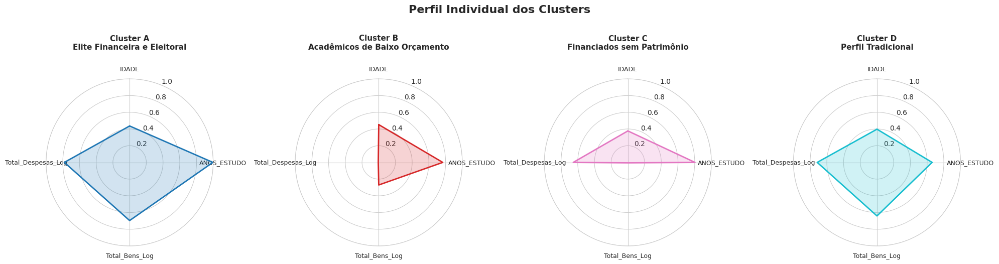

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

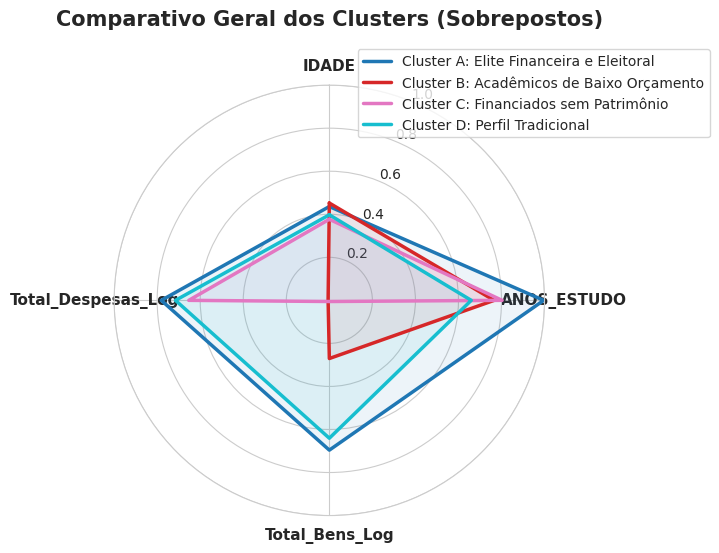

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
from math import pi
import matplotlib.pyplot as plt
import numpy as np

# --- 1. CONFIGURAÇÕES GERAIS ---
k_bisecting = 4
letras_ordenadas = [chr(65 + i) for i in range(k_bisecting)]  # Gera ['A', 'B', 'C', 'D', 'E']

cols_radar = ['IDADE', 'ANOS_ESTUDO', 'Total_Bens_Log', 'Total_Despesas_Log']

cores_radar = {
    'A': '#1f77b4',  # Azul
    'B': '#d62728',  # Vermelho
    'C': '#e377c2',  # Rosa
    'D': '#17becf',  # Ciano
}

# --- 2. CÁLCULO E NORMALIZAÇÃO DOS CENTROIDES ---
df_radar = df_cluster[cols_radar].copy()
df_radar = (df_radar - df_radar.min()) / (df_radar.max() - df_radar.min())
df_radar['cluster_letra'] = df_cluster['cluster_bisecting']

centroides_df = df_radar.groupby('cluster_letra')[cols_radar].mean().loc[letras_ordenadas]

# Preparação dos ângulos
n_eixos = len(cols_radar)
angulos = [n / float(n_eixos) * 2 * pi for n in range(n_eixos)]
angulos += angulos[:1]  # Fechar o polígono


# ==============================================================================
# PARTE 1: GRÁFICOS SEPARADOS (UM RADAR POR CLUSTER)
# ==============================================================================
ncols = 3 if k_bisecting > 4 else 4
nrows = -(-k_bisecting // ncols)

fig_sep, axes_sep = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 5 * nrows), subplot_kw=dict(polar=True)
)
axes_sep = np.array(axes_sep).flatten() if k_bisecting > 1 else [axes_sep]

for i, letra in enumerate(letras_ordenadas):
    ax = axes_sep[i]
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(cols_radar, fontsize=9)
    ax.set_ylim(0, 1)

    valores = centroides_df.loc[letra, cols_radar].values.tolist()
    valores += valores[:1]

    cor = cores_radar.get(letra, '#333333')
    ax.plot(angulos, valores, linewidth=2, color=cor)
    ax.fill(angulos, valores, alpha=0.2, color=cor)

    nome_descritivo = NOMES_CLUSTER_BISECTING.get(letra, "")
    ax.set_title(
        f"Cluster {letra}\n{nome_descritivo}",
        y=1.15,
        fontsize=11,
        fontweight="bold"
    )

# Deleta eixos extras da grade se houver
for j in range(len(letras_ordenadas), len(axes_sep)):
    fig_sep.delaxes(axes_sep[j])

fig_sep.suptitle("Perfil Individual dos Clusters", fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


# ==============================================================================
# PARTE 2: GRÁFICO COMPARATIVO (TODOS OS CLUSTERS JUNTOS)
# ==============================================================================
fig_junto, ax_junto = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

ax_junto.set_theta_offset(pi / 2)
ax_junto.set_theta_direction(-1)
ax_junto.set_xticks(angulos[:-1])
ax_junto.set_xticklabels(cols_radar, fontsize=11, fontweight='bold')
ax_junto.set_ylim(0, 1)

for letra in letras_ordenadas:
    valores = centroides_df.loc[letra, cols_radar].values.tolist()
    valores += valores[:1]

    cor = cores_radar.get(letra, '#333333')
    label_txt = f"Cluster {letra}: {NOMES_CLUSTER_BISECTING.get(letra, '')}"

    ax_junto.plot(angulos, valores, linewidth=2.5, label=label_txt, color=cor)
    ax_junto.fill(angulos, valores, alpha=0.08, color=cor)

plt.title("Comparativo Geral dos Clusters (Sobrepostos)", y=1.12, fontsize=15, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

## Isolation Forest: como funciona

Todos os algoritmos das fases anteriores definem "normal" de forma indireta: K-Means olha distância até um centro, DBSCAN olha densidade de vizinhança. O **Isolation Forest** faz a pergunta ao contrário, e de forma bem mais direta: **quão fácil é isolar este ponto do resto, cortando o espaço aleatoriamente?**

A ideia, passo a passo:

1. Constrói várias **árvores de isolamento** (isolation trees). Cada árvore escolhe, em cada nó, uma variável **aleatória** e um ponto de corte **aleatório** entre o mínimo e o máximo daquela variável ali — sem nenhuma lógica de "melhor corte" como numa árvore de decisão comum.
2. Repete o corte recursivamente até que cada ponto fique sozinho numa partição.
3. Pontos **isolados** (poucos e diferentes do resto) tendem a cair sozinhos logo nos primeiros cortes — **caminho curto** da raiz até a folha. Pontos numa região **densa** (muitos vizinhos parecidos) precisam de muito mais cortes até se separarem de todo mundo — **caminho longo**.
4. O **score de anomalia** de cada ponto é a média do comprimento desse caminho em todas as árvores da floresta, normalizada — quanto **menor** o caminho médio, mais anômalo.

Duas vantagens práticas: não precisa calcular distância entre todos os pares de pontos (como DBSCAN/hierárquico), então escala bem; e não assume nenhuma forma pro que é "normal" (nem esférica, como K-Means, nem uma região densa contígua, como DBSCAN).

**O parâmetro `contamination`** é a fração de pontos que vocês **esperam de antemão** que sejam anômalos — é uma suposição de quem está modelando, não algo medido a partir dos dados (mesmo espírito do `k` do K-Means ou do `eps` do DBSCAN: um parâmetro que exige julgamento, não tem uma resposta "correta" automática).

### Vendo com dados fictícios

Como com dado real nunca sabemos de verdade quem é anômalo, geramos aqui uma base fictícia onde **nós** decidimos quem é "normal" (dois grupos bem comportados) e quem é "anômalo" (pontos espalhados aleatoriamente pelo espaço) — aí comparamos com o que o algoritmo encontra sozinho, sem ver esses rótulos.


In [ ]:


rng = np.random.default_rng(SEMENTE)

# "normal": dois grupos bem comportados (como se fossem 2 clusters)
normal_1 = rng.normal(loc=[2, 2], scale=0.6, size=(80, 2))
normal_2 = rng.normal(loc=[6, 6], scale=0.6, size=(80, 2))
X_normal_ficticio = np.vstack([normal_1, normal_2])

# "anômalo": pontos espalhados aleatoriamente pelo espaço, longe dos dois grupos
X_anomalo_ficticio = rng.uniform(low=-2, high=10, size=(12, 2))

X_ficticio = np.vstack([X_normal_ficticio, X_anomalo_ficticio])
rotulo_real_ficticio = np.array(['Normal'] * len(X_normal_ficticio) + ['Anômalo (fictício)'] * len(X_anomalo_ficticio))

# contamination = a fração real de anômalos fictícios (aqui podemos "trapacear" porque sabemos)
iso_ficticio = IsolationForest(contamination=len(X_anomalo_ficticio) / len(X_ficticio),
                                random_state=SEMENTE, n_estimators=200)
pred_ficticio = iso_ficticio.fit_predict(X_ficticio)
score_ficticio = iso_ficticio.decision_function(X_ficticio)

print(f"Score médio — Normal: {score_ficticio[rotulo_real_ficticio == 'Normal'].mean():.3f}  |  "
      f"Anômalo: {score_ficticio[rotulo_real_ficticio == 'Anômalo (fictício)'].mean():.3f}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Score médio — Normal: 0.132  |  Anômalo: -0.092


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

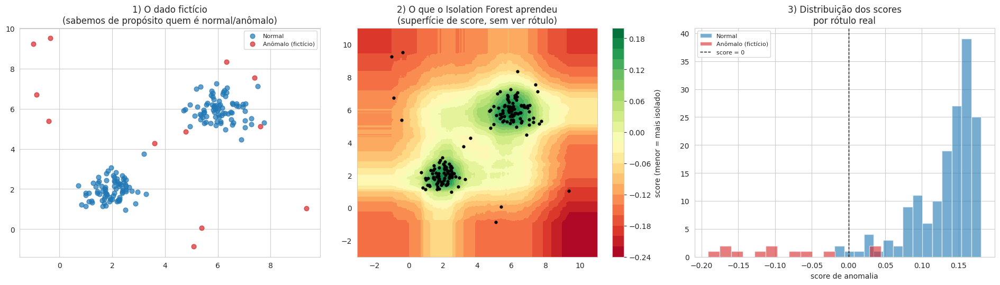

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

cores_ficticio = {'Normal': 'tab:blue', 'Anômalo (fictício)': 'tab:red'}
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[0].scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, label=rotulo, alpha=0.7, s=40)
axes[0].set_title('1) O dado fictício\n(sabemos de propósito quem é normal/anômalo)')
axes[0].legend(fontsize=8)

# superfície de score: o que o algoritmo "enxerga", sem ver rótulo nenhum
xx, yy = np.meshgrid(np.linspace(-3, 11, 300), np.linspace(-3, 11, 300))
Z = iso_ficticio.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
cs = axes[1].contourf(xx, yy, Z, levels=20, cmap='RdYlGn')
axes[1].scatter(X_ficticio[:, 0], X_ficticio[:, 1], c='black', s=12)
plt.colorbar(cs, ax=axes[1], label='score (menor = mais isolado)')
axes[1].set_title('2) O que o Isolation Forest aprendeu\n(superfície de score, sem ver rótulo)')

# distribuição dos scores por rótulo real
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    axes[2].hist(score_ficticio[m], bins=15, color=cor, alpha=0.6, label=rotulo)
axes[2].axvline(0, color='black', linestyle='--', linewidth=1, label='score = 0')
axes[2].set_title('3) Distribuição dos scores\npor rótulo real')
axes[2].set_xlabel('score de anomalia')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


A superfície de score (painel 2) fica **verde** (score alto, "normal") bem em cima dos dois grupos densos, e **vermelha** (score baixo, "anômalo") nas bordas e longe de tudo — exatamente onde estão os pontos fictícios que geramos como "anômalos". O algoritmo nunca viu o rótulo `Normal`/`Anômalo (fictício)`: ele chegou nisso só de contar quão rápido cada ponto fica isolado. O histograma (painel 3) mostra a mesma coisa de outro ângulo: os scores dos pontos normais ficam concentrados bem acima de zero; os anômalos, misturados mais pra baixo — a separação não é perfeita (alguns anômalos fictícios caíram por sorte perto dos grupos densos), o que já é um bom aviso pra quando aplicarmos em dado real: o Isolation Forest não é infalível, é uma sugestão de onde olhar com mais atenção.


### Por dentro de uma única árvore

A superfície de score acima é o resultado **já combinado** de 200 árvores. Pra enxergar o mecanismo de verdade — os cortes aleatórios que dão nome ao algoritmo — olhamos uma árvore sozinha: cada linha abaixo é um corte (variável aleatória, ponto de corte aleatório entre o mínimo e o máximo ali). Escolhemos dois pontos de propósito — um bem no meio de um grupo denso, outro o mais "anômalo" segundo o próprio modelo — e comparamos quantos cortes cada um precisou até ficar sozinho numa partição.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

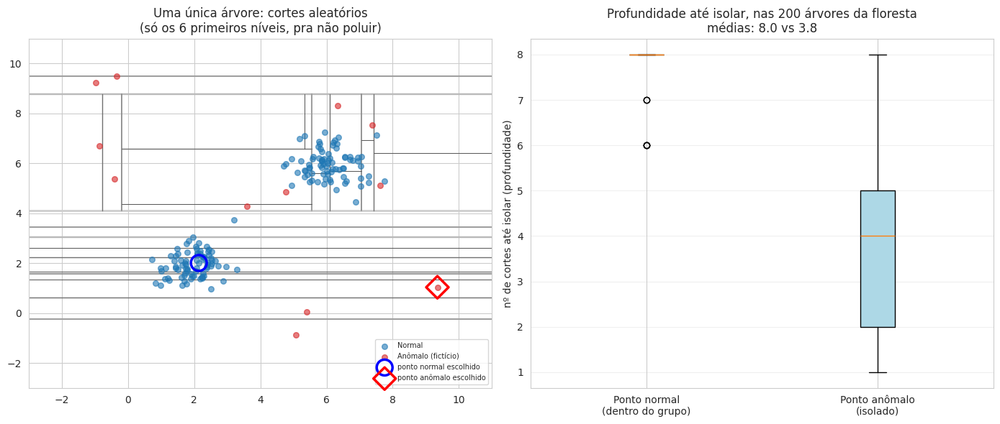

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
def desenhar_particoes(ax, tree_, no, x_min, x_max, y_min, y_max, profundidade=0, profundidade_max=6):
    """Desenha recursivamente os cortes de uma árvore de isolamento dentro de uma caixa
    [x_min,x_max] x [y_min,y_max]. Só os primeiros `profundidade_max` níveis são desenhados —
    a árvore de verdade continua até isolar cada ponto sozinho, mas isso poluiria demais o
    desenho sem ajudar a entender a ideia."""
    if profundidade >= profundidade_max or tree_.children_left[no] == -1:  # -1 = folha
        return
    variavel, limiar = tree_.feature[no], tree_.threshold[no]
    cor = plt.cm.Greys(0.3 + 0.5 * profundidade / profundidade_max)
    espessura = max(2 - 0.25 * profundidade, 0.4)
    if variavel == 0:
        ax.plot([limiar, limiar], [y_min, y_max], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, limiar, y_min, y_max, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], limiar, x_max, y_min, y_max, profundidade + 1, profundidade_max)
    else:
        ax.plot([x_min, x_max], [limiar, limiar], color=cor, linewidth=espessura)
        desenhar_particoes(ax, tree_, tree_.children_left[no], x_min, x_max, y_min, limiar, profundidade + 1, profundidade_max)
        desenhar_particoes(ax, tree_, tree_.children_right[no], x_min, x_max, limiar, y_max, profundidade + 1, profundidade_max)


def profundidade_isolamento(tree_, ponto):
    """Quantos cortes uma árvore precisa até isolar `ponto` sozinho numa folha."""
    no, profundidade = 0, 0
    while tree_.children_left[no] != -1:
        variavel, limiar = tree_.feature[no], tree_.threshold[no]
        no = tree_.children_left[no] if ponto[variavel] <= limiar else tree_.children_right[no]
        profundidade += 1
    return profundidade


# dois pontos escolhidos de propósito: o mais "normal" (mais perto do centro do 1º grupo) e o
# mais "anômalo" de verdade segundo o próprio modelo (menor score entre os pontos fictícios)
ponto_normal = X_normal_ficticio[np.argmin(np.linalg.norm(X_normal_ficticio - [2, 2], axis=1))]
scores_dos_anomalos = iso_ficticio.decision_function(X_anomalo_ficticio)
ponto_anomalo = X_anomalo_ficticio[np.argmin(scores_dos_anomalos)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# painel A: uma única árvore da floresta, cortes desenhados
ax = axes[0]
x_min, x_max, y_min, y_max = -3, 11, -3, 11
uma_arvore = iso_ficticio.estimators_[0].tree_
desenhar_particoes(ax, uma_arvore, 0, x_min, x_max, y_min, y_max)
for rotulo, cor in cores_ficticio.items():
    m = rotulo_real_ficticio == rotulo
    ax.scatter(X_ficticio[m, 0], X_ficticio[m, 1], c=cor, alpha=0.6, s=30, label=rotulo, zorder=3)
ax.scatter(*ponto_normal, s=250, facecolor='none', edgecolor='blue', linewidth=2.5, zorder=4, label='ponto normal escolhido')
ax.scatter(*ponto_anomalo, s=250, facecolor='none', edgecolor='red', linewidth=2.5, marker='D', zorder=4, label='ponto anômalo escolhido')
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_title('Uma única árvore: cortes aleatórios\n(só os 6 primeiros níveis, pra não poluir)')
ax.legend(fontsize=7, loc='lower right')

# painel B: profundidade até isolar cada um dos 2 pontos, em TODAS as árvores da floresta
profundidades_normal = [profundidade_isolamento(arv.tree_, ponto_normal) for arv in iso_ficticio.estimators_]
profundidades_anomalo = [profundidade_isolamento(arv.tree_, ponto_anomalo) for arv in iso_ficticio.estimators_]

ax2 = axes[1]
ax2.boxplot([profundidades_normal, profundidades_anomalo],
            tick_labels=['Ponto normal\n(dentro do grupo)', 'Ponto anômalo\n(isolado)'],
            patch_artist=True, boxprops=dict(facecolor='lightblue'))
ax2.set_ylabel('nº de cortes até isolar (profundidade)')
ax2.set_title(f'Profundidade até isolar, nas {len(iso_ficticio.estimators_)} árvores da floresta\n'
              f'médias: {np.mean(profundidades_normal):.1f} vs {np.mean(profundidades_anomalo):.1f}')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


No painel A, repare que os cortes se acumulam (linhas mais escuras e grossas, dos primeiros níveis) tentando separar os dois grupos densos um do outro — é preciso *bastante* corte aleatório até isolar alguém que está cercado de vizinhos parecidos. Já nas regiões vazias, um corte já sobra bastante espaço sozinho.

O painel B mostra a consequência disso, com números de verdade: o ponto normal escolhido precisa, em média, de **quase o dobro** de cortes pra ficar isolado, comparado ao ponto anômalo. Repare também que a profundidade **varia bastante de árvore pra árvore** (a caixa do anômalo vai de 1 a 8 cortes) — cada árvore sorteou cortes diferentes, então uma única árvore pode "errar" por sorte. É exatamente por isso que o algoritmo tira a **média de centenas de árvores**, em vez de confiar numa só: no agregado, o padrão (caminho curto = anômalo) se sustenta, mesmo que árvore isolada nenhuma seja confiável sozinha.


---
## Detecção global: quem foge do padrão geral da base?

Reaproveitamos exatamente as mesmas 4 variáveis-driver já padronizadas na Fase 2 (`X`: `IDADE`, `ANOS_ESTUDO`, `Total_Bens_Log`) — mesma pergunta de negócio, agora olhando pra quem está nas bordas em vez de procurar grupos. Adicionada a variável 'Total_Despesas_Log'.

Antes de fixar `contamination`, vale ver como o número de candidatos sinalizados muda conforme a suposição:


In [ ]:
for cont in [0.02, 0.03, 0.05, 0.08, 'auto']:
    iso_teste = IsolationForest(contamination=cont, random_state=SEMENTE, n_estimators=200)
    pred_teste = iso_teste.fit_predict(X)
    n_atipicos = int((pred_teste == -1).sum())
    print(f"contamination={cont!s:>6}: {n_atipicos:3d} atípicos de {len(X)} ({n_atipicos / len(X):.1%})")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

contamination=  0.02:  56 atípicos de 2800 (2.0%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

contamination=  0.03:  84 atípicos de 2800 (3.0%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

contamination=  0.08: 224 atípicos de 2800 (8.0%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

contamination=  auto: 1044 atípicos de 2800 (37.3%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

O modo `'auto'` do scikit-learn usa uma heurística própria (baseada no paper original do Isolation Forest) que, nesta base pequena e sem outliers extremos (já filtramos os piores casos de patrimônio na Fase 0/2), acaba marcando cerca de 1 em cada 3 candidatos como "atípico" — claramente alto demais pra ser útil. Fixamos `contamination=0.05` (5%, ~10 candidatos): sinaliza um grupo pequeno o bastante pra examinar um por um, sem descartar a possibilidade de que existam mais.


In [ ]:
contamination_global = 0.05  # ajuste conforme a célula anterior, se quiser um recorte maior/menor

iso_global = IsolationForest(contamination=contamination_global, random_state=SEMENTE, n_estimators=200)
pred_global = iso_global.fit_predict(X)
score_global = iso_global.decision_function(X)

df_cluster['anomalia_global'] = np.where(pred_global == -1, 'Atípico', 'Típico')
df_cluster['score_global'] = score_global

n_atipicos_global = (df_cluster['anomalia_global'] == 'Atípico').sum()
print(f"{n_atipicos_global} candidatos atípicos na base inteira (contamination={contamination_global})")

colunas_ficha_anomalia = ['NM_URNA_CANDIDATO', 'SG_PARTIDO', 'IDADE', 'ANOS_ESTUDO', 'Total_Bens', 'Total_Despesas','cluster']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

140 candidatos atípicos na base inteira (contamination=0.05)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Lista de atípicos (visão global)


In [ ]:
atipicos_globais = df_cluster[df_cluster['anomalia_global'] == 'Atípico'] \
    .sort_values('score_global')[colunas_ficha_anomalia + ['score_global']]

atipicos_globais


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Despesas,cluster,score_global
1284,CLEBIO LOPES JACARÉ,UNIÃO,56,4,57065162.25,1721235.48,Perfil Tradicional,-0.110075
1243,LOURIVAL GOMES,PSD,71,1,6608789.03,153876.00,Perfil Tradicional,-0.104879
1360,ORLANDO CARIOCA,PT,79,4,185000.00,0.00,Acadêmicos de Baixo Orçamento,-0.093502
607,LÁZARO MOTORISTA,AVANTE,30,4,185000.00,0.00,Acadêmicos de Baixo Orçamento,-0.084229
455,HELENO BALA,PSDB,32,4,72750.00,0.00,Acadêmicos de Baixo Orçamento,-0.083018
...,...,...,...,...,...,...,...,...
2647,ALCIDES SPINELLO,AGIR,78,11,0.00,0.00,Acadêmicos de Baixo Orçamento,-0.004510
2025,LUCAS PENTEADO,PT,29,11,1200.00,279841.47,Perfil Tradicional,-0.003249
1317,CAROL NUNES,UNIÃO,31,11,0.00,1017622.60,Financiados sem Patrimônio,-0.003065
112,AMANDA DE ROSA,SOLIDARIEDADE,26,9,0.00,0.00,Acadêmicos de Baixo Orçamento,-0.001379


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Onde esses candidatos aparecem, visualmente


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

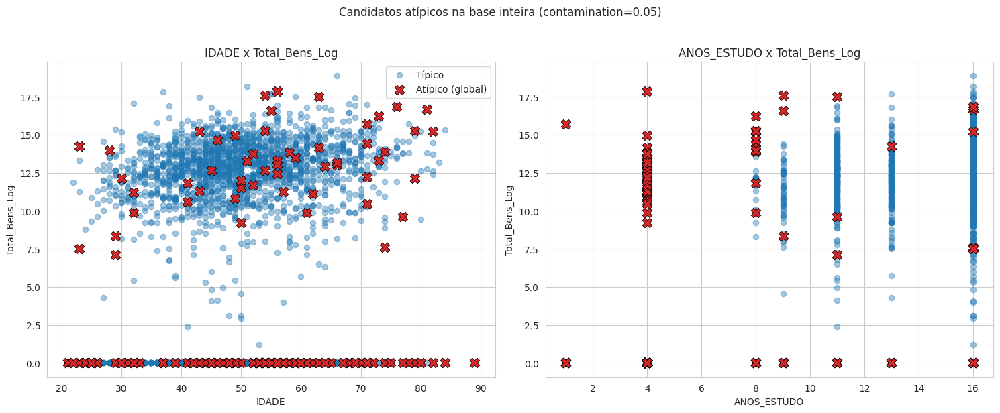

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

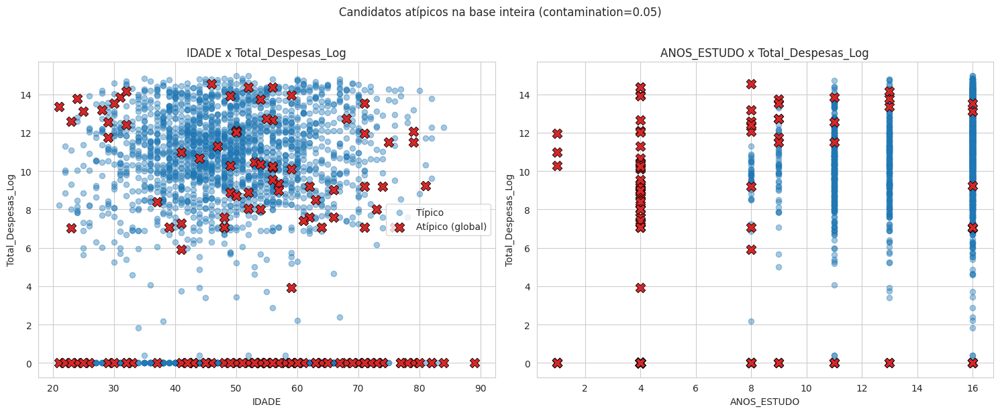

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (x_col, y_col) in zip(axes, [('IDADE', 'Total_Bens_Log'), ('ANOS_ESTUDO', 'Total_Bens_Log')]):
    tipicos = df_cluster[df_cluster['anomalia_global'] == 'Típico']
    atipicos = df_cluster[df_cluster['anomalia_global'] == 'Atípico']
    ax.scatter(tipicos[x_col], tipicos[y_col], c='tab:blue', alpha=0.4, s=35, label='Típico')
    ax.scatter(atipicos[x_col], atipicos[y_col], c='tab:red', marker='X', s=110,
               edgecolor='black', linewidth=0.6, label='Atípico (global)')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} x {y_col}')

axes[0].legend()
plt.suptitle(f'Candidatos atípicos na base inteira (contamination={contamination_global})', y=1.02)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (x_col, y_col) in zip(axes, [('IDADE', 'Total_Despesas_Log'), ('ANOS_ESTUDO', 'Total_Despesas_Log')]):
    tipicos = df_cluster[df_cluster['anomalia_global'] == 'Típico']
    atipicos = df_cluster[df_cluster['anomalia_global'] == 'Atípico']
    ax.scatter(tipicos[x_col], tipicos[y_col], c='tab:blue', alpha=0.4, s=35, label='Típico')
    ax.scatter(atipicos[x_col], atipicos[y_col], c='tab:red', marker='X', s=110,
               edgecolor='black', linewidth=0.6, label='Atípico (global)')
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} x {y_col}')

axes[0].legend()
plt.suptitle(f'Candidatos atípicos na base inteira (contamination={contamination_global})', y=1.02)
plt.tight_layout()
plt.show()


### O mesmo recorte, em 3D

As duas variáveis de cada vez (painel acima) escondem alguma coisa: dois candidatos podem parecer próximos no plano `IDADE` x `Total_Bens_Log` e estar bem longe um do outro na terceira variável (`ANOS_ESTUDO`). Como o modelo usa as **4 variáveis-driver ao mesmo tempo**, um gráfico 3D interativo mostra isso escondendo uma dimensão — arrastem pra rotacionar, passem o mouse num ponto pra ver quem é. O primeiro gráfico mostra Total_bens_log e oculta Total_Despesa_log, e no segundo gráfico se invertem.


In [ ]:
import plotly.graph_objects as go

cores_iso = {'Típico': '#1f77b4', 'Atípico': '#d62728'}

fig3d = go.Figure()
for status, cor in cores_iso.items():
    sub = df_cluster[df_cluster['anomalia_global'] == status]
    fig3d.add_trace(go.Scatter3d(
        x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
        mode='markers', name=status,
        marker=dict(
            size=6 if status == 'Típico' else 9,
            color=cor,
            symbol='circle' if status == 'Típico' else 'diamond',
            opacity=0.5 if status == 'Típico' else 0.95,
            line=dict(width=1, color='black'),
        ),
        text=sub['NM_URNA_CANDIDATO'] + ' — ' + sub['cluster'],
        hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
    ))

fig3d.update_layout(
    scene=dict(xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log'),
    title=f'Candidatos atípicos (visão global) nas 3 das 4 variáveis-driver (contamination={contamination_global})',
    height=650, margin=dict(l=0, r=0, b=0, t=40),
)
fig3d.show()



A saída de streaming foi truncada nas últimas 5000 linhas.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utc

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

In [ ]:
cores_iso = {'Típico': '#1f77b4', 'Atípico': '#d62728'}

fig3d = go.Figure()
for status, cor in cores_iso.items():
    sub = df_cluster[df_cluster['anomalia_global'] == status]
    fig3d.add_trace(go.Scatter3d(
        x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Despesas_Log'],
        mode='markers', name=status,
        marker=dict(
            size=6 if status == 'Típico' else 9,
            color=cor,
            symbol='circle' if status == 'Típico' else 'diamond',
            opacity=0.5 if status == 'Típico' else 0.95,
            line=dict(width=1, color='black'),
        ),
        text=sub['NM_URNA_CANDIDATO'] + ' — ' + sub['cluster'],
        hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
    ))

fig3d.update_layout(
    scene=dict(xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Despesas_Log'),
    title=f'Candidatos atípicos (visão global) nas 3-4 variáveis-driver (contamination={contamination_global})',
    height=650, margin=dict(l=0, r=0, b=0, t=40),
)
fig3d.show()

---
## Detecção dentro de cada cluster: quem foge do padrão do próprio grupo?


In [ ]:


resultados_cluster = []

for nome in df_cluster['cluster'].unique():
    sub_idx = df_cluster.index[df_cluster['cluster'] == nome].to_numpy()
    n = len(sub_idx)

    X_cluster = df_cluster.loc[sub_idx, colunas_driver].values
    X_cluster_padronizado = StandardScaler().fit_transform(X_cluster)

    contaminacao_cluster = min(max(0.05, 2 / n), 0.5)
    iso_cluster = IsolationForest(contamination=contaminacao_cluster, random_state=SEMENTE, n_estimators=200)
    pred_cluster = iso_cluster.fit_predict(X_cluster_padronizado)
    score_cluster = iso_cluster.decision_function(X_cluster_padronizado)

    n_atipicos = int((pred_cluster == -1).sum())
    print(f"{nome} (n={n}, contamination={contaminacao_cluster:.3f}): {n_atipicos} atípicos dentro do grupo")

    resultados_cluster.append(pd.DataFrame({
        'indice_original': sub_idx,
        'anomalia_cluster': np.where(pred_cluster == -1, 'Atípico', 'Típico'),
        'score_cluster': score_cluster,
    }))

anomalia_cluster_df = pd.concat(resultados_cluster).set_index('indice_original').sort_index()
df_cluster['anomalia_cluster'] = anomalia_cluster_df['anomalia_cluster'].values
df_cluster['score_cluster'] = anomalia_cluster_df['score_cluster'].values


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

Acadêmicos de Baixo Orçamento (n=795, contamination=0.050): 40 atípicos dentro do grupo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

Financiados sem Patrimônio (n=515, contamination=0.050): 26 atípicos dentro do grupo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

Elite Financeira e Eleitoral (n=1127, contamination=0.050): 57 atípicos dentro do grupo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

Perfil Tradicional (n=363, contamination=0.050): 19 atípicos dentro do grupo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

In [ ]:
for nome in df_cluster['cluster'].unique():
    print(f"--- {nome}: mais atípicos dentro do grupo ---")
    sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == 'Atípico')]
    display(sub.sort_values('score_cluster')[colunas_ficha_anomalia + ['score_cluster']])


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

--- Acadêmicos de Baixo Orçamento: mais atípicos dentro do grupo ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Despesas,cluster,score_cluster
2015,GREGORY FRANÇA,PT,25,16,10967.14,400.00,Acadêmicos de Baixo Orçamento,-0.153772
9,SIDIMAR DO MERCADINHO,NOVO,41,8,135000.00,370.00,Acadêmicos de Baixo Orçamento,-0.140811
1462,IGOR OLIVEIRA,MISSÃO,30,13,75000.00,187.75,Acadêmicos de Baixo Orçamento,-0.130037
2769,MARCIO EMANECIO,DEMOCRATA,59,11,13000.00,1160.00,Acadêmicos de Baixo Orçamento,-0.118526
708,PASTOR JÚLIO CÉSAR,PSD,54,9,16000.00,288.00,Acadêmicos de Baixo Orçamento,-0.109527
2502,EDUARDO RIJO,PSDB,53,9,33000.00,150.00,Acadêmicos de Baixo Orçamento,-0.100217
780,DECINHO BOLSONARO DO BARREIRO,PODE,59,4,0.00,50.00,Acadêmicos de Baixo Orçamento,-0.100179
2590,ANDERSON GIMENES PAPAPENAL,AVANTE,41,13,0.00,41.02,Acadêmicos de Baixo Orçamento,-0.097034
660,VALDEMAR ABRAO,MISSÃO,55,11,30600.00,217.96,Acadêmicos de Baixo Orçamento,-0.090202
2596,RAMOS,AVANTE,44,13,32000.00,50.00,Acadêmicos de Baixo Orçamento,-0.089732


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

--- Perfil Tradicional: mais atípicos dentro do grupo ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Despesas,cluster,score_cluster
1284,CLEBIO LOPES JACARÉ,UNIÃO,56,4,57065162.25,1721235.48,Perfil Tradicional,-0.129352
1243,LOURIVAL GOMES,PSD,71,1,6608789.03,153876.00,Perfil Tradicional,-0.120200
604,VITAL HONORATO,AVANTE,79,8,4220000.00,173269.51,Perfil Tradicional,-0.059029
1573,RICARDO ABRÃO,PSDB,54,9,44497052.10,928896.23,Perfil Tradicional,-0.054950
1785,BAIANINHO DE MAUÁ,UNIÃO,52,4,949466.00,1714196.60,Perfil Tradicional,-0.048872
1610,JUNINHO DO PNEU,PSDB,49,4,3110108.15,1092338.50,Perfil Tradicional,-0.048432
1449,ZOINHO,REPUBLICANOS,73,4,608700.04,3000.00,Perfil Tradicional,-0.045455
2419,COMENDADOR BRILHANTE,PDT,71,4,35000.00,10055.78,Perfil Tradicional,-0.045049
490,EMIDINHO MADEIRA,PL,59,4,714357.99,1144544.60,Perfil Tradicional,-0.036210
247,LUISINHO CORREDOR,PT,66,4,450000.00,2000.00,Perfil Tradicional,-0.031699


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

### O mesmo recorte, em 3D — filtrando por cluster

Mesma ideia do gráfico 3D global, agora um por cluster: escolham no menu qual grupo olhar (cada cluster usa a sua **própria** padronização, então os pontos vermelhos aqui são atípicos *dentro daquele grupo*, não em relação à base inteira). Os eixos ficam fixos entre um cluster e outro, pra dar pra comparar a posição relativa. 1º Considerando Total de Bens 2º Despesas


In [ ]:
nomes_bisecting_ordenados = list(df_cluster['cluster'].unique())
n_status = len(cores_iso)  # 'Típico' e 'Atípico', mesmas cores do gráfico 3D global

fig3d_cluster = go.Figure()
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    for status, cor in cores_iso.items():
        sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == status)]
        fig3d_cluster.add_trace(go.Scatter3d(
            x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Bens_Log'],
            mode='markers', name=status,
            marker=dict(
                size=6 if status == 'Típico' else 9,
                color=cor,
                symbol='circle' if status == 'Típico' else 'diamond',
                opacity=0.55 if status == 'Típico' else 0.95,
                line=dict(width=1, color='black'),
            ),
            text=sub['NM_URNA_CANDIDATO'],
            hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Bens_Log=%{z:.2f}<extra></extra>',
            visible=(idx_cluster == 0),       # só o primeiro cluster começa visível
            legendgroup=status,
            showlegend=(idx_cluster == 0),    # legenda não se repete a cada cluster
        ))

# um botão por cluster no menu suspenso — cada um liga só os 2 traços (Típico/Atípico) daquele cluster
botoes_cluster = []
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    visibilidade = [False] * (len(nomes_bisecting_ordenados) * n_status)
    for j in range(n_status):
        visibilidade[idx_cluster * n_status + j] = True
    botoes_cluster.append(dict(
        label=nome, method='update',
        args=[{'visible': visibilidade}, {'title': f'Atípicos dentro do cluster: {nome}'}],
    ))

fig3d_cluster.update_layout(
    scene=dict(
        xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log',
        xaxis=dict(range=[df_cluster['IDADE'].min() - 2, df_cluster['IDADE'].max() + 2]),
        yaxis=dict(range=[df_cluster['ANOS_ESTUDO'].min() - 1, df_cluster['ANOS_ESTUDO'].max() + 1]),
        zaxis=dict(range=[df_cluster['Total_Bens_Log'].min() - 0.5, df_cluster['Total_Bens_Log'].max() + 0.5]),
    ),
    updatemenus=[dict(active=0, buttons=botoes_cluster, x=0.02, y=1.05, xanchor='left')],
    title=f'Atípicos dentro do cluster: {nomes_bisecting_ordenados[0]}',
    height=650, margin=dict(l=0, r=0, b=0, t=60),
)
fig3d_cluster.show()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

In [ ]:
nomes_bisecting_ordenados = list(df_cluster['cluster'].unique())
n_status = len(cores_iso)  # 'Típico' e 'Atípico', mesmas cores do gráfico 3D global

fig3d_cluster = go.Figure()
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    for status, cor in cores_iso.items():
        sub = df_cluster[(df_cluster['cluster'] == nome) & (df_cluster['anomalia_cluster'] == status)]
        fig3d_cluster.add_trace(go.Scatter3d(
            x=sub['IDADE'], y=sub['ANOS_ESTUDO'], z=sub['Total_Despesas_Log'],
            mode='markers', name=status,
            marker=dict(
                size=6 if status == 'Típico' else 9,
                color=cor,
                symbol='circle' if status == 'Típico' else 'diamond',
                opacity=0.55 if status == 'Típico' else 0.95,
                line=dict(width=1, color='black'),
            ),
            text=sub['NM_URNA_CANDIDATO'],
            hovertemplate='<b>%{text}</b><br>IDADE=%{x}<br>ANOS_ESTUDO=%{y}<br>Total_Despesas_Log=%{z:.2f}<extra></extra>',
            visible=(idx_cluster == 0),       # só o primeiro cluster começa visível
            legendgroup=status,
            showlegend=(idx_cluster == 0),    # legenda não se repete a cada cluster
        ))

# um botão por cluster no menu suspenso — cada um liga só os 2 traços (Típico/Atípico) daquele cluster
botoes_cluster = []
for idx_cluster, nome in enumerate(nomes_bisecting_ordenados):
    visibilidade = [False] * (len(nomes_bisecting_ordenados) * n_status)
    for j in range(n_status):
        visibilidade[idx_cluster * n_status + j] = True
    botoes_cluster.append(dict(
        label=nome, method='update',
        args=[{'visible': visibilidade}, {'title': f'Atípicos dentro do cluster: {nome}'}],
    ))

fig3d_cluster.update_layout(
    scene=dict(
        xaxis_title='IDADE', yaxis_title='ANOS_ESTUDO', zaxis_title='Total_Bens_Log',
        xaxis=dict(range=[df_cluster['IDADE'].min() - 2, df_cluster['IDADE'].max() + 2]),
        yaxis=dict(range=[df_cluster['ANOS_ESTUDO'].min() - 1, df_cluster['ANOS_ESTUDO'].max() + 1]),
        zaxis=dict(range=[df_cluster['Total_Bens_Log'].min() - 0.5, df_cluster['Total_Despesas_Log'].max() + 0.5]),
    ),
    updatemenus=[dict(active=0, buttons=botoes_cluster, x=0.02, y=1.05, xanchor='left')],
    title=f'Atípicos dentro do cluster: {nomes_bisecting_ordenados[0]}',
    height=650, margin=dict(l=0, r=0, b=0, t=60),
)
fig3d_cluster.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

### Comparando: global vs. dentro do cluster

Quatro combinações possíveis pra cada candidato: atípico nos dois recortes (destoa de tudo, robusto), só globalmente, só dentro do cluster, ou típico nos dois. O caso mais interessante pedagogicamente é o **"só dentro do cluster"**: candidatos que passam despercebidos quando olhamos a base inteira, mas que não se parecem com seus próprios colegas de grupo.


In [ ]:
tabela_comparacao = pd.crosstab(df_cluster['anomalia_global'], df_cluster['anomalia_cluster'])
tabela_comparacao.index.name = 'anomalia_global \\ anomalia_cluster'
display(tabela_comparacao)

so_no_cluster = df_cluster[(df_cluster['anomalia_global'] == 'Típico') & (df_cluster['anomalia_cluster'] == 'Atípico')]
print(f"\n{len(so_no_cluster)} candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):")
so_no_cluster[colunas_ficha_anomalia + ['score_cluster']].sort_values('score_cluster')


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

anomalia_cluster,Atípico,Típico
anomalia_global \ anomalia_cluster,,
Atípico,59,81
Típico,83,2577


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v


83 candidatos são atípicos só DENTRO do próprio cluster (passariam despercebidos na análise global):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



,NM_URNA_CANDIDATO,SG_PARTIDO,IDADE,ANOS_ESTUDO,Total_Bens,Total_Despesas,cluster,score_cluster
1173,LUCIANO GUERREIRO,MDB,55,13,47295510.76,75362.66,Elite Financeira e Eleitoral,-0.164128
918,ROBERTO MONTEIRO-PAI,PL,69,13,250000.00,2106632.10,Elite Financeira e Eleitoral,-0.157976
2015,GREGORY FRANÇA,PT,25,16,10967.14,400.00,Acadêmicos de Baixo Orçamento,-0.153772
484,FABINHO RAMALHO,PL,64,13,20023780.20,472392.68,Elite Financeira e Eleitoral,-0.151896
93,IRINY,PT,70,13,180000.00,1071164.88,Elite Financeira e Eleitoral,-0.148072
...,...,...,...,...,...,...,...,...
1806,ANADETHY,MDB,62,16,32000.00,849.38,Elite Financeira e Eleitoral,-0.001605
661,CARLOS HENRIQUE DIAS,MISSÃO,24,13,6494.60,4671.78,Perfil Tradicional,-0.001530
281,DARIO FERREIRA,REPUBLICANOS,68,16,24075000.00,12000.00,Elite Financeira e Eleitoral,-0.000871
1246,MARIA ANGELICA,PSD,70,13,1200000.00,1400.00,Perfil Tradicional,-0.000825


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future v

---
## Fechamento

Com esta Fase 4, fecha-se o pipeline completo: preparação de dados (Fase 0), análise descritiva (Fase 1), clusterização — K-Means, Bisecting K-Means, DBSCAN e hierárquico (Fase 2), regras de associação (Fase 3) e, agora, detecção de anomalias, tanto na base inteira quanto dentro de cada cluster nomeado na Fase